
## 04 — LightGBM Final Forecasting & Optuna Optimization

**Project:** Agentic AI for Retail Demand & Inventory Decision Support  
**Course:** IDS 560 Capstone | Group 4 | Walmart M5 Forecasting Project

**Focus:** LightGBM Development · Feature Engineering · Chronological Validation · Optuna Optimization · Model Comparison · Forecast Reliability · RAG Integration

---

### 1. Notebook Overview

This notebook develops, optimizes, and evaluates a feature-based LightGBM demand forecasting framework using the Walmart M5 Forecasting dataset.

It builds on three preceding notebooks:

- **01 — Data Preparation:** Canonical sampling, data alignment, and chronological splitting.
- **02 — Baseline Forecasting & Error Analysis:** Reference forecasting models, error diagnostics, bias analysis, and prediction intervals.
- **03 — Statistical Model Exploration:** Croston, SBA, TSB, and SES/ETS model evaluation.

The objective is to determine whether LightGBM improves forecasting performance over simpler forecasting methods, and whether Optuna hyperparameter optimization provides additional value.

**The central goal is to select a reproducible, leakage-aware, and reliable forecasting model that supports downstream inventory analysis and RAG-based decision support.**

#### Dataset & Experimental Scope

| Component | Specification |
|---|---|
| Dataset | M5 Forecasting — Walmart-originated, Kaggle |
| Source Files | `sales_train_evaluation.csv`, `calendar.csv`, `sell_prices.csv` |
| Full Population | 30,490 item-store daily sales series |
| Geographic Coverage | California, Texas, Wisconsin |
| Product Categories | FOODS, HOUSEHOLD, HOBBIES |
| Prototype Sample | 100 series |
| Training Sample | 20% stratified sample — 6,098 series |
| Evaluation Samples | 20% and 50% — 6,098 / 15,245 series |
| Sampling Design | State × Category stratification; nested samples |
| Forecast Horizons | 7, 14, and 28 days |
| Downstream Integration | Inventory analysis and RAG decision support |

The existing sample manifests are reused without resampling.

---

### 2. LightGBM Modeling Framework

LightGBM is a gradient boosting decision-tree algorithm capable of learning nonlinear relationships and interactions among historical demand, product characteristics, calendar information, and selling prices.

Unlike simple moving-average models, LightGBM can learn shared demand patterns across multiple item-store series.

The original implementation uses a global supervised learning framework with a Tweedie regression objective, periodic retraining, and trailing bias correction.

#### Model Configuration

| Component | Original Implementation |
|---|---|
| Algorithm | LightGBM |
| Objective | Tweedie Regression |
| Tweedie Variance Power | 1.2 |
| Number of Estimators | 400 |
| Learning Rate | 0.05 |
| Number of Leaves | 63 |
| Feature Count | 28 |
| Training Origin Spacing | 28 days |
| Retraining Frequency | Approximately 91 days |
| Bias Correction | Trailing 13 weeks |
| Random State | 42 |
| Hyperparameter Optimization | Optuna — additional experiment |

The original LightGBM configuration is preserved as the reproducibility reference. Optuna is evaluated separately rather than replacing the original configuration before validation.


#### Feature Groups — Complete 28-Feature Specification

The original LightGBM model uses 28 features across seven groups. The specification below matches `LG_FEATURES` and `lg_features()`.

| Feature Group | Features | Count | Purpose |
|---|---|---:|---|
| Historical Demand & Variability | `m7`, `m14`, `m28`, `m56`, `m365`, `std28` | 6 | Capture recent and long-term demand levels and volatility. |
| Demand Sparsity & Recency | `zero28`, `zero365`, `days_since_sale`, `pos_mean56` | 4 | Describe zero-sales frequency, demand recency, and positive-sales intensity. |
| Weekly Seasonality & Forecast Lead | `sw_mean4`, `sw_last`, `lead` | 3 | Capture same-weekday demand patterns and forecast lead time. |
| Calendar & SNAP | `dow`, `dom`, `month`, `event`, `snap` | 5 | Represent calendar seasonality, event presence, and state-specific SNAP indicators. |
| Price Context | `price_t`, `price_ratio_56`, `price_change_vs_origin` | 3 | Represent target-date price and its relationship to historical and origin-date prices. |
| Product & Store Attributes | `cat`, `dept`, `store`, `state` | 4 | Capture product hierarchy and geographic/store-level heterogeneity. |
| Demand Characteristics | `demand_type`, `adi`, `cv2` | 3 | Describe training-based demand regularity and intermittency. |
| **Total** | **28 features** | **28** | **Original LightGBM specification.** |

**Feature availability:** Historical sales features are constructed from observations available at the forecast origin. Calendar and SNAP values are associated with the target date. Target-date selling prices are used by the original implementation and require a separate availability/leakage assessment before operational deployment.

**Model consistency:** Original LightGBM and Optuna LightGBM must use the same 28-feature specification for a hyperparameter-only comparison.


### 3. Chronological Evaluation Design

| Period | Date Range | Duration | Purpose |
|---|---|---|---|
| Training | Jan 29, 2011 – Dec 31, 2014 | 1,433 days | Initial model fitting |
| Validation | Jan 1 – Dec 31, 2015 | 365 days | Model evaluation, optimization, and selection |
| Held-Out Test | Jan 1 – May 22, 2016 | 143 days | Out-of-sample evaluation |

#### Shared Evaluation Rules

| Component | Method |
|---|---|
| Forecast Horizons | 7, 14, 28 days |
| Rolling-Origin Step | 7 days |
| Primary Metrics | WAPE, MAE, RMSE |
| Bias Evaluation | Signed bias and segmented bias |
| Forecast Value Added | Relative performance against simple baselines |
| Demand Classification | Training-only ADI/CV² |
| Validation Discipline | Model tuning and selection using 2015 |
| Test Discipline | Frozen configurations evaluated on 2016 |

The 2016 held-out test period is not used to tune Optuna hyperparameters or select a model retrospectively.

---

#### Forecasting Experiment — Four Stages

The forecasting experiment follows four sequential stages, from original model reproduction to final model evaluation and delivery.

| Stage | Focus | Methodology | Output |
|---|---|---|---|
| **A. Original LightGBM Reproduction** | Reproduce the original forecasting pipeline | Restore the original 28-feature engineering, Tweedie configuration, initial training, quarterly retraining, rolling-origin validation, and trailing bias correction. | Reproduced Original LightGBM and 2015 validation benchmark. |
| **B. Optuna Optimization** | Improve LightGBM hyperparameters | Optimize using 2015 validation data while keeping the feature pipeline and evaluation framework consistent with Original LightGBM. | Optuna-tuned LightGBM candidate. |
| **C. Final Model Comparison** | Select the best forecasting approach | Compare Recent Mean 7D, Recent Mean 28D, Original LightGBM, and Optuna LightGBM using aligned samples, forecast origins, horizons, and evaluation metrics. | Validation-based model selection. |
| **D. Independent Testing & Delivery** | Evaluate generalization and produce forecasts | Freeze the selected model configuration, evaluate on the 2016 holdout, assess forecast reliability, and generate 7/14/28-day outputs compatible with Dashboard and RAG. | Independent test results and final forecast artifacts. |

**Evaluation principle:** Model tuning and selection use 2015 validation data only. The 2016 holdout is reserved for independent evaluation after model selection.

---

### 5. Forecast Reliability & RAG Compatibility

Forecast quality is assessed using:

- Overall WAPE, MAE, and RMSE.
- Signed forecast bias and segmented error patterns.
- Forecast value added relative to Recent Mean baselines.
- Performance across demand types, states, and product categories.
- Robustness across evaluation horizons and sample sizes.
- Prediction interval coverage and calibration, where available.

#### RAG Integration Requirements

The final forecasting pipeline must preserve:

- Canonical item-store identifiers and sample ordering.
- Forecast origins, target dates, and lead-day definitions.
- Required forecast filenames and column schemas.
- Consistent demand-type classification.
- Model-specific forecast error and uncertainty evidence.
- Historical scenario forecasts used by the RAG agent.

Any transition from Original LightGBM to Optuna must update model-dependent forecasting and reliability artifacts together.

---


### 6. Notebook Organization

The notebook follows five phases and 13 sections, organized in the same order as the implementation: data restoration, model configuration, feature engineering, original model reproduction, optimization, independent testing, and forecast delivery.

| Phase | Section | Responsibility | Description |
|---|---:|---|---|
| **A. Data Reproducibility** | 1 | Environment & Canonical Data Loading | Load M5 sales, calendar, prices, and fixed sample manifests without resampling. |
| | 2 | Data Restoration & Integrity Validation | Restore chronological splits, sales matrices, baseline metrics, Demand Quantile and Demand Type classifications; validate sample and metadata alignment. |
| **B. Original LightGBM Reproduction** | 3 | Original LightGBM Configuration | Define original Tweedie hyperparameters, 28-feature specification, horizons, retraining settings, and evaluation segments. |
| | 4 | Feature Engineering & Model Functions | Construct all 28 features across seven groups; define feature context, training, and multi-horizon prediction functions. |
| | 5 | Original LightGBM Training & Reproduction | Reproduce baseline metrics, train the initial LightGBM, and define model acceptance criteria. |
| | 6 | Quarterly Retraining & 2015 Validation | Perform expanding-window retraining every 91 days, rolling-origin validation, trailing bias correction, and decision checks. |
| **C. Optimization & Model Selection** | 7 | Optuna Hyperparameter Optimization | Tune LightGBM hyperparameters using 2015 validation data with the same feature pipeline. |
| | 8 | Four-Model Validation Comparison | Compare Recent Mean 7D, Recent Mean 28D, Original LightGBM, and Optuna LightGBM on matched samples, origins, horizons, and metrics. |
| **D. Independent Testing & Reliability** | 9 | Frozen Model Evaluation on 2016 Holdout | Evaluate the validation-selected model configuration on the untouched 2016 test period. |
| | 10 | Forecast Bias & Reliability Analysis | Analyze WAPE, MAE, RMSE, signed bias, and demand-segment performance across horizons. |
| **E. Forecast Delivery & RAG Integration** | 11 | Multi-Horizon Final Forecast Generation | Generate daily 28-day forecasts and cumulative 7-, 14-, and 28-day demand summaries. |
| | 12 | Dashboard & RAG Output Compatibility | Preserve existing RAG forecast artifacts and validate new multi-horizon schemas and downstream interfaces. |
| | 13 | Final Findings & Model Selection | Summarize validation-based model selection, holdout results, forecast reliability, and inventory implications. |

**Methodological principle:** Model optimization and selection use 2015 validation data; the 2016 holdout is reserved for independent testing. Original LightGBM and Optuna LightGBM share the same 28-feature pipeline. Final forecasts support all three sponsor-requested planning horizons (7, 14, and 28 days).



---

#### Key Methodological Principles

- **Reproducibility:** Original LightGBM results must be reproduced before optimization.
- **Fair Comparison:** All four finalists must use consistent evaluation samples, forecast origins, horizons, and error definitions.
- **Leakage Prevention:** Optuna tuning and model selection use validation data, not the held-out test period.
- **Model Reliability:** Forecast accuracy, systematic bias, and uncertainty are considered separately.
- **RAG Compatibility:** Existing downstream files are preserved until candidate forecasts and reliability artifacts pass compatibility checks.

---

### 7. Expected Deliverables

| Deliverable | Purpose |
|---|---|
| Original LightGBM Metrics | Reproduce the existing forecasting reference |
| Optuna Optimization Results | Document search trials and selected parameters |
| Four-Model Comparison | Evaluate forecasting value and reliability |
| Final Model Decision | Document validation-based selection |
| Final Forecast Artifacts | Generate item-level predictions and uncertainty outputs |
| RAG Compatibility Checks | Validate downstream forecast interfaces |

**Overall Goal:** Develop a reproducible LightGBM forecasting workflow, evaluate the incremental value of Optuna optimization, and deliver reliable forecasting evidence for AI-assisted retail inventory decision support.


## 1.Environment & Canonical Data Loading

In [ ]:

import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
warnings.filterwarnings("ignore", category=RuntimeWarning)

SALES_FILE = "sales_train_evaluation.csv"

try:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=True)
except ImportError:
    pass

# Locate the shared data folder automatically (Shared drives or My Drive shortcuts).
# Leave BASE_PATH as None for auto-detection, or set it manually.
BASE_PATH = "/content/drive/MyDrive/IDS 560- Agentic AI & Inventory Project/M5 EDA/datasets/"

def find_datasets_folders():
    import glob
    found = []
    for root in ["/content/drive/Shareddrives/*", "/content/drive/MyDrive"]:
        for depth in range(0, 4):
            pattern = os.path.join(root, *(["*"] * depth), "M5 EDA", "datasets")
            found += [p for p in glob.glob(pattern) if os.path.isdir(p)]
    return found

if BASE_PATH is None:
    matches = find_datasets_folders()
    if not matches:
        raise FileNotFoundError(
            "Could not find 'M5 EDA/datasets' in your Shared drives or My Drive. "
            "One-time fix: in Google Drive open 'Shared with me', right-click the folder "
            "'IDS 560- Agentic AI & Inventory Project', choose Organize > Add shortcut > My Drive, then re-run this cell. "
            "(Or set BASE_PATH by hand above.)")
    BASE_PATH = matches[0].rstrip("/") + "/"
    print("Using data folder:", BASE_PATH)
    if len(matches) > 1:
        print("Other matching folders were ignored:", matches[1:])

missing = [f for f in ["calendar.csv", "sell_prices.csv", SALES_FILE] if not os.path.exists(BASE_PATH + f)]
if missing:
    raise FileNotFoundError(f"Missing in {BASE_PATH}: {missing}. Files found: {sorted(os.listdir(BASE_PATH))[:20]}")

NAVY, ACCENT, LIGHT, GRAY = "#142F52", "#3E75BC", "#8FB4E3", "#5D6B7B"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.labelsize": 10,
})

from pathlib import Path
Forecasting_OUTPUT = Path(
    "/content/drive/MyDrive/IDS 560- Agentic AI & Inventory Project/M5 Forecasting/M5_Forecasting_Outputs/"
)
Forecasting_OUTPUT.mkdir(parents=True, exist_ok=True)
print("Forecasting outputs:", Forecasting_OUTPUT)

def save_chart(name=None):
    plt.tight_layout()
    plt.show()


Mounted at /content/drive
Forecasting outputs: /content/drive/MyDrive/IDS 560- Agentic AI & Inventory Project/M5 Forecasting/M5_Forecasting_Outputs


In [ ]:
# Memory-efficient loading: small integer types for sales/weeks, float32 for prices, categories for IDs.
calendar = pd.read_csv(BASE_PATH + "calendar.csv", parse_dates=["date"])

prices = pd.read_csv(BASE_PATH + "sell_prices.csv",
                     dtype={"store_id": "category", "item_id": "category",
                            "wm_yr_wk": "int16", "sell_price": "float32"})

ID_COLS = ["id", "item_id", "dept_id", "cat_id", "store_id", "state_id"]
_header = pd.read_csv(BASE_PATH + SALES_FILE, nrows=1).columns
day_cols = [c for c in _header if c.startswith("d_")]
sales = pd.read_csv(BASE_PATH + SALES_FILE,
                    dtype={**{c: "category" for c in ID_COLS[1:]}, **{c: "int16" for c in day_cols}})

print("calendar:", calendar.shape, "| prices:", prices.shape, "| sales:", sales.shape)

calendar: (1969, 14) | prices: (6841121, 4) | sales: (30490, 1947)



### Data Alignment & Integrity Checks

In [ ]:
#Chronologically ordered sales columns
day_cols = sorted( [c for c in sales.columns if c.startswith("d_")],key=lambda c: int(c.split("_")[1]))

# Align calendar information with sales columns
cal_by_d = calendar.set_index("d")
dates = pd.DatetimeIndex(cal_by_d.loc[day_cols, "date"])
week_of_day = cal_by_d.loc[day_cols, "wm_yr_wk"].to_numpy()

#Preserve series identifiers for sampling
series = sales[ID_COLS].copy()
for c in ID_COLS[1:]:
    series[c] = series[c].astype(str)

#Basic dimensions
n_series = len(sales)
n_days = len(day_cols)

#Validate alignment
assert sales["id"].is_unique
assert cal_by_d.index.is_unique
assert dates.is_monotonic_increasing
assert dates.is_unique
assert len(dates) == n_days
# Check Item × Store uniqueness
assert not sales.duplicated(["item_id", "store_id"]).any(), "Duplicate Item-Store combinations"
# Check non-negative and non-missing sales
for start in range(0, len(sales), 1000):
    chunk = sales.iloc[start:start + 1000][day_cols].to_numpy()
    assert np.isfinite(chunk).all(), "Missing or invalid sales values"
    assert (chunk >= 0).all(), "Negative sales values"
print("Calendar alignment successful.")
print("Total series:", n_series)
print("Total days:", n_days)
print("Date range:", dates.min().date(), "to", dates.max().date())

Calendar alignment successful.
Total series: 30490
Total days: 1941
Date range: 2011-01-29 to 2016-05-22



## 2. Data Restoration & Integrity Validation

### 2.1 Restore Canonical Sample Manifests

Reuse the fixed prototype, 20%, and 50% stratified samples generated in Notebook 01. Validate sample sizes, unique series IDs, and nested membership without rerunning the sampling algorithm or overwriting existing manifests.

In [ ]:
# Restore canonical samples from Notebook 01; do not resample or overwrite manifests.
RANDOM_SEED = 42
PROTOTYPE_SIZE = 100
SAMPLE_FRACTIONS = (0.20, 0.50)
STRATA_COLS = ["state_id", "cat_id"]

series_base = series[ID_COLS].sort_values("id").reset_index(drop=True).copy()
sample_prototype = pd.read_csv(Forecasting_OUTPUT / "sample_prototype_manifest.csv")
sample_20 = pd.read_csv(Forecasting_OUTPUT / "sample_20_manifest.csv")
sample_50 = pd.read_csv(Forecasting_OUTPUT / "sample_50_manifest.csv")

assert len(series_base) == 30490 and series_base["id"].is_unique
assert len(sample_prototype) == 100 and len(sample_20) == 6098 and len(sample_50) == 15245
for name, df in [("prototype", sample_prototype), ("20%", sample_20), ("50%", sample_50)]:
    assert df["id"].is_unique, f"Duplicate IDs in {name}"
    assert set(df["id"]).issubset(set(series_base["id"])), f"Unknown IDs in {name}"

assert set(sample_prototype["id"]) <= set(sample_20["id"]) <= set(sample_50["id"])
print("Canonical manifests restored:", len(sample_prototype), len(sample_20), len(sample_50))
print("Nested sampling validation: PASSED")


Canonical manifests restored: 100 6098 15245
Nested sampling validation: PASSED


In [ ]:

# Validate canonical manifests restored from Notebook 01
expected_sizes = {"prototype": 100, "20%": 6098, "50%": 15245}
samples = {"prototype": sample_prototype, "20%": sample_20, "50%": sample_50}
full_ids = set(sales["id"])

for name, df in samples.items():
    assert len(df) == expected_sizes[name], f"{name}: unexpected sample size"
    assert df["id"].is_unique, f"{name}: duplicate IDs"
    assert set(df["id"]).issubset(full_ids), f"{name}: unknown series IDs"

assert set(sample_prototype["id"]) <= set(sample_20["id"]) <= set(sample_50["id"])

# Verify State × Category coverage against the original population
full_meta = sales[["id", "state_id", "cat_id"]].copy()
full_meta[["state_id", "cat_id"]] = full_meta[["state_id", "cat_id"]].astype(str)
full_counts = full_meta.groupby(["state_id", "cat_id"]).size().rename("full")
coverage = full_counts.to_frame()

for name, df in [("20", sample_20), ("50", sample_50)]:
    selected = full_meta[full_meta["id"].isin(df["id"])]
    coverage[f"sample_{name}"] = selected.groupby(["state_id", "cat_id"]).size()

coverage = coverage.fillna(0).astype(int).reset_index()
coverage["share_full"] = coverage["full"] / len(sales)
coverage["share_20"] = coverage["sample_20"] / len(sample_20)
coverage["share_50"] = coverage["sample_50"] / len(sample_50)
coverage["diff_20_pp"] = 100 * (coverage["share_20"] - coverage["share_full"])
coverage["diff_50_pp"] = 100 * (coverage["share_50"] - coverage["share_full"])

print("Canonical sample validation: PASSED")
print(coverage.round(4).to_string(index=False))


Canonical sample validation: PASSED
state_id    cat_id  full  sample_20  sample_50  share_full  share_20  share_50  diff_20_pp  diff_50_pp
      CA     FOODS  5748       1150       2874      0.1885    0.1886    0.1885      0.0066      0.0000
      CA   HOBBIES  2260        452       1130      0.0741    0.0741    0.0741      0.0000      0.0000
      CA HOUSEHOLD  4188        838       2094      0.1374    0.1374    0.1374      0.0066      0.0000
      TX     FOODS  4311        862       2156      0.1414    0.1414    0.1414     -0.0033      0.0033
      TX   HOBBIES  1695        339        848      0.0556    0.0556    0.0556      0.0000      0.0033
      TX HOUSEHOLD  3141        628       1571      0.1030    0.1030    0.1031     -0.0033      0.0033
      WI     FOODS  4311        862       2155      0.1414    0.1414    0.1414     -0.0033     -0.0033
      WI   HOBBIES  1695        339        847      0.0556    0.0556    0.0556      0.0000     -0.0033
      WI HOUSEHOLD  3141        628  

In [ ]:

# Canonical experiment consistency checks
assert len(sample_prototype) == 100 and len(sample_20) == 6098 and len(sample_50) == 15245
assert set(sample_prototype["id"]) <= set(sample_20["id"]) <= set(sample_50["id"])
assert sample_prototype["id"].is_unique and sample_20["id"].is_unique and sample_50["id"].is_unique
assert set(sample_50["id"]).issubset(set(sales["id"]))
assert len(day_cols) == 1941
assert calendar.set_index("d").loc[day_cols, "date"].is_monotonic_increasing
CANONICAL_HORIZONS = (7, 14, 28)
CANONICAL_STEP = 7
CANONICAL_TRAIN_END = pd.Timestamp("2014-12-31")
CANONICAL_VAL_END = pd.Timestamp("2015-12-31")
CANONICAL_TEST_END = pd.Timestamp("2016-05-22")
print("Canonical sample membership and date alignment: PASSED")
print("Horizons:", CANONICAL_HORIZONS, "| Rolling-origin step:", CANONICAL_STEP)


Canonical sample membership and date alignment: PASSED
Horizons: (7, 14, 28) | Rolling-origin step: 7


### 2.2 Canonical Sampling Validation

The fixed prototype (100), 20% (6,098), and 50% (15,245) samples are restored from Notebook 01 without resampling. Unique IDs, nested membership, and State × Category representation are validated to ensure consistent samples across forecasting models.


### 2.3 Chronological Splitting

Split the 1,941 daily observations into training (2011–2014), validation (2015), and held-out testing (2016), preserving the same date boundaries used in the baseline and statistical experiments.

In [ ]:
# Align calendar dates with M5 sales day columns
calendar_sales = calendar.set_index("d").loc[day_cols].copy()
calendar_sales["date"] = pd.to_datetime(calendar_sales["date"])
# Validate chronological order
assert calendar_sales["date"].is_monotonic_increasing
assert calendar_sales["date"].is_unique

# Train: 2011-01-29 to 2014-12-31
train_mask = (calendar_sales["date"] <= pd.Timestamp("2014-12-31"))
# Validation: all of 2015
val_mask = ((calendar_sales["date"] >= pd.Timestamp("2015-01-01"))& (calendar_sales["date"] <= pd.Timestamp("2015-12-31")))
# Test: 2016-01-01 to 2016-05-22
test_mask = (calendar_sales["date"] >= pd.Timestamp("2016-01-01"))
train_days = calendar_sales.index[train_mask].tolist()
val_days = calendar_sales.index[val_mask].tolist()
test_days = calendar_sales.index[test_mask].tolist()
print("Train:", len(train_days), "days")
print("Validation:", len(val_days), "days")
print("Test:", len(test_days), "days")

Train: 1433 days
Validation: 365 days
Test: 143 days


In [ ]:
# Check expected lengths
assert len(train_days) == 1433
assert len(val_days) == 365
assert len(test_days) == 143
# Check all days are assigned exactly once
assert len(train_days + val_days + test_days) == len(day_cols)
assert set(train_days).isdisjoint(val_days)
assert set(train_days).isdisjoint(test_days)
assert set(val_days).isdisjoint(test_days)
# Check the original chronological sequence is preserved
assert train_days + val_days + test_days == day_cols
# Check boundary dates
assert calendar_sales.loc[train_days[-1], "date"] == pd.Timestamp("2014-12-31")
assert calendar_sales.loc[val_days[0], "date"] == pd.Timestamp("2015-01-01")
assert calendar_sales.loc[val_days[-1], "date"] == pd.Timestamp("2015-12-31")
assert calendar_sales.loc[test_days[0], "date"] == pd.Timestamp("2016-01-01")

print("Chronological splitting: PASSED")

Chronological splitting: PASSED


In [ ]:
def get_sales_split(sales, sample_ids, period_cols):
    """
    Select specific item-store series and day columns.
    Rows: selected item-store series
    Columns: identifiers + selected dates
    """
    result = sales.loc[sales["id"].isin(sample_ids),ID_COLS + period_cols].copy()
    assert len(result) == len(sample_ids)
    assert result["id"].is_unique
    return result


### 2.4 Chronological Split Validation

All 1,941 days are assigned to non-overlapping chronological periods: 1,433 training days, 365 validation days, and 143 held-out test days. The same boundaries are maintained across forecasting experiments to support comparable evaluation and prevent temporal leakage.



### 2.5 Sample Preprocessing

Convert the canonical prototype, 20%, and 50% samples into aligned `float32` sales matrices covering training and validation periods. Preserve original series IDs and row ordering for LightGBM training and evaluation.

In [ ]:
# Preprocessing — Sample Selection & Sales Matrix
def preprocess_sample(sample_name):
    manifests = {"prototype": sample_prototype, "sample_20": sample_20, "sample_50": sample_50}
    manifest = manifests[sample_name]
    train_val_days = train_days + val_days
    sample_tv = get_sales_split(sales=sales, sample_ids=manifest["id"], period_cols=train_val_days)
    series_ids = sample_tv["id"].to_numpy()
    sales_matrix = sample_tv[train_val_days].to_numpy(dtype=np.float32)
    assert sales_matrix.shape == (len(manifest), len(train_val_days))
    assert len(np.unique(series_ids)) == len(series_ids)
    assert set(series_ids) == set(manifest["id"])
    assert np.isfinite(sales_matrix).all()
    assert (sales_matrix >= 0).all()
    print(f"Sample: {sample_name} | Series: {len(series_ids)} | Matrix: {sales_matrix.shape}")
    return series_ids, sales_matrix

prototype_ids, prototype_matrix = preprocess_sample("prototype")
sample20_ids, sample20_matrix = preprocess_sample("sample_20")
sample50_ids, sample50_matrix = preprocess_sample("sample_50")

Sample: prototype | Series: 100 | Matrix: (100, 1798)
Sample: sample_20 | Series: 6098 | Matrix: (6098, 1798)
Sample: sample_50 | Series: 15245 | Matrix: (15245, 1798)



### 2.6 Data Restoration Findings

The canonical samples are converted into validated sales matrices containing 1,798 training-and-validation observations per series. Sample membership, chronological boundaries, and demand values remain consistent with the original forecasting pipeline.

The 2016 held-out period is excluded from these matrices and reserved for independent evaluation. The restored matrices provide a shared data foundation for Original LightGBM and Optuna experiments.


In [ ]:
# Preprocessing Validation
train_val_days = train_days + val_days

def validate_preprocessing(sample_name, series_ids, sales_matrix):
    expected_sizes = {"prototype": 100, "sample_20": 6098, "sample_50": 15245}
    manifests = {"prototype": sample_prototype, "sample_20": sample_20, "sample_50": sample_50}
    assert sample_name in expected_sizes
    manifest = manifests[sample_name]
    assert sales_matrix.ndim == 2
    assert sales_matrix.shape == (len(manifest), len(train_val_days))
    assert len(np.unique(series_ids)) == len(series_ids)
    assert set(series_ids) == set(manifest["id"])
    assert np.isfinite(sales_matrix).all()
    assert (sales_matrix >= 0).all()
    assert len(train_val_days) == 1798
    assert len(series_ids) == expected_sizes[sample_name]
    print(f"{sample_name}: Preprocessing validation PASSED")

validate_preprocessing("prototype", prototype_ids, prototype_matrix)
validate_preprocessing("sample_20", sample20_ids, sample20_matrix)
validate_preprocessing("sample_50", sample50_ids, sample50_matrix)

assert set(sample20_ids).issubset(set(sample50_ids))

prototype: Preprocessing validation PASSED
sample_20: Preprocessing validation PASSED
sample_50: Preprocessing validation PASSED


### Preprocessing Findings

- **Consistent Sample Preparation:** The same preprocessing function was designed for all three sample sizes: Prototype (100 series), 20% (6,098 series), and 50% (15,245 series), ensuring a consistent data preparation process.
- **Time-Based Data Selection:** Training and validation periods were combined into 1,798 daily observations per series, while the 2016 test period remained excluded from preprocessing.
- **Forecasting-Ready Matrices:** Sales data was converted from pandas DataFrames into NumPy `float32` matrices to support efficient forecasting calculations.
- **Data Quality Validation:** Validation checks were implemented to detect duplicate series IDs, missing or infinite values, negative sales, and incorrect matrix dimensions.
- **Scalable Pipeline:** The reusable preprocessing function supports switching between sample sizes without rewriting the forecasting pipeline.

**Conclusion:** Preprocessing establishes a consistent, validated, and reusable data foundation for baseline forecasting, rolling-origin evaluation, and future model comparisons.

### 2.7 Baseline Reference & Metadata Restoration

Baseline models and their evaluation results are maintained in Notebook 02. This notebook restores only the shared metadata and reference metrics required for LightGBM reproduction and model comparison, without rerunning baseline experiments.

In [ ]:

# Metadata Preparation for Group-Level Analysis
metadata = sales.set_index("id")[["state_id", "cat_id"]]
sample20_metadata = metadata.reindex(sample20_ids)
sample50_metadata = metadata.reindex(sample50_ids)

assert not sample20_metadata.isna().any().any(), "Missing metadata in 20% sample."
assert not sample50_metadata.isna().any().any(), "Missing metadata in 50% sample."
print(f"Metadata Validation: PASSED | 20%: {len(sample20_metadata):,} series | 50%: {len(sample50_metadata):,} series")

# Additional alignment checks for LightGBM
assert sample20_metadata.index.tolist() == list(sample20_ids)
assert sample50_metadata.index.tolist() == list(sample50_ids)
assert sample20_matrix.shape[0] == len(sample20_metadata)
assert sample50_matrix.shape[0] == len(sample50_metadata)
print("LightGBM metadata alignment: PASSED")


Metadata Validation: PASSED | 20%: 6,098 series | 50%: 15,245 series
LightGBM metadata alignment: PASSED


In [ ]:

# Restore Notebook 02 baseline metrics for LightGBM reproduction checks
evaluation_20 = pd.read_csv(Forecasting_OUTPUT / "baseline_evaluation_metrics_20.csv")
evaluation_50 = pd.read_csv(Forecasting_OUTPUT / "baseline_evaluation_metrics_50.csv")

required_cols = {"model", "horizon", "MAE", "RMSE", "WAPE_pct"}
for name, df in [("20%", evaluation_20), ("50%", evaluation_50)]:
    assert required_cols.issubset(df.columns), f"Missing columns in {name} baseline metrics"
    assert set(df["horizon"]) == {7, 14, 28}
    assert set(df.query("model == 'recent_mean'")["horizon"]) == {7, 14, 28}
    print(f"{name} baseline metrics restored: {len(df)} rows")


20% baseline metrics restored: 9 rows
50% baseline metrics restored: 9 rows


### 2.8 Demand Segmentation Evaluation：Demand Quantile、Demand Type

In [ ]:
# Restore metadata for Demand Segmentation and LightGBM
metadata_20 = sales.set_index("id").loc[list(sample20_ids), ["state_id", "cat_id", "store_id"]].reset_index()
metadata_50 = sales.set_index("id").loc[list(sample50_ids), ["state_id", "cat_id", "store_id"]].reset_index()

assert metadata_20["id"].tolist() == list(sample20_ids)
assert metadata_50["id"].tolist() == list(sample50_ids)
assert len(metadata_20) == sample20_matrix.shape[0] == 6098
assert len(metadata_50) == sample50_matrix.shape[0] == 15245
assert metadata_20.notna().all().all() and metadata_50.notna().all().all()

print("Demand Segmentation Metadata: PASSED")

Demand Segmentation Metadata: PASSED


In [ ]:
# Demand Quantile Classification (Training Data Only)
def classify_demand_quantiles(matrix, metadata):
    result = metadata[["id", "state_id", "cat_id", "store_id"]].copy().reset_index(drop=True)
    train_matrix = matrix[:, :len(train_days)]

    assert len(result) == train_matrix.shape[0]
    result["avg_daily_sales"] = train_matrix.mean(axis=1)
    result["zero_sales_rate"] = (train_matrix == 0).mean(axis=1)
    result["Demand_Quantile"] = pd.qcut(
        result["avg_daily_sales"].rank(method="first"),
        q=3, labels=["Low", "Medium", "High"]
    )

    assert result["Demand_Quantile"].notna().all()
    return result

demand_quantile_20 = classify_demand_quantiles(sample20_matrix, metadata_20)
demand_quantile_50 = classify_demand_quantiles(sample50_matrix, metadata_50)

print("20% Sample — Demand Quantiles")
display(demand_quantile_20.groupby("Demand_Quantile", observed=True).agg(
    n_series=("id", "size"),
    min_daily_sales=("avg_daily_sales", "min"),
    median_daily_sales=("avg_daily_sales", "median"),
    max_daily_sales=("avg_daily_sales", "max")
).round(3))

print("50% Sample — Demand Quantiles")
display(demand_quantile_50.groupby("Demand_Quantile", observed=True).agg(
    n_series=("id", "size"),
    min_daily_sales=("avg_daily_sales", "min"),
    median_daily_sales=("avg_daily_sales", "median"),
    max_daily_sales=("avg_daily_sales", "max")
).round(3))

assert len(demand_quantile_20) == 6098
assert len(demand_quantile_50) == 15245
assert set(demand_quantile_20["id"]).issubset(set(demand_quantile_50["id"]))

print("Demand Quantile Classification: PASSED")

20% Sample — Demand Quantiles


,n_series,min_daily_sales,median_daily_sales,max_daily_sales
Demand_Quantile,,,,
Low,2033,0.000,0.073,0.194000
Medium,2032,0.194,0.378,0.724000
High,2033,0.725,1.544,104.419998


50% Sample — Demand Quantiles


,n_series,min_daily_sales,median_daily_sales,max_daily_sales
Demand_Quantile,,,,
Low,5082,0.000,0.075,0.193000
Medium,5081,0.193,0.373,0.713000
High,5082,0.714,1.510,104.419998


Demand Quantile Classification: PASSED


In [ ]:
#Apply Common Demand Quantile Thresholds
q1, q2 = demand_quantile_50["avg_daily_sales"].quantile([1/3, 2/3])
def apply_common_quantiles(df):
    result = df.copy()
    result["Demand_Quantile"] = pd.cut(
        result["avg_daily_sales"],
        bins=[-np.inf, q1, q2, np.inf],
        labels=["Low", "Medium", "High"],
        include_lowest=True
    )
    return result

demand_quantile_20 = apply_common_quantiles(demand_quantile_20)
demand_quantile_50 = apply_common_quantiles(demand_quantile_50)

assert demand_quantile_20["Demand_Quantile"].notna().all()
assert demand_quantile_50["Demand_Quantile"].notna().all()

check = demand_quantile_20[["id", "Demand_Quantile"]].merge(
    demand_quantile_50[["id", "Demand_Quantile"]],
    on="id", suffixes=("_20", "_50"), validate="one_to_one"
)
assert (check["Demand_Quantile_20"] == check["Demand_Quantile_50"]).all()

print(f"Common thresholds: {q1:.4f}, {q2:.4f}")
print("Common Demand Quantile Classification: PASSED")
display(pd.DataFrame({
    "20% Sample": demand_quantile_20["Demand_Quantile"].value_counts().sort_index(),
    "50% Sample": demand_quantile_50["Demand_Quantile"].value_counts().sort_index()
}))

Common thresholds: 0.1926, 0.7137
Common Demand Quantile Classification: PASSED


,20% Sample,50% Sample
Demand_Quantile,,
Low,2025,5083
Medium,2013,5080
High,2060,5082


In [ ]:
#Demand Type Classification (Training Data Only)

ADI_CUT, CV2_CUT = 1.32, 0.49
def classify_demand_types(train_matrix, metadata):
    x = np.asarray(train_matrix, dtype=np.float64)
    n_series, n_days = x.shape
    positive = x > 0
    n_sales_days = positive.sum(axis=1)
    has_sales = n_sales_days > 0
    first_sale = np.where(has_sales, positive.argmax(axis=1), n_days)
    adi = np.full(n_series, np.nan)
    adi[has_sales] = (n_days - first_sale[has_sales]) / n_sales_days[has_sales]
    mean = np.divide(x.sum(axis=1), n_sales_days, out=np.zeros(n_series), where=has_sales)
    var = np.maximum(np.divide((x ** 2).sum(axis=1), n_sales_days, out=np.zeros(n_series), where=has_sales) - mean ** 2, 0)
    cv2 = np.divide(var, mean ** 2, out=np.full(n_series, np.nan), where=mean > 0)
    demand_type = np.select([~has_sales, (adi < ADI_CUT) & (cv2 < CV2_CUT), (adi < ADI_CUT) & (cv2 >= CV2_CUT), (adi >= ADI_CUT) & (cv2 < CV2_CUT)], ["No sales", "Smooth", "Erratic", "Intermittent"], default="Lumpy")
    result = metadata.copy().reset_index(drop=True)
    result["ADI"], result["CV2"], result["Demand_Type"] = adi, cv2, demand_type
    return result

demand_type_20 = classify_demand_types(sample20_matrix[:, :len(train_days)], metadata_20)
demand_type_50 = classify_demand_types(sample50_matrix[:, :len(train_days)], metadata_50)

assert len(demand_type_20) == 6098 and len(demand_type_50) == 15245
assert demand_type_20["id"].tolist() == metadata_20["id"].tolist()
assert demand_type_50["id"].tolist() == metadata_50["id"].tolist()

print("Demand Type Classification: PASSED")
for label, df in [("20%", demand_type_20), ("50%", demand_type_50)]:
    print(f"\n{label} Sample")
    display(df["Demand_Type"].value_counts(normalize=True).mul(100).round(2).rename("Series Share (%)").to_frame())

Demand Type Classification: PASSED

20% Sample


,Series Share (%)
Demand_Type,
Intermittent,70.25
Lumpy,16.83
Smooth,6.81
No sales,3.23
Erratic,2.89



50% Sample


,Series Share (%)
Demand_Type,
Intermittent,70.32
Lumpy,16.96
Smooth,6.70
No sales,3.23
Erratic,2.79



### 2.8 Canonical Sample & Metadata Validation

Validate sample sizes, row alignment, nested membership, demand segmentation labels, and exact sales values before Original LightGBM and Optuna experiments.


In [ ]:
# Restore canonical train + validation day columns
train_val_days = train_days + val_days
assert len(train_val_days) == 1798
assert len(set(train_val_days)) == 1798
assert train_val_days == day_cols[:1798]
print("Training + Validation Days: PASSED")

Training + Validation Days: PASSED


In [ ]:
# Sample and Metadata Validation
assert sample20_matrix.shape == (6098, len(train_val_days))
assert sample50_matrix.shape == (15245, len(train_val_days))
assert prototype_matrix.shape == (100, len(train_val_days))

assert metadata_20["id"].is_unique and metadata_50["id"].is_unique
assert demand_type_20["id"].is_unique and demand_type_50["id"].is_unique
assert metadata_20["id"].tolist() == demand_type_20["id"].tolist()
assert metadata_50["id"].tolist() == demand_type_50["id"].tolist()

ids_20 = set(metadata_20["id"])
ids_50 = set(metadata_50["id"])
assert ids_20.issubset(ids_50)
assert len(ids_20) == 6098 and len(ids_50) == 15245

assert np.isfinite(sample20_matrix).all() and np.isfinite(sample50_matrix).all()
assert (sample20_matrix >= 0).all() and (sample50_matrix >= 0).all()

print("Sample and Metadata Validation: PASSED")
print("Prototype:", prototype_matrix.shape, "| 20%:", sample20_matrix.shape, "| 50%:", sample50_matrix.shape)
print("Nested 20% within 50%:", ids_20.issubset(ids_50))

Sample and Metadata Validation: PASSED
Prototype: (100, 1798) | 20%: (6098, 1798) | 50%: (15245, 1798)
Nested 20% within 50%: True


In [ ]:
#  Nested Sample Matrix Reconciliation
index_50 = pd.Index(metadata_50["id"])
positions_20_in_50 = index_50.get_indexer(metadata_20["id"])

assert (positions_20_in_50 >= 0).all()
assert np.array_equal(sample20_matrix, sample50_matrix[positions_20_in_50, :])
print("Nested Sample Matrix Reconciliation: PASSED")
print("Matched series:", len(positions_20_in_50))

Nested Sample Matrix Reconciliation: PASSED
Matched series: 6098


In [ ]:

# Independent Original Source Reconciliation
source_path = Path(BASE_PATH) / SALES_FILE
assert source_path.is_file(), f"Missing source: {source_path}"
source_df = pd.read_csv(source_path, usecols=["id"] + list(train_val_days)).set_index("id")
assert source_df.index.is_unique

for name, ids, matrix in [("prototype", prototype_ids, prototype_matrix), ("20%", sample20_ids, sample20_matrix), ("50%", sample50_ids, sample50_matrix)]:
    expected = source_df.loc[list(ids), train_val_days].to_numpy(dtype=np.float32)
    assert expected.shape == matrix.shape, f"{name}: shape mismatch"
    assert np.array_equal(expected, matrix), f"{name}: source mismatch"
    print(f"{name}: original CSV reconciliation PASSED | {matrix.shape}")

del source_df
print("Independent Source Reconciliation: PASSED")


prototype: original CSV reconciliation PASSED | (100, 1798)
20%: original CSV reconciliation PASSED | (6098, 1798)
50%: original CSV reconciliation PASSED | (15245, 1798)
Independent Source Reconciliation: PASSED



## 3. Original LightGBM Configuration

### Model Settings & Evaluation Segments

Define the original Tweedie LightGBM hyperparameters, 28-feature specification, forecasting horizons (7, 14, and 28 days), training-origin spacing, quarterly retraining frequency, and trailing bias-correction settings.

Establish the demand-type and hierarchical evaluation segments used for model validation.


In [ ]:
# Settings
import math, time, sys, subprocess
from pathlib import Path
try:
    import lightgbm as lgb
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "lightgbm"])
    import lightgbm as lgb
LG_HORIZONS, LG_STEP, LG_MAX_H = (7, 14, 28), 7, 28
LG_TRAIN_STEP = 28                       # spacing of training forecast origins (days)
LG_MAX_TRAIN_ROWS = 4_000_000            # lower to 2_000_000 if Colab runs out of memory
LG_PARAMS = dict(objective="tweedie", tweedie_variance_power=1.2, n_estimators=400, learning_rate=0.05, num_leaves=63,
                 min_child_samples=100, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
                 n_jobs=-1, random_state=42, verbose=-1)

# decision rule (fixed before looking at results)
LG_MIN_REL_GAIN = 0.02                   # >= 2% lower WAPE on Intermittent + Lumpy vs. Recent Mean (7-day)
LG_MAX_BIAS_PP = 1.0                     # overall |bias| within 1 pp (or no worse than Recent Mean)

LG_REFIT_EVERY = 91                      # retrain about every quarter
LG_TRAIL_WEEKS, LG_MIN_WEEKS, LG_CLIP = 13, 4, (0.8, 1.25)   # trailing bias correction

LG_TRAIN_LEN, LG_VAL_END, LG_N_DAYS = len(train_days), len(train_val_days), len(day_cols)
assert (LG_TRAIN_LEN, LG_VAL_END - LG_TRAIN_LEN, LG_N_DAYS - LG_VAL_END) == (1433, 365, 143)
assert sample20_matrix.shape == (6098, LG_VAL_END) and sample50_matrix.shape == (15245, LG_VAL_END)
assert metadata_20["id"].tolist() == demand_type_20["id"].tolist() and metadata_50["id"].tolist() == demand_type_50["id"].tolist()

LG_TYPES = ["Smooth", "Erratic", "Intermittent", "Lumpy", "No sales"]

def lg_segments(dt):
    seg = {"All": np.ones(len(dt), dtype=bool)}
    for t in LG_TYPES: seg[t] = (dt["Demand_Type"] == t).to_numpy()
    seg["Intermittent+Lumpy"] = seg["Intermittent"] | seg["Lumpy"]
    seg["Smooth+Erratic"] = seg["Smooth"] | seg["Erratic"]
    for c in sorted(dt["cat_id"].unique()): seg[f"cat:{c}"] = (dt["cat_id"] == c).to_numpy()
    for s in sorted(dt["state_id"].unique()): seg[f"state:{s}"] = (dt["state_id"] == s).to_numpy()
    for s in sorted(dt["state_id"].unique()):
        for c in sorted(dt["cat_id"].unique()): seg[f"state_cat:{s}:{c}"] = ((dt["state_id"] == s) & (dt["cat_id"] == c)).to_numpy()
    return seg

lg_seg20, lg_seg50 = lg_segments(demand_type_20), lg_segments(demand_type_50)
print("Segments:", len(lg_seg20), len(lg_seg50))
print("New segments:", [s for s in lg_seg50 if s.startswith(("state:", "state_cat:"))])

LG_FEATURES = (["m7", "m14", "m28", "m56", "m365", "std28", "zero28", "zero365", "days_since_sale", "pos_mean56"]
               + ["lead", "dow", "dom", "month", "event", "snap", "sw_mean4", "sw_last", "price_t", "price_ratio_56", "price_change_vs_origin"]
               + ["cat", "dept", "store", "state", "demand_type", "adi", "cv2"])
LG_CATEGORICAL = ["cat", "dept", "store", "state", "demand_type"]
LG_EXTERNAL = ["event", "snap", "price_t", "price_ratio_56", "price_change_vs_origin"]
LG_ALL = list(range(len(LG_FEATURES)))
LG_NO_EXTERNAL = [i for i, f in enumerate(LG_FEATURES) if f not in LG_EXTERNAL]
print(len(LG_FEATURES), "features | LightGBM", lgb.__version__)

Segments: 23 23
New segments: ['state:CA', 'state:TX', 'state:WI', 'state_cat:CA:FOODS', 'state_cat:CA:HOBBIES', 'state_cat:CA:HOUSEHOLD', 'state_cat:TX:FOODS', 'state_cat:TX:HOBBIES', 'state_cat:TX:HOUSEHOLD', 'state_cat:WI:FOODS', 'state_cat:WI:HOBBIES', 'state_cat:WI:HOUSEHOLD']
28 features | LightGBM 4.6.0



## 4. Feature Engineering & Model Functions

### 4.1 Complete 28-Feature Pipeline

The original LightGBM uses 28 features across seven groups. Historical demand features are constructed from observations available at each forecast origin, while calendar, price, and static attributes provide additional forecasting context.

| Feature Group | Features | Count | Purpose |
|---|---|---:|---|
| Historical Demand & Variability | `m7`, `m14`, `m28`, `m56`, `m365`, `std28` | 6 | Capture short- and long-term demand levels and volatility. |
| Demand Sparsity & Recency | `zero28`, `zero365`, `days_since_sale`, `pos_mean56` | 4 | Measure intermittent demand, zero-sales frequency, and sales recency. |
| Weekly Seasonality & Forecast Lead | `sw_mean4`, `sw_last`, `lead` | 3 | Represent same-weekday demand patterns and forecast lead time. |
| Calendar & SNAP | `dow`, `dom`, `month`, `event`, `snap` | 5 | Capture calendar seasonality, special events, and state-specific SNAP effects. |
| Price Context | `price_t`, `price_ratio_56`, `price_change_vs_origin` | 3 | Describe target-date selling prices and relative price changes. |
| Product & Store Attributes | `cat`, `dept`, `store`, `state` | 4 | Represent product hierarchy and geographic/store differences. |
| Demand Characteristics | `demand_type`, `adi`, `cv2` | 3 | Capture training-based demand regularity and intermittency. |
| **Total** | **28 features** | **28** | **Original LightGBM feature specification.** |

### 4.2 Feature Context, Training & Prediction Functions

The following functions implement the original feature pipeline and model workflow.

| Function | Responsibility |
|---|---|
| `lg_parse_ids()` | Extract product, department, store, and state attributes from series IDs. |
| `lg_price_matrix()` | Align weekly selling prices with the daily forecasting calendar. |
| `lg_context()` | Prepare cumulative demand statistics, pricing information, and static series attributes. |
| `lg_features()` | Construct the 28 model features for each forecast origin and prediction lead. |
| `lg_fit()` | Build supervised training observations and fit the original Tweedie LightGBM. |
| `lg_predict()` | Generate nonnegative daily forecasts for up to 28 days. |

**Reproducibility:** Original LightGBM and Optuna LightGBM use the same feature definitions, samples, and chronological evaluation framework. Optuna changes model hyperparameters rather than the feature specification.

**Feature availability:** Historical sales features use information available at the forecast origin. Target-date calendar and SNAP values are treated as known inputs. Target-date selling prices are used by the original pipeline and require an availability check before real-world deployment.


In [ ]:
_cal = calendar.set_index("d").loc[day_cols]
_dates = pd.to_datetime(_cal["date"])
LG_CAL = {"dow": _dates.dt.dayofweek.to_numpy(), "dom": _dates.dt.day.to_numpy(), "month": _dates.dt.month.to_numpy(),
          "event": _cal["event_name_1"].notna().to_numpy().astype(np.int8),
          "snap": np.stack([_cal["snap_CA"], _cal["snap_TX"], _cal["snap_WI"]]).astype(np.int8),
          "wk": _cal["wm_yr_wk"].to_numpy()}
LG_CODES = {"cat": ["FOODS", "HOBBIES", "HOUSEHOLD"],
            "dept": ["FOODS_1", "FOODS_2", "FOODS_3", "HOBBIES_1", "HOBBIES_2", "HOUSEHOLD_1", "HOUSEHOLD_2"],
            "store": ["CA_1", "CA_2", "CA_3", "CA_4", "TX_1", "TX_2", "TX_3", "WI_1", "WI_2", "WI_3"], "state": ["CA", "TX", "WI"]}
LG_DTYPE = {"Smooth": 0, "Erratic": 1, "Intermittent": 2, "Lumpy": 3, "No sales": 4}

def lg_parse_ids(ids):
    p = pd.Series(list(ids)).str.split("_", expand=True)
    return pd.DataFrame({"cat": p[0], "dept": p[0] + "_" + p[1], "item": p[0] + "_" + p[1] + "_" + p[2], "store": p[3] + "_" + p[4], "state": p[3]})

def lg_price_matrix(parsed):
    """Daily price per series (series x all days); NaN before the item is sold."""
    weeks = np.sort(np.unique(LG_CAL["wk"])); pos = {int(w): i for i, w in enumerate(weeks)}
    pairs = pd.DataFrame({"item_id": parsed["item"].values, "store_id": parsed["store"].values, "row": np.arange(len(parsed))})
    for c in ("item_id", "store_id"):
        if isinstance(prices[c].dtype, pd.CategoricalDtype): pairs[c] = pd.Categorical(pairs[c], categories=prices[c].cat.categories)
    pr = prices.merge(pairs, on=["item_id", "store_id"], how="inner")
    pr = pr[pr["wm_yr_wk"].isin(weeks)]
    W = np.full((len(parsed), len(weeks)), np.nan, dtype=np.float32)
    W[pr["row"].to_numpy(), pr["wm_yr_wk"].map(pos).to_numpy()] = pr["sell_price"].to_numpy(dtype=np.float32)
    return W[:, [pos[int(w)] for w in LG_CAL["wk"]]]

def lg_context(M, ids, dt):
    n, T = M.shape
    assert dt["id"].tolist() == list(ids)
    parsed = lg_parse_ids(ids)
    ctx = {"M": M, "n": n}
    ctx["CS"] = np.concatenate([np.zeros((n, 1)), np.cumsum(M, axis=1, dtype=np.float64)], axis=1)
    ctx["CS2"] = np.concatenate([np.zeros((n, 1)), np.cumsum(M.astype(np.float64) ** 2, axis=1)], axis=1)
    ctx["CP"] = np.concatenate([np.zeros((n, 1), np.int32), np.cumsum(M > 0, axis=1, dtype=np.int32)], axis=1)
    ctx["LS"] = np.maximum.accumulate(np.where(M > 0, np.arange(T, dtype=np.int32)[None, :], -1).astype(np.int32), axis=1)
    PR = lg_price_matrix(parsed); ctx["PR"] = PR
    ctx["PS"] = np.concatenate([np.zeros((n, 1), np.float32), np.cumsum(np.nan_to_num(PR), axis=1, dtype=np.float32)], axis=1)
    ctx["PN"] = np.concatenate([np.zeros((n, 1), np.int32), np.cumsum(~np.isnan(PR), axis=1, dtype=np.int32)], axis=1)
    ctx["state_idx"] = parsed["state"].map({s: i for i, s in enumerate(LG_CODES["state"])}).to_numpy()
    codes = [parsed[k].map({v: i for i, v in enumerate(LG_CODES[k])}).fillna(-1).to_numpy() for k in ("cat", "dept", "store", "state")]
    ctx["static"] = np.column_stack(codes + [dt["Demand_Type"].map(LG_DTYPE).to_numpy(), dt["ADI"].to_numpy(dtype=float), dt["CV2"].to_numpy(dtype=float)]).astype(np.float32)
    return ctx

def lg_features(ctx, o, hs):
    """Features at forecast origin o for leads hs. Uses sales up to day o only; calendar and price for the target day are known in advance."""
    M, CS, CS2, CP, LS, PR, PS, PN = (ctx[k] for k in ("M", "CS", "CS2", "CP", "LS", "PR", "PS", "PN"))
    n = ctx["n"]
    def wsum(A, w): return A[:, o + 1] - A[:, o + 1 - w]
    with np.errstate(all="ignore"):
        m7, m14, m28, m56, m365 = (wsum(CS, w) / w for w in (7, 14, 28, 56, 365))
        std28 = np.sqrt(np.maximum(wsum(CS2, 28) / 28 - m28 ** 2, 0))
        zero28, zero365 = 1 - wsum(CP, 28) / 28, 1 - wsum(CP, 365) / 365
        dss = np.where(LS[:, o] >= 0, o - LS[:, o], 999).astype(np.float64)
        npos = wsum(CP, 56); pos56 = np.where(npos > 0, wsum(CS, 56) / np.maximum(npos, 1), 0.0)
        npr = wsum(PN, 56); pm56 = np.where(npr > 0, wsum(PS, 56) / np.maximum(npr, 1), np.nan)
        p_o = PR[:, o]
        hist = np.column_stack([m7, m14, m28, m56, m365, std28, zero28, zero365, dss, pos56]).astype(np.float32)
        blocks = []
        for h in hs:
            t = o + h; kmin = -(-h // 7)                              # first same-weekday lag already in the past
            lags = np.stack([M[:, t - 7 * (kmin + j)] for j in range(4)], axis=1)
            p_t = PR[:, t]
            cols = np.column_stack([np.full(n, h), np.full(n, LG_CAL["dow"][t]), np.full(n, LG_CAL["dom"][t]), np.full(n, LG_CAL["month"][t]),
                                    np.full(n, LG_CAL["event"][t]), LG_CAL["snap"][ctx["state_idx"], t],
                                    lags.mean(axis=1), lags[:, 0], p_t, p_t / pm56, p_t / p_o]).astype(np.float32)
            blocks.append(np.hstack([hist, cols, ctx["static"]]))
    return np.concatenate(blocks, axis=0)

def lg_fit(ctx, origins, train_end_idx, cols, seed=42):
    rng = np.random.default_rng(seed)
    keep = min(1.0, LG_MAX_TRAIN_ROWS / (len(origins) * ctx["n"] * LG_MAX_H))
    Xs, ys = [], []
    for o in origins:
        hs = [h for h in range(1, LG_MAX_H + 1) if o + h <= train_end_idx]       # targets stay inside the training period
        if not hs: continue
        X = lg_features(ctx, o, hs); y = np.concatenate([ctx["M"][:, o + h] for h in hs]).astype(np.float32)
        if keep < 1: m = rng.random(len(y)) < keep; X, y = X[m], y[m]
        Xs.append(X[:, cols]); ys.append(y)
    X, y = np.concatenate(Xs), np.concatenate(ys); del Xs, ys
    names = [LG_FEATURES[i] for i in cols]
    model = lgb.LGBMRegressor(**LG_PARAMS)
    model.fit(X, y, feature_name=names, categorical_feature=[f for f in names if f in LG_CATEGORICAL])
    print(f"  trained on {len(y):,} rows, {len(cols)} features")
    return model

def lg_predict(ctx, model, origins, cols):
    n, out, n_cal = ctx["n"], {}, len(LG_CAL["dow"])
    for o in origins:
        hmax = min(LG_MAX_H, n_cal - 1 - o)
        p = np.clip(model.booster_.predict(lg_features(ctx, o, list(range(1, hmax + 1)))[:, cols]).reshape(hmax, n).T, 0, None)
        block = np.zeros((n, LG_MAX_H), dtype=np.float32); block[:, :hmax] = p; out[o] = block
    return out


## 5. Original LightGBM Training & Reproduction

### 5.1 Rolling-Origin Baseline Reproduction

Verify that the evaluation framework reproduces the canonical Recent Mean results from Notebook 02 for the 20% and 50% samples across 7-, 14-, and 28-day horizons.

Require matching baseline WAPE results before proceeding with Original LightGBM training.


In [ ]:
def lg_origins(h, first, end):
    out, o = [], first
    while o + h < end: out.append(o); o += LG_STEP
    return out

def lg_recent_mean(M, window, origins):
    cs = np.cumsum(M, axis=1, dtype=np.float64)
    out = {o: ((cs[:, o] - cs[:, o - window]) / window).astype(np.float32) for o in origins}
    del cs
    return out

def lg_block(spec, o, h):
    if "block" in spec: return spec["block"][o][:, :h].astype(np.float64)
    return np.repeat(spec["flat"][o][:, None].astype(np.float64), h, axis=1)

def lg_eval(M, models, seg, first, end):
    """Pooled WAPE, bias, MAE, RMSE by segment, rolling origins 7 days apart (same method as the baseline sections)."""
    n = M.shape[0]
    acc = {(m, h): [np.zeros(n), np.zeros(n), np.zeros(n)] for m in models for h in LG_HORIZONS}
    act, n_or = {h: np.zeros(n) for h in LG_HORIZONS}, {h: 0 for h in LG_HORIZONS}
    for h in LG_HORIZONS:
        for o in lg_origins(h, first, end):
            assert o + 1 + h <= end
            a = M[:, o + 1:o + 1 + h].astype(np.float64); act[h] += a.sum(axis=1); n_or[h] += 1
            for m, spec in models.items():
                e = lg_block(spec, o, h) - a; r = acc[(m, h)]
                r[0] += np.abs(e).sum(axis=1); r[1] += (e * e).sum(axis=1); r[2] += e.sum(axis=1)
    rows = []
    for (m, h), (sa, ss, sg) in acc.items():
        for s, mask in seg.items():
            tot, nobs = act[h][mask].sum(), int(mask.sum()) * h * n_or[h]
            rows.append({"model": m, "horizon": h, "segment": s, "WAPE_pct": 100 * sa[mask].sum() / tot if tot > 0 else np.nan,
                         "Bias_pct": 100 * sg[mask].sum() / tot if tot > 0 else np.nan, "RMSE": np.sqrt(ss[mask].sum() / nobs), "MAE": sa[mask].sum() / nobs})
    return pd.DataFrame(rows)

LG_FIRST = LG_TRAIN_LEN - 1                                # last training day
lg_val_origins = lg_origins(min(LG_HORIZONS), LG_FIRST, LG_VAL_END)
lg_res = []
for smp, M, seg in [("20%", sample20_matrix, lg_seg20), ("50%", sample50_matrix, lg_seg50)]:
    models = {"recent_mean_7": {"flat": lg_recent_mean(M, 7, lg_val_origins)}, "recent_mean_28": {"flat": lg_recent_mean(M, 28, lg_val_origins)}}
    r = lg_eval(M, models, seg, LG_FIRST, LG_VAL_END); r["sample"] = smp; lg_res.append(r)
lg_res = pd.concat(lg_res, ignore_index=True)

# reproduction check against the baseline sections (evaluation_20 / evaluation_50)
chk = []
for smp, ev in [("20%", evaluation_20), ("50%", evaluation_50)]:
    for h in LG_HORIZONS:
        pub = float(ev.query("model == 'recent_mean' and horizon == @h")["WAPE_pct"].iloc[0])
        mine = float(lg_res.query("sample == @smp and model == 'recent_mean_7' and horizon == @h and segment == 'All'")["WAPE_pct"].iloc[0])
        chk.append({"sample": smp, "horizon": h, "baseline_sections": round(pub, 4), "this_section": round(mine, 4), "abs_diff": round(abs(mine - pub), 4)})
chk = pd.DataFrame(chk); display(chk)
LG_REPRO_OK = bool((chk["abs_diff"] < 0.01).all())
print("REPRODUCTION CHECK:", "PASSED" if LG_REPRO_OK else "FAILED - stop and check")

,sample,horizon,baseline_sections,this_section,abs_diff
0,20%,7,76.4770,76.4770,0.0
1,20%,14,78.0601,78.0601,0.0
2,20%,28,80.0777,80.0777,0.0
3,50%,7,77.5216,77.5216,0.0
4,50%,14,79.0587,79.0587,0.0
5,50%,28,81.0121,81.0121,0.0


REPRODUCTION CHECK: PASSED



### 5.2 Initial LightGBM Training

Train the original Tweedie LightGBM using the canonical 20% sample, original 28-feature pipeline, and historical training period.

Preserve the original hyperparameters and training-origin sampling strategy.

In [ ]:
t0 = time.time()
lg_train_origins = list(range(365, LG_TRAIN_LEN - 1, LG_TRAIN_STEP))
ctx = lg_context(sample20_matrix, metadata_20["id"].tolist(), demand_type_20)
lg_model = lg_fit(ctx, lg_train_origins, LG_TRAIN_LEN - 1, LG_ALL)
del ctx
print(f"Done ({time.time() - t0:.0f}s)")

  trained on 3,909,687 rows, 28 features
Done (193s)



### 5.3 LightGBM Model Acceptance Criteria

Define the original model acceptance rules based on segmented WAPE and signed forecast bias.

Apply these predefined criteria to the final quarterly retrained and bias-corrected LightGBM validation results.


In [ ]:
## Decision rule
def lg_decide(results, cand="lightgbm", ref="recent_mean_7", ctrl="recent_mean_28", label=""):
    def v(smp, m, h, seg, col): return results.query("sample == @smp and model == @m and horizon == @h and segment == @seg")[col].iloc[0]
    checks = {"1. >=2% better than Recent Mean (7d) on Intermittent+Lumpy": [], "2. Beats 28-day control there": [],
              "3. No harm on Smooth+Erratic (<=+2%)": [], "4. Overall bias within limit": []}
    for smp in sorted(results["sample"].unique()):
        for h in LG_HORIZONS:
            c, r, k = (v(smp, m, h, "Intermittent+Lumpy", "WAPE_pct") for m in (cand, ref, ctrl))
            checks["1. >=2% better than Recent Mean (7d) on Intermittent+Lumpy"].append(c <= r * (1 - LG_MIN_REL_GAIN))
            checks["2. Beats 28-day control there"].append(c < k)
            checks["3. No harm on Smooth+Erratic (<=+2%)"].append(v(smp, cand, h, "Smooth+Erratic", "WAPE_pct") <= v(smp, ref, h, "Smooth+Erratic", "WAPE_pct") * (1 + LG_MIN_REL_GAIN))
            checks["4. Overall bias within limit"].append(abs(v(smp, cand, h, "All", "Bias_pct")) <= max(LG_MAX_BIAS_PP, abs(v(smp, ref, h, "All", "Bias_pct"))))
    table = pd.DataFrame([{"check": k, "cases_passed": f"{sum(f)}/{len(f)}", "passed": all(f)} for k, f in checks.items()])
    display(table)
    ok = bool(table["passed"].all())
    print(f"LightGBM passes {label}:", ok)
    return table, ok

## 6. Quarterly Retraining & 2015 Validation

### 6.1 Walk-Forward LightGBM Retraining

Apply expanding-window retraining during the 2015 validation period, refitting the original LightGBM approximately every 91 days.

Preserve the original training configuration, 28-day training-origin spacing, and 7-, 14-, and 28-day forecasting horizons.

In [ ]:
# Walk-forward retraining: every LG_REFIT_EVERY days the model is retrained on the data available at that date (2015)
starts = list(range(LG_TRAIN_LEN, LG_VAL_END - 7, LG_REFIT_EVERY))              # first forecast day of each block
def block_of(o): return max(s_ for s_ in starts if s_ <= o + 1)                  # model available when the forecast is made
t0 = time.time()
ctx = lg_context(sample20_matrix, metadata_20["id"].tolist(), demand_type_20)
wf_models = {starts[0]: lg_model}                                               # first block = the model trained on 2011-2014 in 16.4
for s_ in starts[1:]:
    print(f"Retraining with data up to day {s_ - 1}...")
    wf_models[s_] = lg_fit(ctx, list(range(365, s_ - 1, LG_TRAIN_STEP)), s_ - 1, LG_ALL)
    print(f"  done ({time.time() - t0:.0f}s)")
del ctx

Retraining with data up to day 1523...
  trained on 3,940,952 rows, 28 features
  done (184s)
Retraining with data up to day 1614...
  trained on 3,967,235 rows, 28 features
  done (376s)
Retraining with data up to day 1705...
  trained on 3,989,749 rows, 28 features
  done (572s)


### 6.2 Final Recipe — Rolling Validation & Trailing Bias Correction

Evaluate quarterly retrained LightGBM models using the canonical 2015 rolling forecast origins and both sample sizes.

Apply the original trailing 13-week bias correction and compare performance against Recent Mean baselines across all three forecasting horizons.

Record the Original LightGBM validation metrics and acceptance decision as the benchmark for Optuna optimization.

In [ ]:
# Final recipe on 2015: walk-forward forecasts + trailing correction (scale per demand type by the last 13 weeks of known errors; past data only)
t0 = time.time()
rows, wf_raw = [], {}
for smp, M, meta, dt, seg in [("20%", sample20_matrix, metadata_20, demand_type_20, lg_seg20), ("50%", sample50_matrix, metadata_50, demand_type_50, lg_seg50)]:
    c = lg_context(M, meta["id"].tolist(), dt)
    raw = {}
    for s_ in starts:
        os_ = [o for o in lg_val_origins if block_of(o) == s_]
        if os_: raw.update(lg_predict(c, wf_models[s_], os_, LG_ALL))
    del c
    types, hist, cal = dt["Demand_Type"].to_numpy(), {}, {}
    for o in lg_val_origins:                                           # in time order
        past = [p for p in lg_val_origins if p <= o - 7][-LG_TRAIL_WEEKS:]    # origins whose 7-day outcome is known at day o
        f = np.ones(len(types), dtype=np.float32)
        if len(past) >= LG_MIN_WEEKS:
            for t in LG_TYPES:
                a, fc = sum(hist[p][t][0] for p in past), sum(hist[p][t][1] for p in past)
                if a > 0 and fc > 0: f[types == t] = np.clip(a / fc, *LG_CLIP)
        cal[o] = raw[o] * f[:, None]
        a7, f7 = M[:, o + 1:o + 8].sum(axis=1), raw[o][:, :7].sum(axis=1)
        hist[o] = {t: (a7[types == t].sum(), f7[types == t].sum()) for t in LG_TYPES}
    r = lg_eval(M, {"lightgbm_final": {"block": cal}}, seg, LG_FIRST, LG_VAL_END); r["sample"] = smp; rows.append(r)
    wf_raw[smp] = raw
    del cal
    print(f"  {smp} done ({time.time() - t0:.0f}s)")
lg_val = pd.concat([lg_res] + rows, ignore_index=True)
SHOWV = ["recent_mean_7", "recent_mean_28", "lightgbm_final"]
for smp in ["20%", "50%"]:
    s = lg_val.query("sample == @smp and segment == 'All'")
    print(f"\n=== {smp}: overall WAPE (%) ===");  display(s.pivot(index="model", columns="horizon", values="WAPE_pct").loc[SHOWV].round(2))
    print(f"=== {smp}: overall bias (%) ===");  display(s.pivot(index="model", columns="horizon", values="Bias_pct").loc[SHOWV].round(2))
    print(f"=== {smp}: overall RMSE ===");  display(s.pivot(index="model", columns="horizon", values="RMSE").loc[SHOWV].round(3))
lg_table_val, LG_PASSED_VAL = lg_decide(lg_val, cand="lightgbm_final", label="(final recipe, validation 2015)")

  20% done (223s)
  50% done (835s)

=== 20%: overall WAPE (%) ===


horizon,7,14,28
model,,,
recent_mean_7,76.48,78.06,80.08
recent_mean_28,76.82,77.71,79.32
lightgbm_final,73.95,75.32,77.29


=== 20%: overall bias (%) ===


horizon,7,14,28
model,,,
recent_mean_7,-0.13,-0.48,-0.86
recent_mean_28,-0.49,-0.77,-0.97
lightgbm_final,-0.40,-0.74,-0.80


=== 20%: overall RMSE ===


horizon,7,14,28
model,,,
recent_mean_7,2.321,2.394,2.486
recent_mean_28,2.325,2.369,2.434
lightgbm_final,2.150,2.201,2.268


... (4 outputs left out)

=== 50%: overall RMSE ===


horizon,7,14,28
model,,,
recent_mean_7,2.223,2.295,2.381
recent_mean_28,2.222,2.265,2.326
lightgbm_final,2.056,2.105,2.168


,check,cases_passed,passed
0,1. >=2% better than Recent Mean (7d) on Interm...,6/6,True
1,2. Beats 28-day control there,6/6,True
2,3. No harm on Smooth+Erratic (<=+2%),6/6,True
3,4. Overall bias within limit,6/6,True


LightGBM passes (final recipe, validation 2015): True



## 7. Optuna Hyperparameter Optimization

### Experiment Setup & Controlled Search Design

Execution Optimization: This section uses saved validation results from Forecasting_OUTPUT to avoid rerunning Optuna tuning, quarterly retraining, and full validation. The original experiment used 12 trials and evaluated both 20% and 50% samples across 7D, 14D, and 28D horizons.
Optimize the original Tweedie LightGBM hyperparameters using the 2015 validation period. Preserve the canonical 20% and 50% samples, the original 28-feature pipeline, the 7/14/28-day forecast horizons, and the established rolling-origin evaluation definitions.

| Component | Original LightGBM | Optuna LightGBM |
|---|---|---|
| Training sample | Canonical 20% | Same |
| Validation samples | Canonical 20% and 50% | Same |
| Training period | 2011–2014, expanding through 2015 | Same |
| Validation period | 2015 | Same |
| Features | Original 28 features | Same |
| Forecast horizons | 7, 14, 28 days | Same |
| Forecast-origin spacing | 7 days | Same |
| Training-origin spacing | 28 days | Same |
| Retraining frequency | 91 days | Same |
| Bias correction | Trailing 13 weeks | Same |
| Model objective | Tweedie | Same |
| Hyperparameters | Original fixed values | Optuna-selected values |

**Optimization strategy:** Use a fixed, lower-cost 2015 screening procedure to identify promising hyperparameters. Re-evaluate the selected candidate using the full quarterly retraining and trailing bias-correction pipeline before comparing it with Original LightGBM.

**Holdout protection:** No 2016 test outcomes are used during hyperparameter optimization or model selection.


**Key Findings:**

**Accuracy**: Passed all three WAPE-related decision rules (6/6 each).

**Bias**: Failed the predefined bias requirement (3/6).

**Final Decision**: REJECT Optuna. Excluded from final model selection and deployment.

The original experiment results are preserved for reproducibility. Subsequent runs load cached validation metrics instead of repeating expensive computations.

In [ ]:
%pip install -q optuna

In [ ]:
import optuna
print("Optuna version:", optuna.__version__)

Optuna version: 5.0.0


### 7.1 Optuna Setup & Reproducibility Checks

In [ ]:

import sys, subprocess, time, copy
try:
    import optuna
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "optuna"])
    import optuna

OPTUNA_SEED = 42
OPTUNA_HORIZONS = tuple(LG_HORIZONS)
OPTUNA_BASE_PARAMS = copy.deepcopy(LG_PARAMS)
OPTUNA_TRIALS = 12

assert LG_REPRO_OK, "Baseline reproduction must pass before Optuna."
assert "lg_val" in globals() and "lightgbm_final" in lg_val["model"].unique(), "Run Section 6.2 first."
assert "wf_models" in globals() and len(wf_models) == len(starts), "Quarterly models are missing."
assert OPTUNA_HORIZONS == (7, 14, 28)
assert len(LG_FEATURES) == 28 and LG_MAX_H == 28
assert LG_TRAIN_LEN == 1433 and LG_VAL_END == 1798
assert len(metadata_20) == 6098 and len(metadata_50) == 15245
assert metadata_20["id"].tolist() == demand_type_20["id"].tolist()
assert metadata_50["id"].tolist() == demand_type_50["id"].tolist()
assert set(lg_val["sample"].unique()) == {"20%", "50%"}
assert set(lg_val["horizon"].unique()) == set(OPTUNA_HORIZONS)

optuna_reference = lg_val.loc[lg_val["model"] == "lightgbm_final"].copy()
assert len(optuna_reference) > 0
print("OPTUNA SETUP: PASSED")
print("Optuna version:", optuna.__version__)
print("Original LightGBM reference rows:", len(optuna_reference))
print("Validation horizons:", OPTUNA_HORIZONS)
print("Initial trial budget:", OPTUNA_TRIALS)
display(optuna_reference.query("sample == '50%' and segment == 'All'")[["horizon", "WAPE_pct", "Bias_pct", "RMSE", "MAE"]].round(3))


OPTUNA SETUP: PASSED
Optuna version: 5.0.0
Original LightGBM reference rows: 138
Validation horizons: (7, 14, 28)
Initial trial budget: 12


,horizon,WAPE_pct,Bias_pct,RMSE,MAE
345,7,75.025,-0.284,2.056,0.924
368,14,76.339,-0.616,2.105,0.943
391,28,78.219,-0.710,2.168,0.968



### 7.2 Hyperparameter Search Space & Screening Objective

Use Optuna's TPE sampler to explore alternative LightGBM configurations while preserving the original Tweedie objective, 28-feature pipeline, and chronological training/validation boundaries.

| Hyperparameter | Original | Optuna Search Range |
|---|---:|---|
| `num_leaves` | 63 | 31–127 |
| `learning_rate` | 0.05 | 0.02–0.10 |
| `n_estimators` | 400 | 200–600 |
| `min_child_samples` | 100 | 50–200 |
| `reg_lambda` | 1.0 | 0.1–10.0 |
| `subsample` | 0.8 | 0.7–1.0 |
| `colsample_bytree` | 0.8 | 0.7–1.0 |

**Screening design:** Train each candidate on the canonical 20% sample using the original 2011–2014 training period. Evaluate a fixed subset of 2015 forecast origins and all three horizons, using pooled WAPE as the screening objective.

**Selection rule:** Screening identifies promising candidates only. The selected Optuna configuration must subsequently undergo the complete quarterly walk-forward retraining, trailing bias correction, and 20%/50% validation procedure before entering the four-model comparison.

**Holdout protection:** The 2016 test period is excluded from all Optuna trials.


In [ ]:
# 7.2 Optuna Search Space & Screening Objective
OPTUNA_SCREEN_ROWS = 800_000
OPTUNA_SCREEN_ORIGINS = [o for o in lg_val_origins if o + LG_MAX_H < LG_VAL_END][::8]
assert len(OPTUNA_SCREEN_ORIGINS) >= 3
assert max(OPTUNA_SCREEN_ORIGINS) + LG_MAX_H < LG_VAL_END
assert LG_REPRO_OK and len(LG_FEATURES) == 28

def optuna_objective(trial):
    global LG_PARAMS, LG_MAX_TRAIN_ROWS
    params = copy.deepcopy(OPTUNA_BASE_PARAMS)
    params.update({
        "num_leaves": trial.suggest_int("num_leaves", 31, 127),
        "learning_rate": trial.suggest_float("learning_rate", 0.02, 0.10, log=True),
        "n_estimators": trial.suggest_int("n_estimators", 200, 600, step=100),
        "min_child_samples": trial.suggest_int("min_child_samples", 50, 200, step=25),
        "reg_lambda": trial.suggest_float("reg_lambda", 0.1, 10.0, log=True),
        "subsample": trial.suggest_float("subsample", 0.7, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.7, 1.0)
    })
    old_params, old_rows = LG_PARAMS, LG_MAX_TRAIN_ROWS
    t0 = time.time()
    try:
        LG_PARAMS, LG_MAX_TRAIN_ROWS = params, OPTUNA_SCREEN_ROWS
        ctx = lg_context(sample20_matrix, metadata_20["id"].tolist(), demand_type_20)
        model = lg_fit(ctx, lg_train_origins, LG_TRAIN_LEN - 1, LG_ALL)
        predictions = lg_predict(ctx, model, OPTUNA_SCREEN_ORIGINS, LG_ALL)
        errors, actuals, horizon_scores = [], [], {}
        for h in LG_HORIZONS:
            abs_error = sum(np.abs(predictions[o][:, :h] - sample20_matrix[:, o+1:o+1+h]).sum() for o in OPTUNA_SCREEN_ORIGINS)
            actual = sum(sample20_matrix[:, o+1:o+1+h].sum() for o in OPTUNA_SCREEN_ORIGINS)
            errors.append(float(abs_error)); actuals.append(float(actual))
            horizon_scores[h] = 100 * float(abs_error) / float(actual)
        score = 100 * sum(errors) / sum(actuals)
        for h, value in horizon_scores.items(): trial.set_user_attr(f"WAPE_{h}D", value)
        trial.set_user_attr("elapsed_sec", round(time.time() - t0, 1))
        print(f"Trial {trial.number}: pooled WAPE={score:.3f}% | " + " | ".join(f"{h}D={v:.3f}%" for h, v in horizon_scores.items()))
        return score
    finally:
        LG_PARAMS, LG_MAX_TRAIN_ROWS = old_params, old_rows
        if "ctx" in locals(): del ctx
        if "model" in locals(): del model
        if "predictions" in locals(): del predictions

print("OPTUNA SCREENING OBJECTIVE: READY")
print("Screening origins:", OPTUNA_SCREEN_ORIGINS)
print("Training row cap:", OPTUNA_SCREEN_ROWS)
print("Original LightGBM parameters preserved:", LG_PARAMS == OPTUNA_BASE_PARAMS)


OPTUNA SCREENING OBJECTIVE: READY
Screening origins: [1432, 1488, 1544, 1600, 1656, 1712, 1768]
Training row cap: 800000
Original LightGBM parameters preserved: True



### 7.3 Optuna Trials & Hyperparameter Selection

Run reproducible Optuna trials using the fixed 2015 screening origins, canonical 20% training sample, and original 28-feature pipeline.

| Component | Configuration |
|---|---|
| Optimization algorithm | Tree-structured Parzen Estimator (TPE) |
| Trial budget | 12 trials |
| Random seed | 42 |
| Training row cap | 800,000 per trial |
| Screening origins | 7 fixed origins in 2015 |
| Forecast horizons | 7, 14, and 28 days |
| Optimization objective | Minimize pooled WAPE |
| Recorded results | Trial WAPE by horizon, hyperparameters, and execution time |

The best screening trial is selected based on pooled validation WAPE. Its performance is provisional because screening uses reduced training rows and does not reproduce the complete quarterly retraining and trailing bias-correction procedure.

The selected configuration will undergo full walk-forward validation in Section 7.4 before the four-model comparison.


In [ ]:
# 7.3 Run Optuna Hyperparameter Search
optuna.logging.set_verbosity(optuna.logging.WARNING)
optuna_study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=OPTUNA_SEED), study_name="M5_LightGBM_2015_Screening")
t0 = time.time()
optuna_study.optimize(optuna_objective, n_trials=OPTUNA_TRIALS, gc_after_trial=True, show_progress_bar=True)
optuna_search_sec = time.time() - t0
print(f"Optuna completed: {len(optuna_study.trials)} trials in {optuna_search_sec/60:.1f} minutes")
print(f"Best trial: #{optuna_study.best_trial.number} | Pooled WAPE: {optuna_study.best_value:.3f}%")
print("Best hyperparameters:", optuna_study.best_params)
assert LG_PARAMS == OPTUNA_BASE_PARAMS, "Original LightGBM parameters were modified."


  0%|          | 0/12 [00:00<?, ?it/s]

  trained on 781,183 rows, 28 features
Trial 0: pooled WAPE=76.729% | 7D=74.088% | 14D=75.648% | 28D=77.940%
  trained on 781,183 rows, 28 features
Trial 1: pooled WAPE=76.478% | 7D=73.927% | 14D=75.463% | 28D=77.634%
  trained on 781,183 rows, 28 features
Trial 2: pooled WAPE=77.654% | 7D=75.032% | 14D=76.597% | 28D=78.849%
  trained on 781,183 rows, 28 features
Trial 3: pooled WAPE=77.638% | 7D=75.025% | 14D=76.619% | 28D=78.811%
  trained on 781,183 rows, 28 features
Trial 4: pooled WAPE=77.160% | 7D=74.499% | 14D=76.132% | 28D=78.349%
  trained on 781,183 rows, 28 features
Trial 5: pooled WAPE=77.501% | 7D=74.801% | 14D=76.423% | 28D=78.727%
  trained on 781,183 rows, 28 features
Trial 6: pooled WAPE=77.267% | 7D=74.723% | 14D=76.280% | 28D=78.406%
  trained on 781,183 rows, 28 features
Trial 7: pooled WAPE=76.878% | 7D=74.218% | 14D=75.833% | 28D=78.076%
  trained on 781,183 rows, 28 features
Trial 8: pooled WAPE=78.176% | 7D=75.483% | 14D=77.080% | 28D=79.408%
  trained on 781,18


### 7.4 Full Walk-Forward Validation of Optuna LightGBM

Rebuild the Optuna-selected LightGBM using the same full training-row cap, training origins, quarterly retraining schedule, and 28-feature pipeline as Original LightGBM.

The selected hyperparameters are frozen after the 2015 screening experiment. Both models will be evaluated using identical 2015 rolling forecast origins, 7/14/28-day horizons, and trailing 13-week demand-type bias correction.

This stage provides the matched validation results required for model selection. The 2016 holdout remains untouched.


In [ ]:

# 7.4A Full Quarterly Retraining — Optuna LightGBM
OPTUNA_BEST_PARAMS = copy.deepcopy(OPTUNA_BASE_PARAMS)
OPTUNA_BEST_PARAMS.update(optuna_study.best_params)

assert optuna_study.best_trial.number == 1
assert LG_PARAMS == OPTUNA_BASE_PARAMS
assert len(starts) == len(wf_models)

optuna_wf_models = {}
old_params, old_rows = LG_PARAMS, LG_MAX_TRAIN_ROWS
t0 = time.time()

try:
    LG_PARAMS = copy.deepcopy(OPTUNA_BEST_PARAMS)
    LG_MAX_TRAIN_ROWS = 4_000_000
    optuna_ctx = lg_context(
        sample20_matrix,
        metadata_20["id"].tolist(),
        demand_type_20
    )
    for s_ in starts:
        train_end = s_ - 1
        train_origins = list(range(365, train_end, LG_TRAIN_STEP))
        print(f"Optuna retraining through day {train_end}...")
        optuna_wf_models[s_] = lg_fit(
            optuna_ctx, train_origins, train_end, LG_ALL
        )
        print(f"  Completed in {(time.time()-t0)/60:.1f} min total")
finally:
    LG_PARAMS, LG_MAX_TRAIN_ROWS = old_params, old_rows
    if "optuna_ctx" in globals():
        del optuna_ctx

OPTUNA_REFIT_SEC = time.time() - t0
assert set(optuna_wf_models) == set(wf_models)
assert LG_PARAMS == OPTUNA_BASE_PARAMS

print(f"Optuna quarterly models: {len(optuna_wf_models)}")
print(f"Total retraining time: {OPTUNA_REFIT_SEC/60:.1f} minutes")
print("Original LightGBM preserved:", LG_PARAMS == OPTUNA_BASE_PARAMS)


Optuna retraining through day 1432...
  trained on 3,909,687 rows, 28 features
  Completed in 5.3 min total
Optuna retraining through day 1523...
  trained on 3,940,952 rows, 28 features
  Completed in 11.2 min total
Optuna retraining through day 1614...
  trained on 3,967,235 rows, 28 features
  Completed in 17.4 min total
Optuna retraining through day 1705...
  trained on 3,989,749 rows, 28 features
  Completed in 23.1 min total
Optuna quarterly models: 4
Total retraining time: 23.1 minutes
Original LightGBM preserved: True



### 7.4B Full 2015 Validation & Trailing Bias Correction

Evaluate the Optuna-selected LightGBM using the same 2015 rolling-origin validation procedure as Original LightGBM.

For each forecast origin, apply demand-type-specific correction factors calculated from the previous 13 weeks of available 7-day forecast errors. The correction uses only information available at the forecast origin.

Report WAPE, RMSE, MAE, and signed bias across the canonical 20% and 50% samples, all forecast horizons, and the existing demand segments.

The resulting metrics are directly comparable with Section 6.2 and will feed into Section 8 Four-Model Validation Comparison.


In [ ]:
# 7.4B — Load cached Optuna validation (no retraining or prediction)
from pathlib import Path
import pandas as pd
optuna_val = pd.read_pickle(Path(Forecasting_OUTPUT) / "optuna_validation_2015.pkl")
assert optuna_val.shape == (138, 8)
assert set(optuna_val["sample"]) == {"20%", "50%"}
assert set(optuna_val["horizon"]) == {7, 14, 28}
assert set(optuna_val["model"]) == {"lightgbm_optuna"}
print("Optuna validation restored:", optuna_val.shape)

Optuna validation restored: (138, 8)


In [ ]:
from pathlib import Path
out7 = Path(Forecasting_OUTPUT)
out7.mkdir(parents=True, exist_ok=True)
optuna_val.to_pickle(out7 / "optuna_validation_2015.pkl")
print("Saved:", out7 / "optuna_validation_2015.pkl")

Saved: /content/drive/MyDrive/IDS 560- Agentic AI & Inventory Project/M5 Forecasting/M5_Forecasting_Outputs/optuna_validation_2015.pkl


In [ ]:
# Check whether completed Optuna validation already exists
print("Shape:", optuna_val.shape)
print("Samples:", optuna_val["sample"].unique())
print("Models:", optuna_val["model"].unique())
print("Horizons:", optuna_val["horizon"].unique())
print("Segments:", optuna_val["segment"].nunique())
print("Missing metrics:")
print(optuna_val[["WAPE_pct", "RMSE", "Bias_pct"]].isna().sum())

Shape: (138, 8)
Samples: ['20%' '50%']
Models: ['lightgbm_optuna']
Horizons: [ 7 14 28]
Segments: 23
Missing metrics:
WAPE_pct    0
RMSE        0
Bias_pct    0
dtype: int64


In [ ]:
# Optuna — Original Decision Rules
gate_val = pd.concat([lg_val, optuna_val], ignore_index=True)

optuna_rule_table, OPTUNA_PASSED_VAL = lg_decide(
    gate_val,
    cand="lightgbm_optuna",
    ref="recent_mean_7",
    ctrl="recent_mean_28",
    label="Optuna 2015 validation"
)

print("Optuna passed:", OPTUNA_PASSED_VAL)
display(optuna_rule_table)

,check,cases_passed,passed
0,1. >=2% better than Recent Mean (7d) on Interm...,6/6,True
1,2. Beats 28-day control there,6/6,True
2,3. No harm on Smooth+Erratic (<=+2%),6/6,True
3,4. Overall bias within limit,3/6,False


LightGBM passes Optuna 2015 validation: False
Optuna passed: False


,check,cases_passed,passed
0,1. >=2% better than Recent Mean (7d) on Interm...,6/6,True
1,2. Beats 28-day control there,6/6,True
2,3. No harm on Smooth+Erratic (<=+2%),6/6,True
3,4. Overall bias within limit,3/6,False


####  Optuna Hyperparameter Optimization — Cached Results

To reduce runtime, Optuna tuning, quarterly retraining, and full validation are replaced with cached results stored in `Forecasting_OUTPUT`.

**Key Findings (2015 Validation):**
- **Accuracy:** Passed all three accuracy-related decision rules (6/6 each).
- **Bias:** Failed the overall bias requirement (3/6).
- **Conclusion:** Optuna improved accuracy relative to the baseline requirements but did not meet the predefined reliability criteria. **Optuna is rejected and excluded from final model deployment.** The Original LightGBM remains the candidate, subject to its own validation decision rules.

## 8. 2015 Validation & Final Model Selection

This section consolidates the completed 2015 walk-forward validation without retraining or repeating model acceptance tests.

Three models are compared: Recent Mean 7D, Recent Mean 28D, and Original LightGBM. Evaluation covers the canonical 20% and 50% samples across 7D, 14D, and 28D horizons.

**Model selection:** Original LightGBM passed the four predefined acceptance rules in Section 6.2. Optuna failed the overall bias rule in Section 7 and is excluded.

The accepted Original LightGBM configuration, quarterly retraining schedule, and trailing demand-type bias correction are frozen before the 2016 holdout.

In [ ]:
# 8.1 — Freeze Model Selection | 2015 Validation
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path

MODEL_ORDER = ["recent_mean_7","recent_mean_28","lightgbm_final"]
MODEL_LABELS = {"recent_mean_7":"Recent Mean 7D","recent_mean_28":"Recent Mean 28D","lightgbm_final":"Original LightGBM"}
HORIZONS8 = [7,14,28]
DEMAND_ORDER8 = ["Smooth","Erratic","Intermittent","Lumpy","No sales"]
CATEGORY_ORDER8 = ["FOODS","HOBBIES","HOUSEHOLD"]
STATE_ORDER8 = ["CA","TX","WI"]
COLORS8 = ["#7297C8","#9CB8DC","#17847E"]

assert "LG_PASSED_VAL" in globals() and "lg_table_val" in globals(), "Run Section 6.2 first."
assert LG_PASSED_VAL, "Original LightGBM did not pass the 2015 acceptance gate."
assert "OPTUNA_PASSED_VAL" in globals() and not OPTUNA_PASSED_VAL, "Verify the Section 7 Optuna decision."

val8 = lg_val[lg_val["model"].isin(MODEL_ORDER)].copy()
assert set(val8["model"]) == set(MODEL_ORDER) and set(val8["sample"]) == {"20%","50%"} and set(val8["horizon"]) == set(HORIZONS8)
assert not val8.duplicated(["sample","horizon","model","segment"]).any()

MODEL_FREEZE = {"selected_model":"lightgbm_final","params":LG_PARAMS.copy(),"refit_days":LG_REFIT_EVERY,"bias_trailing_weeks":LG_TRAIL_WEEKS,"bias_clip":LG_CLIP,"selected_on":"2015 validation","optuna_selected":False}
display(lg_table_val)
print("FINAL VALIDATION DECISION: ORIGINAL LIGHTGBM ACCEPTED")
print("Optuna rejected:",not OPTUNA_PASSED_VAL)
print("Frozen recipe:",MODEL_FREEZE)

,check,cases_passed,passed
0,1. >=2% better than Recent Mean (7d) on Interm...,6/6,True
1,2. Beats 28-day control there,6/6,True
2,3. No harm on Smooth+Erratic (<=+2%),6/6,True
3,4. Overall bias within limit,6/6,True


FINAL VALIDATION DECISION: ORIGINAL LIGHTGBM ACCEPTED
Optuna rejected: True
Frozen recipe: {'selected_model': 'lightgbm_final', 'params': {'objective': 'tweedie', 'tweedie_variance_power': 1.2, 'n_estimators': 400, 'learning_rate': 0.05, 'num_leaves': 63, 'min_child_samples': 100, 'subsample': 0.8, 'subsample_freq': 1, 'colsample_bytree': 0.8, 'reg_lambda': 1.0, 'n_jobs': -1, 'random_state': 42, 'verbose': -1}, 'refit_days': 91, 'bias_trailing_weeks': 13, 'bias_clip': (0.8, 1.25), 'selected_on': '2015 validation', 'optuna_selected': False}


### 8.2 Overall Forecast Performance on 2015

The three models are evaluated using pooled WAPE, RMSE, MAE, and signed bias. Results are reported separately for the 20% and 50% samples and all three forecasting horizons.

Lower WAPE, RMSE, and MAE indicate better accuracy. Signed bias indicates whether forecasts systematically exceed or fall below observed demand.

,sample,horizon,model,WAPE_pct,RMSE,MAE,Bias_pct
276,20%,7,lightgbm_final,73.953,2.150,0.940,-0.403
69,20%,7,recent_mean_28,76.821,2.325,0.977,-0.491
0,20%,7,recent_mean_7,76.477,2.321,0.972,-0.128
299,20%,14,lightgbm_final,75.317,2.201,0.960,-0.741
92,20%,14,recent_mean_28,77.706,2.369,0.991,-0.775
23,20%,14,recent_mean_7,78.060,2.394,0.995,-0.483
322,20%,28,lightgbm_final,77.294,2.268,0.987,-0.803
115,20%,28,recent_mean_28,79.324,2.434,1.013,-0.971
46,20%,28,recent_mean_7,80.078,2.486,1.023,-0.856
345,50%,7,lightgbm_final,75.025,2.056,0.924,-0.284


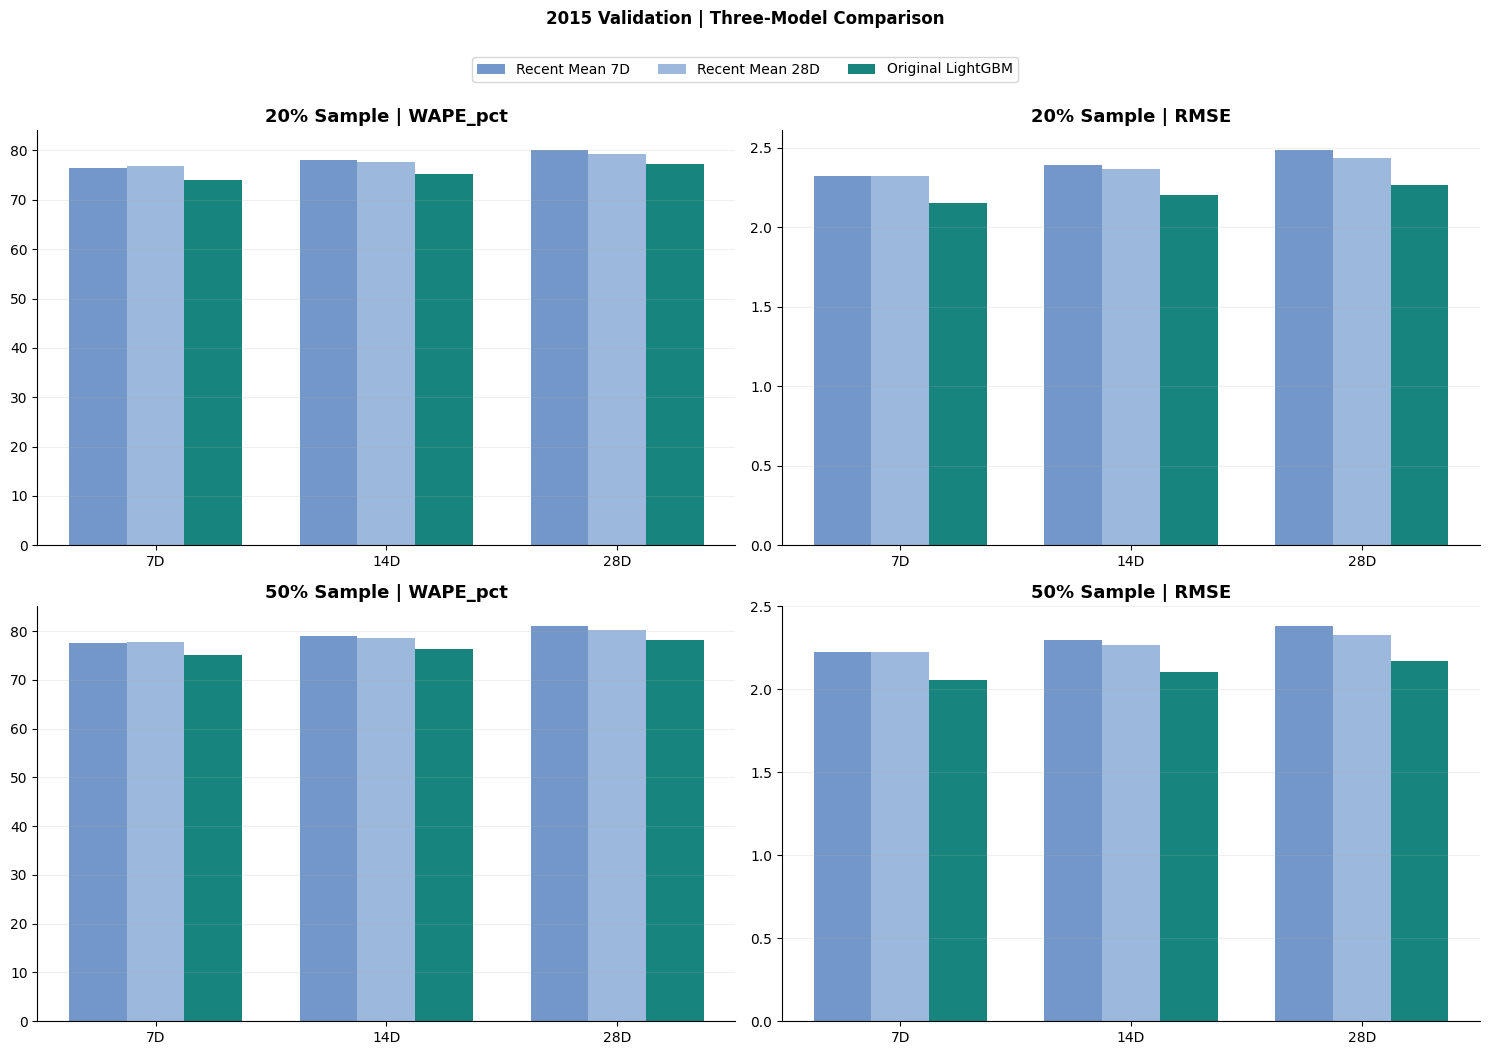

In [ ]:
# Overall Validation Scorecard
overall8 = val8[val8["segment"]=="All"].copy()
display(overall8[["sample","horizon","model","WAPE_pct","RMSE","MAE","Bias_pct"]].sort_values(["sample","horizon","model"]).round(3))

fig,axes = plt.subplots(2,2,figsize=(15,10))
for i,smp in enumerate(["20%","50%"]):
    for j,metric in enumerate(["WAPE_pct","RMSE"]):
        ax=axes[i,j]; sub=overall8[overall8["sample"]==smp]; x=np.arange(3)
        for k,m in enumerate(MODEL_ORDER):
            values=sub[sub["model"]==m].set_index("horizon")[metric].reindex(HORIZONS8); ax.bar(x+(k-1)*.25,values,.25,label=MODEL_LABELS[m],color=COLORS8[k])
        ax.set_xticks(x,["7D","14D","28D"]); ax.set_title(f"{smp} Sample | {metric}"); ax.grid(axis="y",alpha=.2)
handles,labels=axes[0,0].get_legend_handles_labels()
fig.legend(handles,labels,loc="upper center",ncol=3,bbox_to_anchor=(.5,1.01))
fig.suptitle("2015 Validation | Three-Model Comparison",fontweight="bold",y=1.05)
plt.tight_layout(); plt.show()

,sample,horizon,model,WAPE_pct,RMSE,MAE,Bias_pct
276,20%,7,lightgbm_final,73.953,2.150,0.940,-0.403
69,20%,7,recent_mean_28,76.821,2.325,0.977,-0.491
0,20%,7,recent_mean_7,76.477,2.321,0.972,-0.128
299,20%,14,lightgbm_final,75.317,2.201,0.960,-0.741
92,20%,14,recent_mean_28,77.706,2.369,0.991,-0.775
23,20%,14,recent_mean_7,78.060,2.394,0.995,-0.483
322,20%,28,lightgbm_final,77.294,2.268,0.987,-0.803
115,20%,28,recent_mean_28,79.324,2.434,1.013,-0.971
46,20%,28,recent_mean_7,80.078,2.486,1.023,-0.856
345,50%,7,lightgbm_final,75.025,2.056,0.924,-0.284


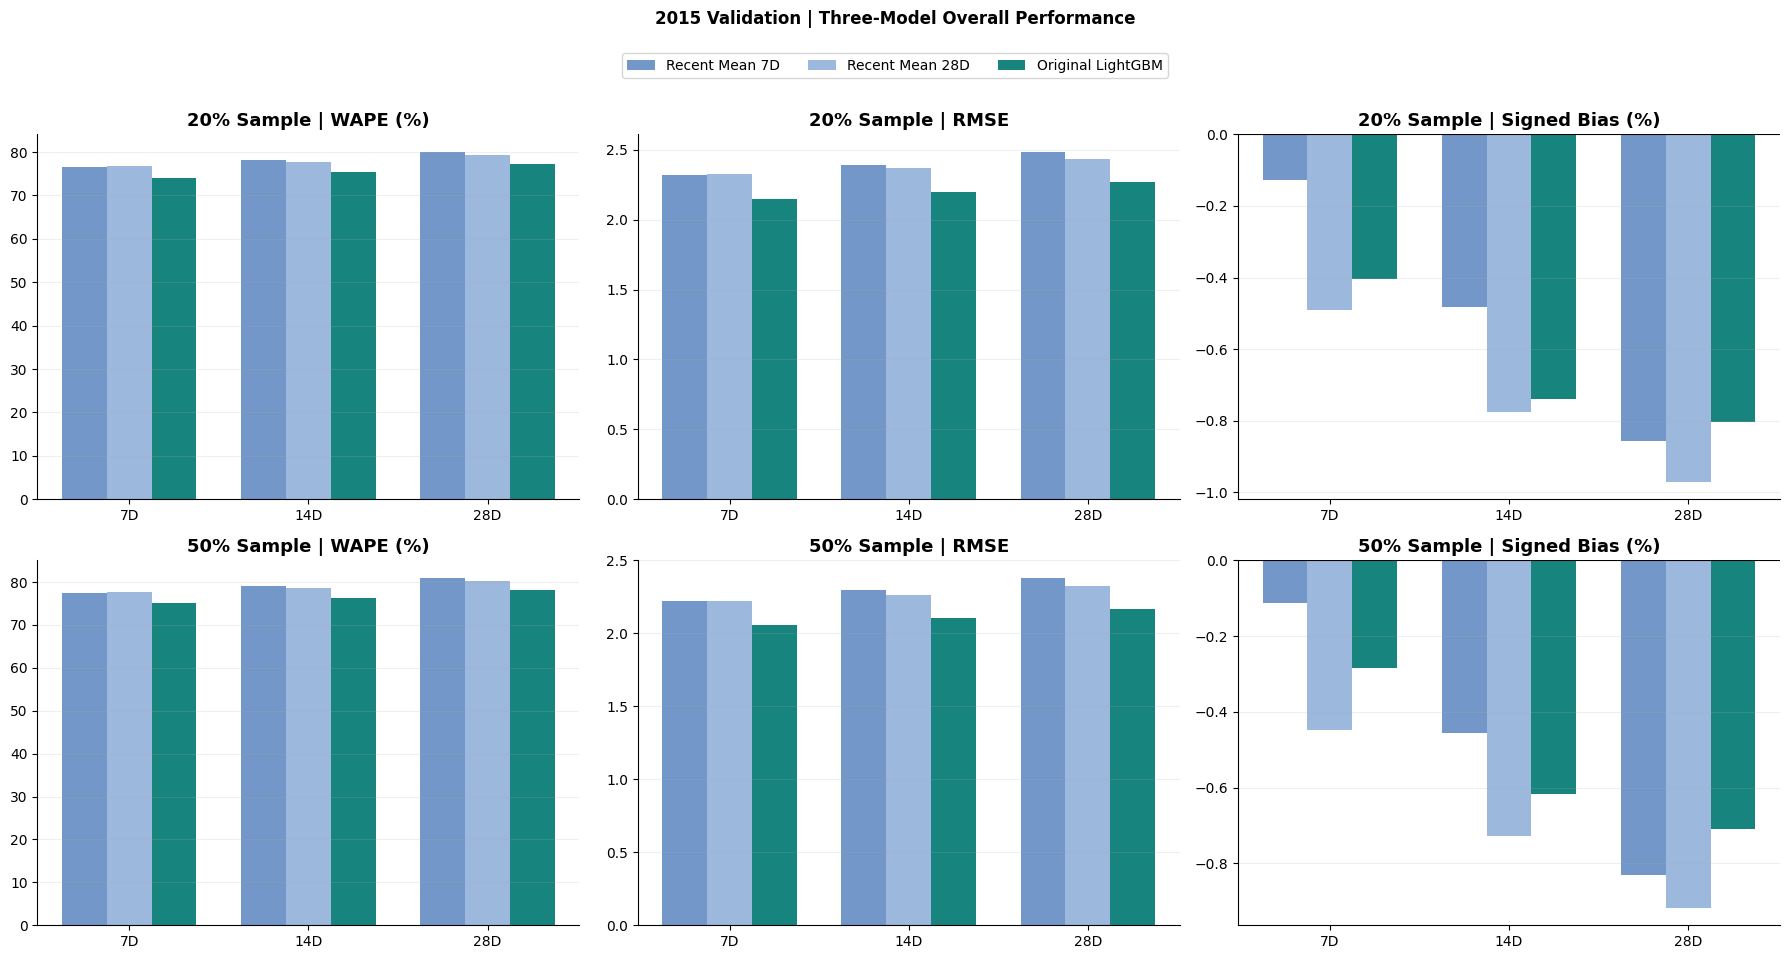

In [ ]:

# 8.2 — Overall Performance | 2015 Validation
s8=V8[V8["segment"]=="All"].copy()
assert len(s8)==18
display(s8[["sample","horizon","model","WAPE_pct","RMSE","MAE","Bias_pct"]].sort_values(["sample","horizon","model"]).round(3))
fig,axes=plt.subplots(2,3,figsize=(18,9))
for i,smp in enumerate(["20%","50%"]):
    for j,(metric,label) in enumerate([("WAPE_pct","WAPE (%)"),("RMSE","RMSE"),("Bias_pct","Signed Bias (%)")]):
        ax=axes[i,j]; d=s8[s8["sample"]==smp]; x=np.arange(3)
        for k,m in enumerate(M8):
            y=d[d["model"]==m].set_index("horizon")[metric].reindex(H8); ax.bar(x+(k-1)*.25,y,.25,label=N8[m],color=C8[k])
        ax.set_xticks(x,["7D","14D","28D"]); ax.set_title(f"{smp} Sample | {label}"); ax.grid(axis="y",alpha=.2)
        if metric=="Bias_pct": ax.axhline(0,color="black",lw=.8)
handles,labels=axes[0,0].get_legend_handles_labels(); fig.legend(handles,labels,loc="upper center",ncol=3,bbox_to_anchor=(.5,1.02))
fig.suptitle("2015 Validation | Three-Model Overall Performance",fontweight="bold",y=1.06); plt.tight_layout(); plt.show()


### 8.3 Demand Type & Category Performance

Group-level evaluation examines whether overall accuracy improvements are consistent across demand patterns and product categories.

Demand types include Smooth, Erratic, Intermittent, Lumpy, and No sales. Category comparisons cover FOODS, HOBBIES, and HOUSEHOLD.

The 50% canonical sample is used for detailed visualization, with all three forecast horizons reported.

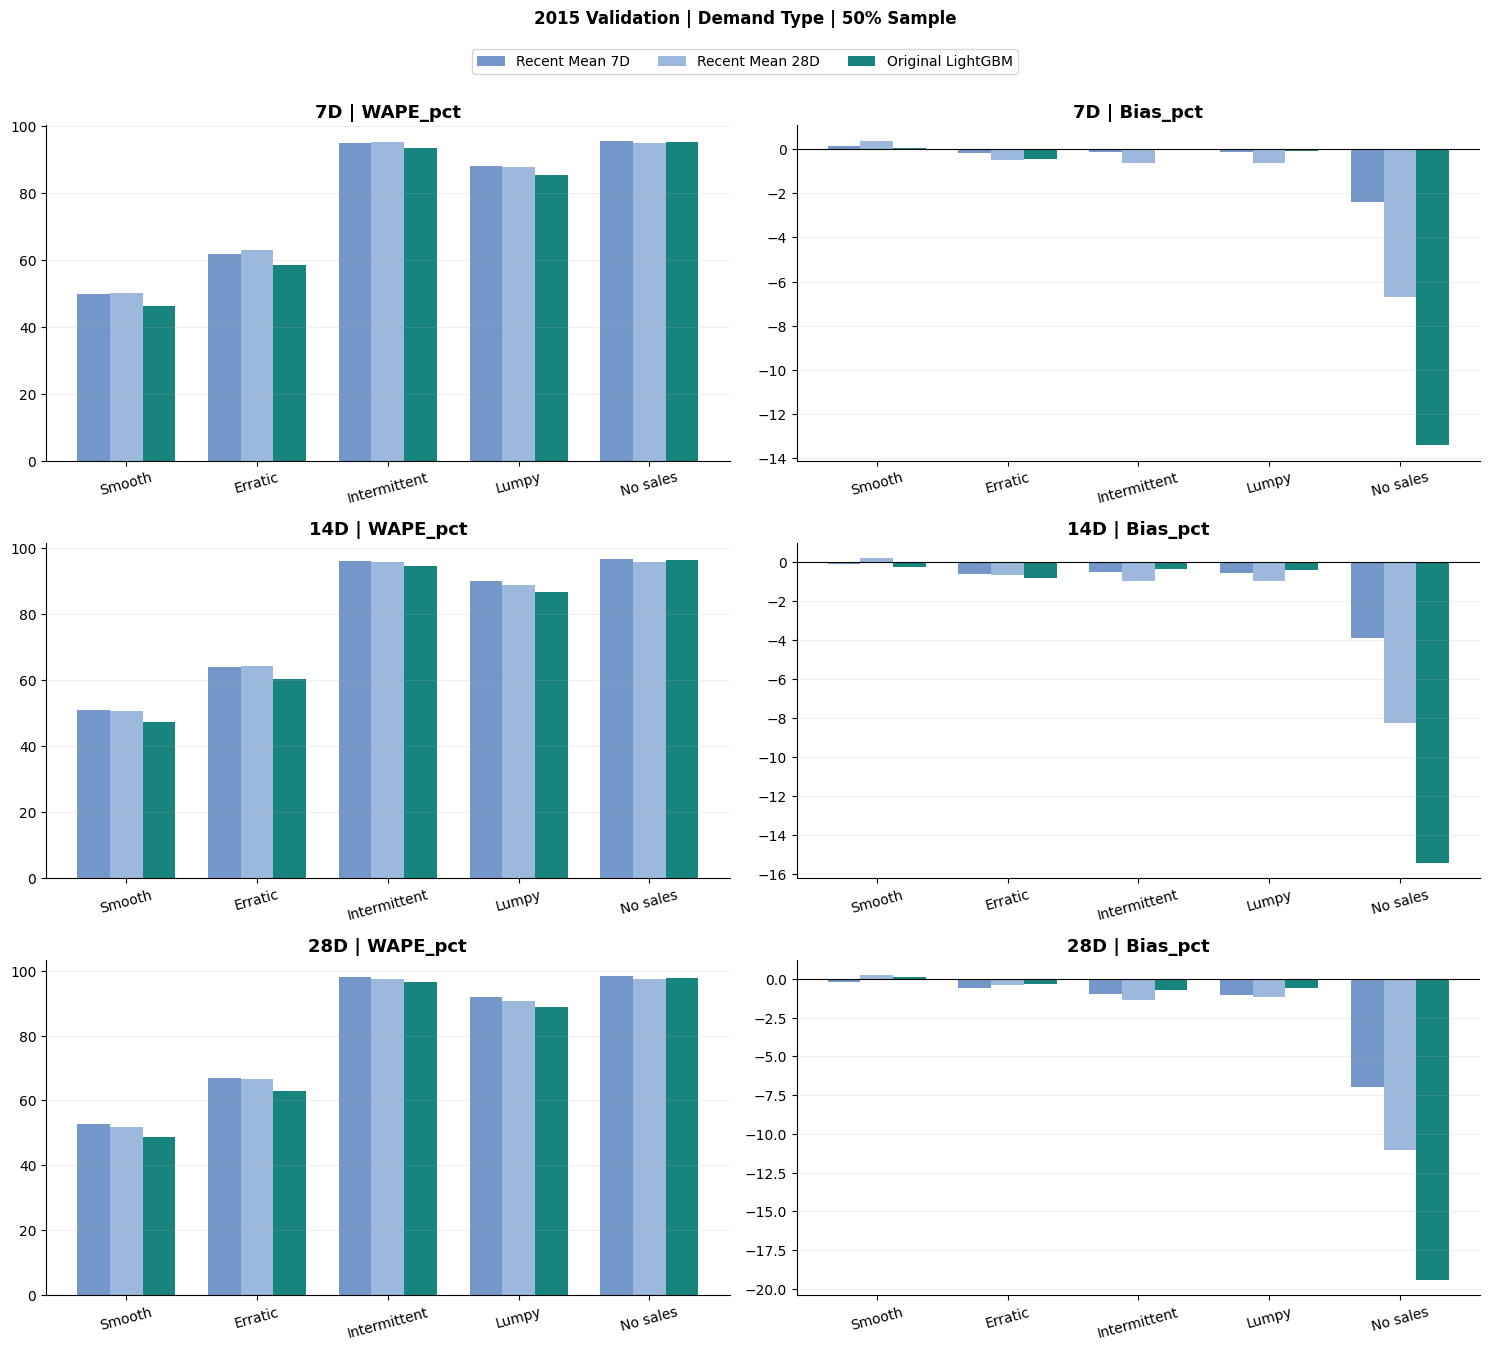

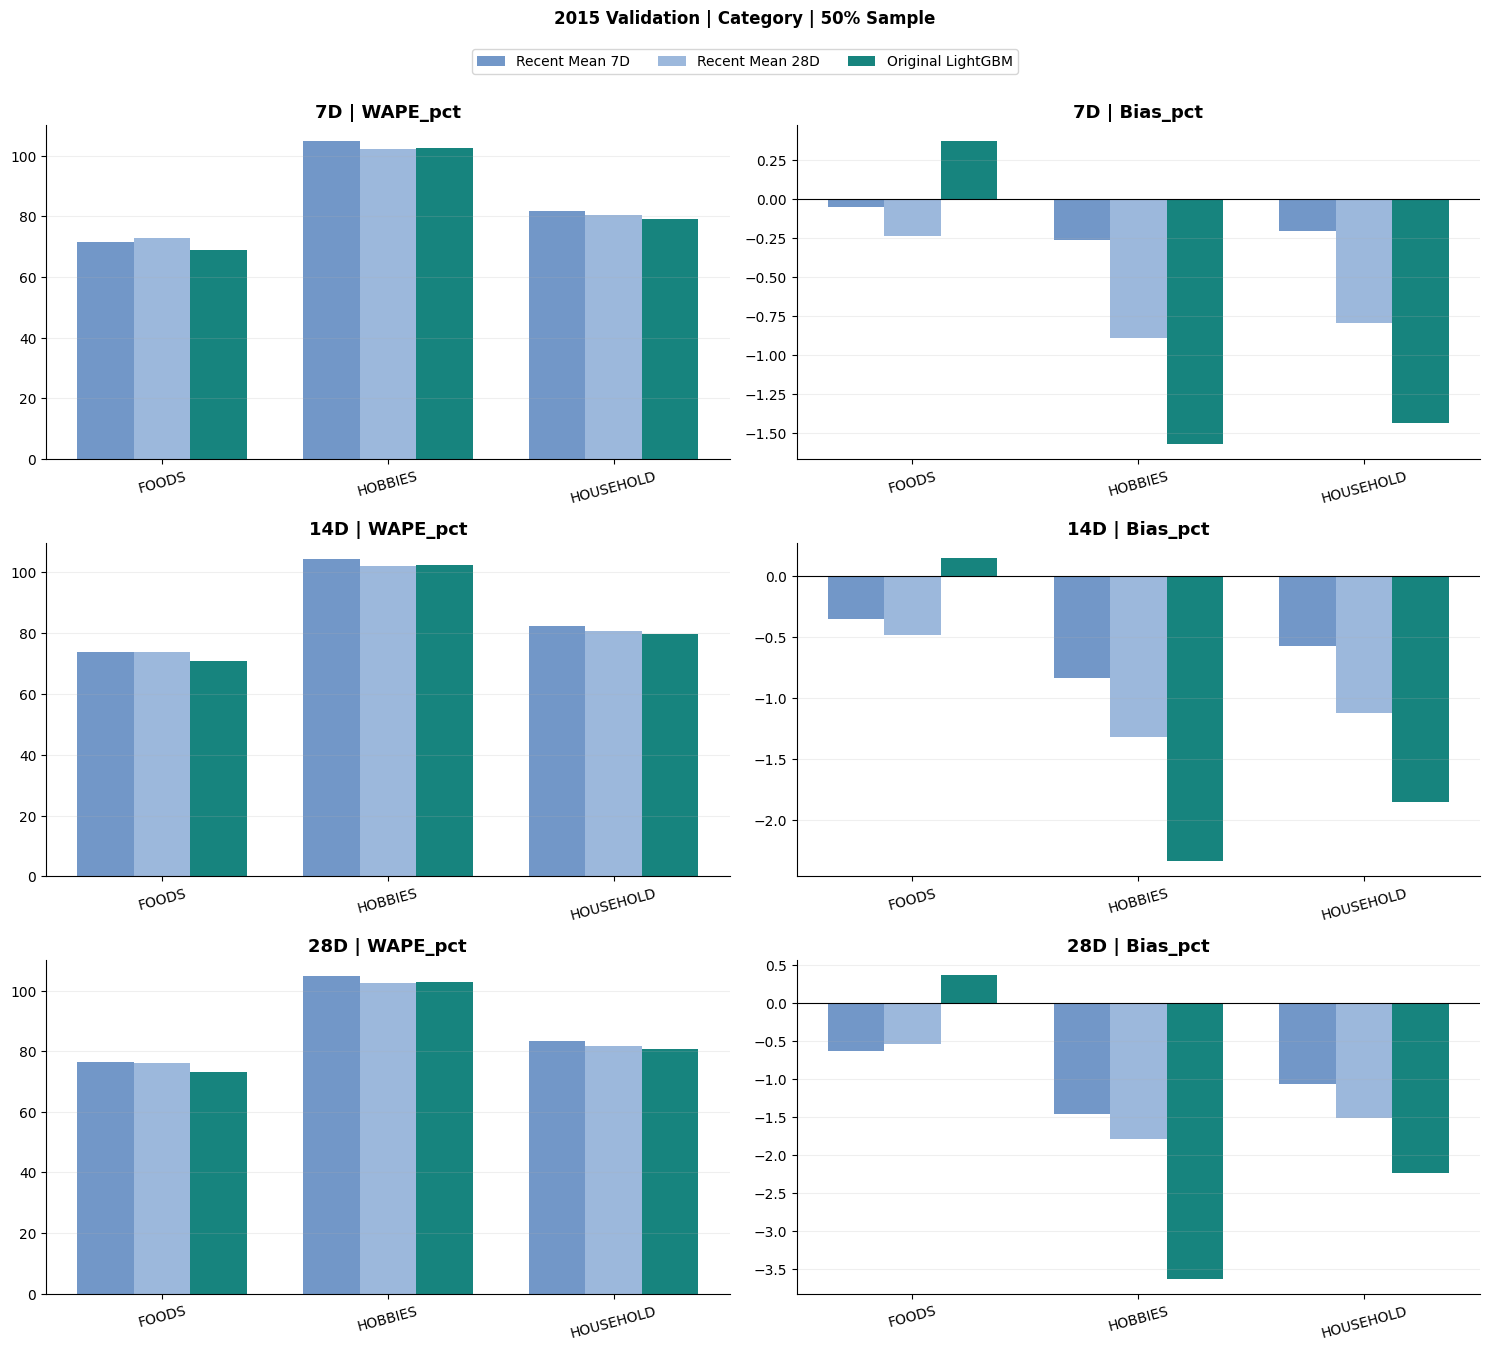

In [ ]:
# 8.3 — Demand Type and Category WAPE / Bias | 2015
for group_name,segments,prefix in [("Demand Type",DEMAND_ORDER8,""),("Category",CATEGORY_ORDER8,"cat:")]:
    fig,axes=plt.subplots(3,2,figsize=(15,13))
    for i,h in enumerate(HORIZONS8):
        sub=val8[(val8["sample"]=="50%")&(val8["horizon"]==h)].copy(); sub["group"]=sub["segment"].str.removeprefix(prefix) if prefix else sub["segment"]; sub=sub[sub["group"].isin(segments)]
        for j,metric in enumerate(["WAPE_pct","Bias_pct"]):
            ax=axes[i,j]; x=np.arange(len(segments))
            for k,m in enumerate(MODEL_ORDER):
                y=sub[sub["model"]==m].set_index("group")[metric].reindex(segments); ax.bar(x+(k-1)*.25,y,.25,label=MODEL_LABELS[m],color=COLORS8[k])
            ax.set_xticks(x,segments,rotation=15); ax.set_title(f"{h}D | {metric}"); ax.grid(axis="y",alpha=.2)
            if metric=="Bias_pct": ax.axhline(0,color="black",lw=.8)
    handles,labels=axes[0,0].get_legend_handles_labels(); fig.legend(handles,labels,loc="upper center",ncol=3,bbox_to_anchor=(.5,1.01))
    fig.suptitle(f"2015 Validation | {group_name} | 50% Sample",fontweight="bold",y=1.035)
    plt.tight_layout(); plt.show()

### 8.4 Validation Conclusion & Model Freeze

**Selected model: Original LightGBM.**

Original LightGBM satisfied all four predefined acceptance rules in the 2015 validation. Optuna was excluded because it failed the overall bias criterion.

The final forecasting recipe consists of:
- Original Tweedie LightGBM parameters.
- Quarterly model retraining using information available at each forecast origin.
- Trailing 13-week demand-type bias correction, subject to the original clipping limits.
- Separate evaluation at 7D, 14D, and 28D horizons.

No further model selection or parameter adjustment will be performed using the 2016 holdout.

The frozen model proceeds to Section 9.

## 9. 2016 Holdout Evaluation — Frozen Forecasting Recipe

### 9.1 Final Holdout Forecasting & Evaluation

This section evaluates the frozen Original LightGBM recipe on the independent 2016 holdout period, from January 1 through May 22, 2016.

The original quarterly retraining procedure is preserved. Models are refitted using historical data available before each forecasting block, without changing the selected hyperparameters, features, or bias-correction rules.

The same 20% and 50% canonical samples and 7D, 14D, and 28D horizons are used.

**Evaluation models:**
- Recent Mean 7D
- Recent Mean 28D
- Original LightGBM with trailing demand-type bias correction

**Evaluation metrics:** WAPE, RMSE, MAE, and signed bias.

The original execution preserves `test_models`, `test_origins`, `starts_t`, `block_of_t`, `fulls`, and `lg_test_final`, which are required by subsequent forecasting and RAG exports.

The original decision rules may be applied as a holdout diagnostic (`LG_TEST_PASSED`) but will not be used for further model selection or tuning.

### 9.2 Final Holdout Performance

The frozen Original LightGBM recipe demonstrated stronger out-of-sample forecasting accuracy than both Recent Mean baselines.

**2016 Holdout — 50% Sample**

| Model | WAPE 7D | WAPE 14D | WAPE 28D | Bias 7D | RMSE 7D |
|---|---:|---:|---:|---:|---:|
| Recent Mean 7D | 74.58% | 75.77% | 77.25% | -1.75% | 2.219 |
| Recent Mean 28D | 73.91% | 74.65% | 75.94% | -2.76% | 2.202 |
| Original LightGBM | **71.62%** | **72.55%** | **73.94%** | **-0.70%** | **2.040** |

At the 7D horizon, LightGBM reduced WAPE by approximately 3.97% relative to Recent Mean 7D and reduced RMSE by approximately 8.07%.

The 20% sample confirmed the same pattern, with 7D WAPE of 70.34% for LightGBM versus 73.37% for Recent Mean 7D.

All four predefined decision rules also passed when applied diagnostically to the 2016 holdout (6/6 cases per rule).

**Conclusion:** The frozen Original LightGBM recipe generalized successfully to the independent 2016 period, although forecast errors and negative signed bias increased at longer horizons.

In [ ]:
assert LG_PASSED_VAL, "Run only if the final recipe passed validation (16.13)."
t0 = time.time()
first_test = LG_VAL_END - 1
test_origins = lg_origins(min(LG_HORIZONS), first_test, LG_N_DAYS)
starts_t = list(range(LG_VAL_END, LG_N_DAYS - 7, LG_REFIT_EVERY))
def block_of_t(o): return max(s_ for s_ in starts_t if s_ <= o + 1)

fulls = {}
for smp, meta in [("20%", metadata_20), ("50%", metadata_50)]:
    f = get_sales_split(sales, meta["id"], day_cols); assert f["id"].tolist() == meta["id"].tolist()
    fulls[smp] = f[day_cols].to_numpy(dtype=np.float32)

print("Retraining on 2011-2015 data for each test block (20% sample)...")
ctx = lg_context(fulls["20%"], metadata_20["id"].tolist(), demand_type_20)
test_models = {}
for s_ in starts_t:
    test_models[s_] = lg_fit(ctx, list(range(365, s_ - 1, LG_TRAIN_STEP)), s_ - 1, LG_ALL)
    print(f"  block starting day {s_} done ({time.time() - t0:.0f}s)")
del ctx

rows = []
for smp, meta, dt, seg in [("20%", metadata_20, demand_type_20, lg_seg20), ("50%", metadata_50, demand_type_50, lg_seg50)]:
    M = fulls[smp]; c = lg_context(M, meta["id"].tolist(), dt)
    raw = {}
    for s_ in starts_t:
        os_ = [o for o in test_origins if block_of_t(o) == s_]
        if os_: raw.update(lg_predict(c, test_models[s_], os_, LG_ALL))
    del c
    types = dt["Demand_Type"].to_numpy()
    allraw = {**wf_raw[smp], **raw}                                    # 2015 forecasts (warm start) + 2016 forecasts
    hist, cal = {}, {}
    for o in lg_val_origins + test_origins:                            # in time order
        if o in raw:
            past = [p for p in (lg_val_origins + test_origins) if p <= o - 7][-LG_TRAIL_WEEKS:]
            f = np.ones(len(types), dtype=np.float32)
            if len(past) >= LG_MIN_WEEKS:
                for t in LG_TYPES:
                    a, fc = sum(hist[p][t][0] for p in past), sum(hist[p][t][1] for p in past)
                    if a > 0 and fc > 0: f[types == t] = np.clip(a / fc, *LG_CLIP)
            cal[o] = raw[o] * f[:, None]
        a7, f7 = M[:, o + 1:o + 8].sum(axis=1), allraw[o][:, :7].sum(axis=1)
        hist[o] = {t: (a7[types == t].sum(), f7[types == t].sum()) for t in LG_TYPES}
    models = {"recent_mean_7": {"flat": lg_recent_mean(M, 7, test_origins)}, "recent_mean_28": {"flat": lg_recent_mean(M, 28, test_origins)},
              "lightgbm_final": {"block": cal}}
    r = lg_eval(M, models, seg, first_test, LG_N_DAYS); r["sample"] = smp; rows.append(r)
    print(f"  {smp} test forecasts done ({time.time() - t0:.0f}s)")
lg_test_final = pd.concat(rows, ignore_index=True)
for smp in ["20%", "50%"]:
    s = lg_test_final.query("sample == @smp and segment == 'All'")
    print(f"\n=== TEST {smp}: overall WAPE (%) ===");  display(s.pivot(index="model", columns="horizon", values="WAPE_pct").loc[SHOWV].round(2))
    print(f"=== TEST {smp}: overall bias (%) ===");  display(s.pivot(index="model", columns="horizon", values="Bias_pct").loc[SHOWV].round(2))
    print(f"=== TEST {smp}: overall RMSE ===");  display(s.pivot(index="model", columns="horizon", values="RMSE").loc[SHOWV].round(3))
lg_test_table, LG_TEST_PASSED = lg_decide(lg_test_final, cand="lightgbm_final", label="(held-out test 2016)")

Retraining on 2011-2015 data for each test block (20% sample)...
  trained on 3,936,343 rows, 28 features
  block starting day 1798 done (180s)
  trained on 3,958,245 rows, 28 features
  block starting day 1889 done (382s)
  20% test forecasts done (463s)
  50% test forecasts done (659s)

=== TEST 20%: overall WAPE (%) ===


horizon,7,14,28
model,,,
recent_mean_7,73.37,74.52,75.92
recent_mean_28,72.69,73.38,74.59
lightgbm_final,70.34,71.18,72.46


=== TEST 20%: overall bias (%) ===


horizon,7,14,28
model,,,
recent_mean_7,-1.67,-2.12,-2.63
recent_mean_28,-2.50,-2.82,-3.35
lightgbm_final,-0.35,-0.95,-1.33


=== TEST 20%: overall RMSE ===


horizon,7,14,28
model,,,
recent_mean_7,2.200,2.257,2.319
recent_mean_28,2.183,2.221,2.270
lightgbm_final,2.024,2.058,2.098


... (4 outputs left out)

=== TEST 50%: overall RMSE ===


horizon,7,14,28
model,,,
recent_mean_7,2.219,2.282,2.343
recent_mean_28,2.202,2.243,2.294
lightgbm_final,2.040,2.080,2.123


,check,cases_passed,passed
0,1. >=2% better than Recent Mean (7d) on Interm...,6/6,True
1,2. Beats 28-day control there,6/6,True
2,3. No harm on Smooth+Erratic (<=+2%),6/6,True
3,4. Overall bias within limit,6/6,True


LightGBM passes (held-out test 2016): True


## 10. Forecast Error & Reliability Analysis — 2016 Holdout

Although Original LightGBM outperformed the Recent Mean baselines on the independent 2016 holdout, overall forecasting accuracy does not fully capture performance differences across demand patterns, product categories, and geographical regions.

This section examines segment-level forecasting errors and systematic bias to evaluate model reliability and identify potential implications for inventory management.

### 10.1 State × Category Bias Analysis

**Objective:** Evaluate whether Original LightGBM reduces systematic forecast bias consistently across states and product categories.

**Method:** Compare signed bias between Recent Mean 7D and Original LightGBM across CA, TX, WI and the FOODS, HOUSEHOLD, and HOBBIES categories using the 2016 holdout.

Negative bias indicates underforecasting; positive bias indicates overforecasting.

=== STATE BIAS | 50% SAMPLE | 7-DAY | 2016 TEST ===


model,recent_mean_7,lightgbm_final,Bias_Improvement_pp
segment,,,
state:CA,-1.563,-0.094,1.469
state:TX,-1.657,0.658,0.998
state:WI,-2.085,-2.659,-0.574


=== STATE × CATEGORY BIAS COMPARISON ===


model,recent_mean_7,lightgbm_final,Bias_Improvement_pp
segment,,,
state_cat:CA:FOODS,-1.836,-0.588,1.249
state_cat:CA:HOBBIES,-0.314,2.082,-1.768
state_cat:CA:HOUSEHOLD,-1.417,0.205,1.212
state_cat:TX:FOODS,-2.179,-0.248,1.931
state_cat:TX:HOBBIES,-1.077,1.659,-0.582
state_cat:TX:HOUSEHOLD,-0.635,2.433,-1.798
state_cat:WI:FOODS,-2.446,-3.528,-1.083
state_cat:WI:HOBBIES,-1.210,0.232,0.977
state_cat:WI:HOUSEHOLD,-1.169,-0.721,0.448


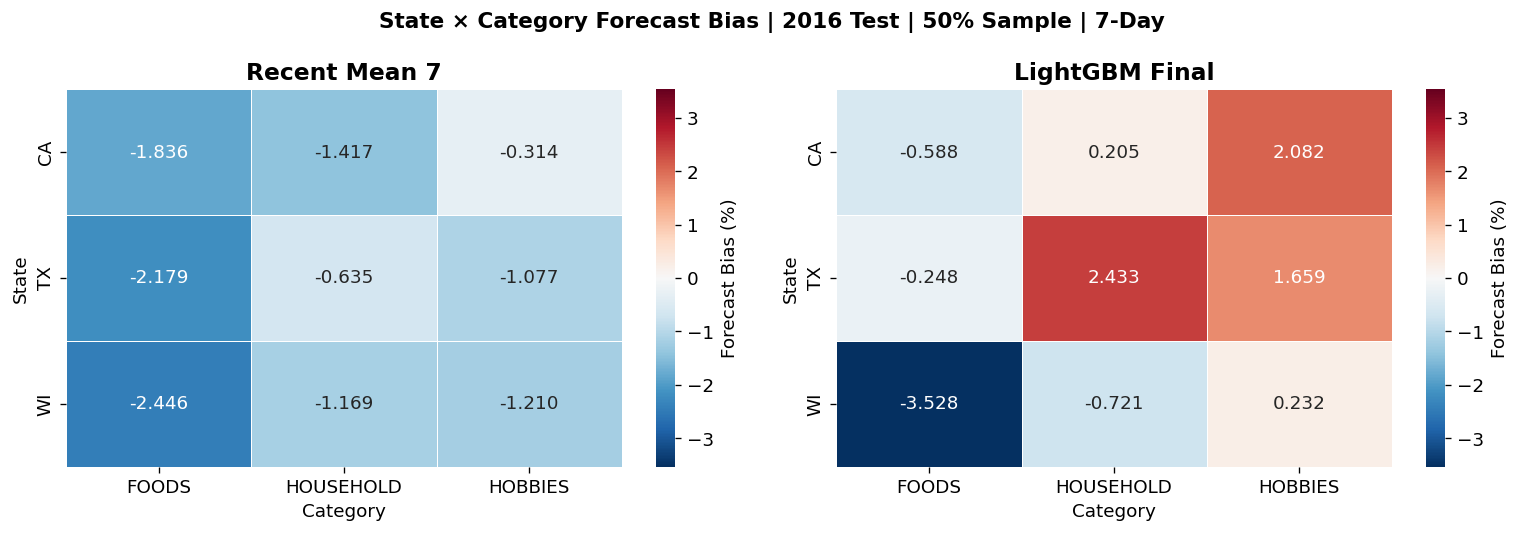

Saved three files to: /content/drive/MyDrive/IDS 560- Agentic AI & Inventory Project/M5 Forecasting/M5_Forecasting_Outputs


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# 1. Select comparable test results
models = ["recent_mean_7", "lightgbm_final"]
data = lg_test_final[(lg_test_final["sample"] == "50%") & (lg_test_final["horizon"] == 7) & (lg_test_final["model"].isin(models))].copy()
assert data["segment"].str.startswith("state_cat:").any(), "State-category results missing. Re-run the extended evaluation in Cell 153."

# 2. State Bias Comparison
state_bias = data[data["segment"].str.startswith("state:")].pivot(index="segment", columns="model", values="Bias_pct").reindex(columns=models)
state_bias["Bias_Improvement_pp"] = state_bias["recent_mean_7"].abs() - state_bias["lightgbm_final"].abs()
print("=== STATE BIAS | 50% SAMPLE | 7-DAY | 2016 TEST ===")
display(state_bias.round(3))

# 3. State × Category Bias Comparison
state_cat = data[data["segment"].str.startswith("state_cat:")].copy()
comparison = state_cat.pivot(index="segment", columns="model", values="Bias_pct").reindex(columns=models)
comparison["Bias_Improvement_pp"] = comparison["recent_mean_7"].abs() - comparison["lightgbm_final"].abs()
print("=== STATE × CATEGORY BIAS COMPARISON ===")
display(comparison.round(3))

# 4. Prepare the heatmaps
state_cat[["prefix", "state", "category"]] = state_cat["segment"].str.split(":", expand=True)
states, categories = ["CA", "TX", "WI"], ["FOODS", "HOUSEHOLD", "HOBBIES"]
limit = max(float(state_cat["Bias_pct"].abs().max()), 0.01)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# 5. Plot Recent Mean and LightGBM with the same color scale
for ax, model in zip(axes, models):
    temp = state_cat[state_cat["model"] == model]
    matrix = temp.pivot(index="state", columns="category", values="Bias_pct").reindex(index=states, columns=categories)
    sns.heatmap(matrix, ax=ax, annot=True, fmt=".3f", cmap="RdBu_r", center=0, vmin=-limit, vmax=limit, linewidths=0.5, cbar_kws={"label": "Forecast Bias (%)"})
    ax.set_title("Recent Mean 7" if model == "recent_mean_7" else "LightGBM Final", fontweight="bold")
    ax.set_xlabel("Category")
    ax.set_ylabel("State")

fig.suptitle("State × Category Forecast Bias | 2016 Test | 50% Sample | 7-Day", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

# 6. Export outputs without overwriting existing forecasting files
out = Path(Forecasting_OUTPUT)
out.mkdir(parents=True, exist_ok=True)
state_bias.to_csv(out / "state_bias_comparison_2016.csv")
comparison.to_csv(out / "state_category_bias_comparison_2016.csv")
fig.savefig(out / "state_category_bias_comparison_2016.png", dpi=300, bbox_inches="tight")
print("Saved three files to:", out)


#### 10.1 Findings & Conclusion

Original LightGBM reduced overall 7D signed bias from -1.75% to -0.70%, but the improvement varied across states and product categories.

- **California:** Bias improved from -1.56% to -0.09%.
- **Texas:** Bias shifted from -1.66% to +0.66%, reducing its absolute magnitude.
- **Wisconsin:** Underforecasting increased from -2.09% to -2.66%.

At the State × Category level, WI × FOODS exhibited notable underforecasting (-3.53%), while TX × HOUSEHOLD (+2.43%) and CA × HOBBIES (+2.08%) showed overforecasting.

**Conclusion:** LightGBM reduces aggregate systematic bias but does not minimize bias uniformly across all regional product segments. Localized bias should be considered when evaluating replenishment reliability.

### 10.2 Segment-Level Forecast Reliability Analysis

**Objective:** Determine whether LightGBM's overall forecasting improvement extends across demand types, categories, states, and forecast horizons.

**Method:** Compare Original LightGBM with Recent Mean 7D on the independent 2016 holdout, using WAPE and signed bias.

The evaluation focuses on:

- Overall accuracy across 7D, 14D, and 28D.
- Demand-type performance across Smooth, Erratic, Intermittent, Lumpy, and No sales.
- Category-level forecasting reliability.
- State-level and State × Category forecasting differences.

Lower WAPE indicates better accuracy, while signed bias identifies systematic overforecasting or underforecasting.

=== OVERALL ===


,segment,WAPE_pct_recent_mean_7,WAPE_pct_lightgbm_final,Bias_pct_recent_mean_7,Bias_pct_lightgbm_final,RMSE_recent_mean_7,RMSE_lightgbm_final,WAPE_Improvement_pct,Absolute_Bias_Improvement_pp
0,All,74.581,71.621,-1.753,-0.7,2.219,2.04,3.969,1.053


=== DEMAND TYPE ===


,segment,WAPE_pct_recent_mean_7,WAPE_pct_lightgbm_final,Bias_pct_recent_mean_7,Bias_pct_lightgbm_final,WAPE_Improvement_pct
0,Erratic,58.448,55.447,-1.043,1.050,5.133
1,Intermittent,89.424,86.927,-2.070,-1.339,2.791
2,Intermittent+Lumpy,87.393,84.556,-1.997,-1.176,3.245
3,Lumpy,83.773,80.331,-1.867,-0.887,4.109
4,No sales,88.806,89.532,-1.046,8.336,-0.817
5,Smooth,48.205,44.625,-1.503,-1.044,7.427
6,Smooth+Erratic,51.186,47.775,-1.369,-0.435,6.664


=== CATEGORY ===


,segment,WAPE_pct_recent_mean_7,WAPE_pct_lightgbm_final,Bias_pct_recent_mean_7,Bias_pct_lightgbm_final,RMSE_recent_mean_7,RMSE_lightgbm_final,WAPE_Improvement_pct,Absolute_Bias_Improvement_pp
0,cat:FOODS,67.888,64.625,-2.132,-1.500,2.746,2.501,4.807,0.632
1,cat:HOBBIES,104.789,102.704,-0.737,1.518,1.801,1.710,1.989,-0.781
2,cat:HOUSEHOLD,81.070,78.598,-1.112,0.624,1.496,1.399,3.049,0.488


=== STATE ===


,segment,WAPE_pct_recent_mean_7,WAPE_pct_lightgbm_final,Bias_pct_recent_mean_7,Bias_pct_lightgbm_final,RMSE_recent_mean_7,RMSE_lightgbm_final,WAPE_Improvement_pct,Absolute_Bias_Improvement_pp
0,state:CA,75.135,72.200,-1.563,-0.094,2.124,1.978,3.905,1.469
1,state:TX,74.472,72.884,-1.657,0.658,1.923,1.772,2.133,0.998
2,state:WI,73.948,69.779,-2.085,-2.659,2.588,2.350,5.638,-0.574


=== STATE × CATEGORY ===


,segment,WAPE_pct_recent_mean_7,WAPE_pct_lightgbm_final,Bias_pct_recent_mean_7,Bias_pct_lightgbm_final,RMSE_recent_mean_7,RMSE_lightgbm_final,WAPE_Improvement_pct,Absolute_Bias_Improvement_pp
0,state_cat:CA:FOODS,68.622,65.552,-1.836,-0.588,2.464,2.275,4.473,1.249
1,state_cat:CA:HOBBIES,100.349,98.138,-0.314,2.082,2.164,2.067,2.204,-1.768
2,state_cat:CA:HOUSEHOLD,80.676,77.766,-1.417,0.205,1.509,1.408,3.607,1.212
3,state_cat:TX:FOODS,66.861,65.071,-2.179,-0.248,2.311,2.101,2.677,1.931
4,state_cat:TX:HOBBIES,108.978,107.791,-1.077,1.659,1.519,1.445,1.089,-0.582
5,state_cat:TX:HOUSEHOLD,80.274,79.019,-0.635,2.433,1.480,1.399,1.564,-1.798
6,state_cat:WI:FOODS,67.804,63.192,-2.446,-3.528,3.419,3.089,6.803,-1.083
7,state_cat:WI:HOBBIES,109.058,106.237,-1.210,0.232,1.504,1.404,2.587,0.977
8,state_cat:WI:HOUSEHOLD,82.543,79.405,-1.169,-0.721,1.496,1.388,3.802,0.448


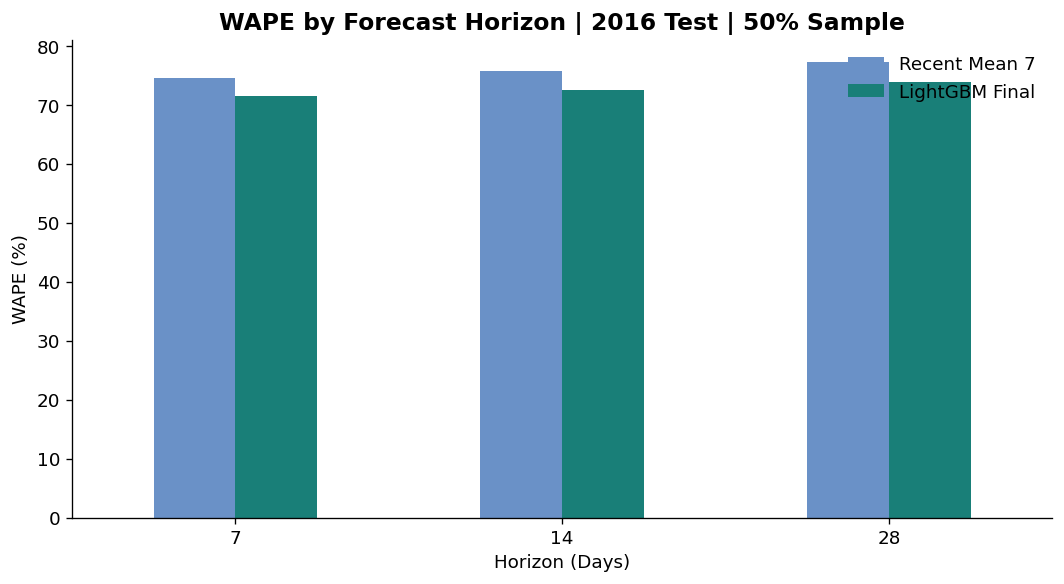

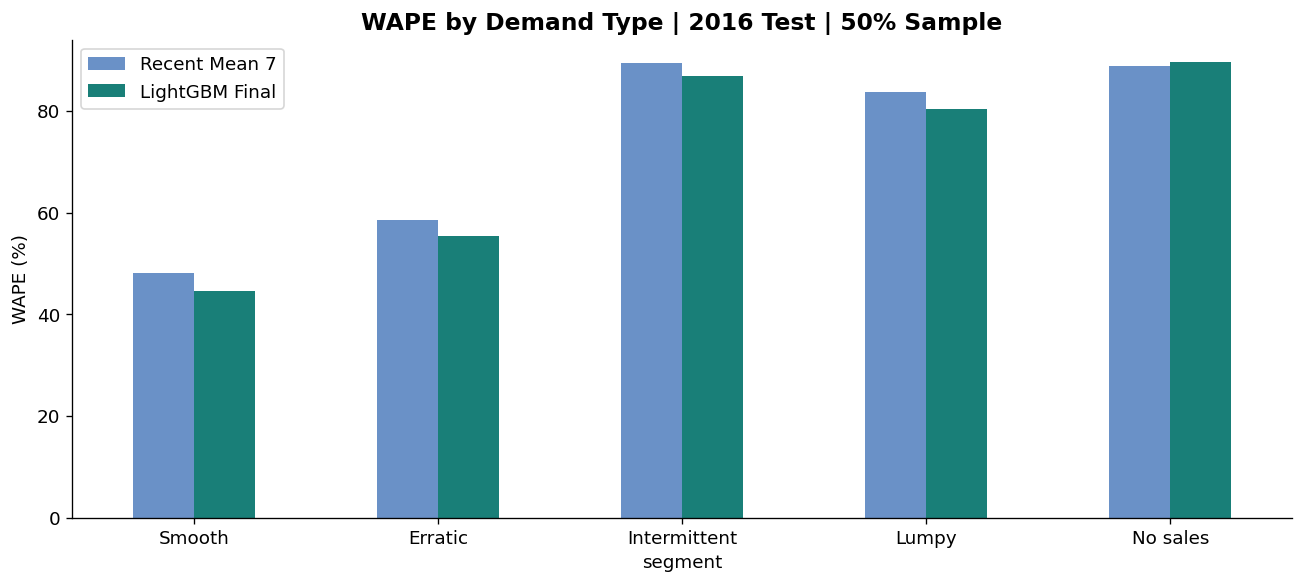

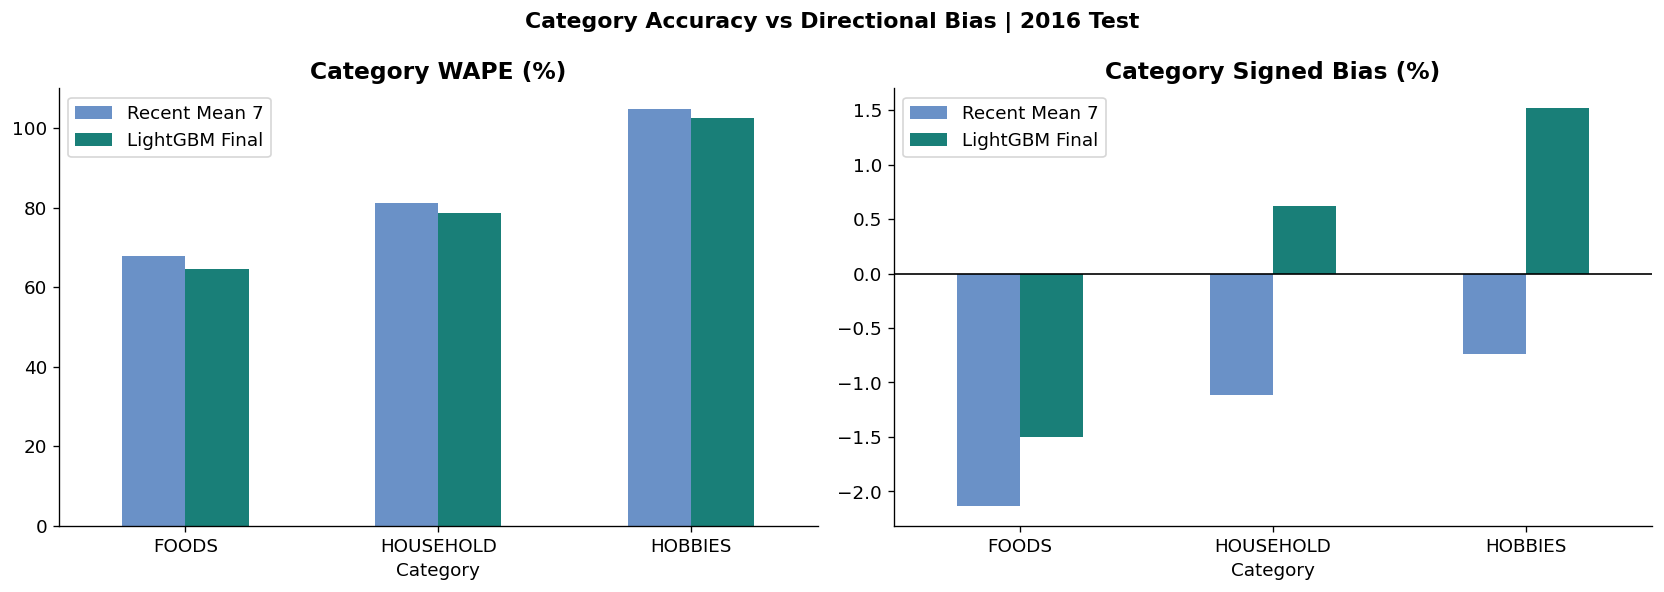

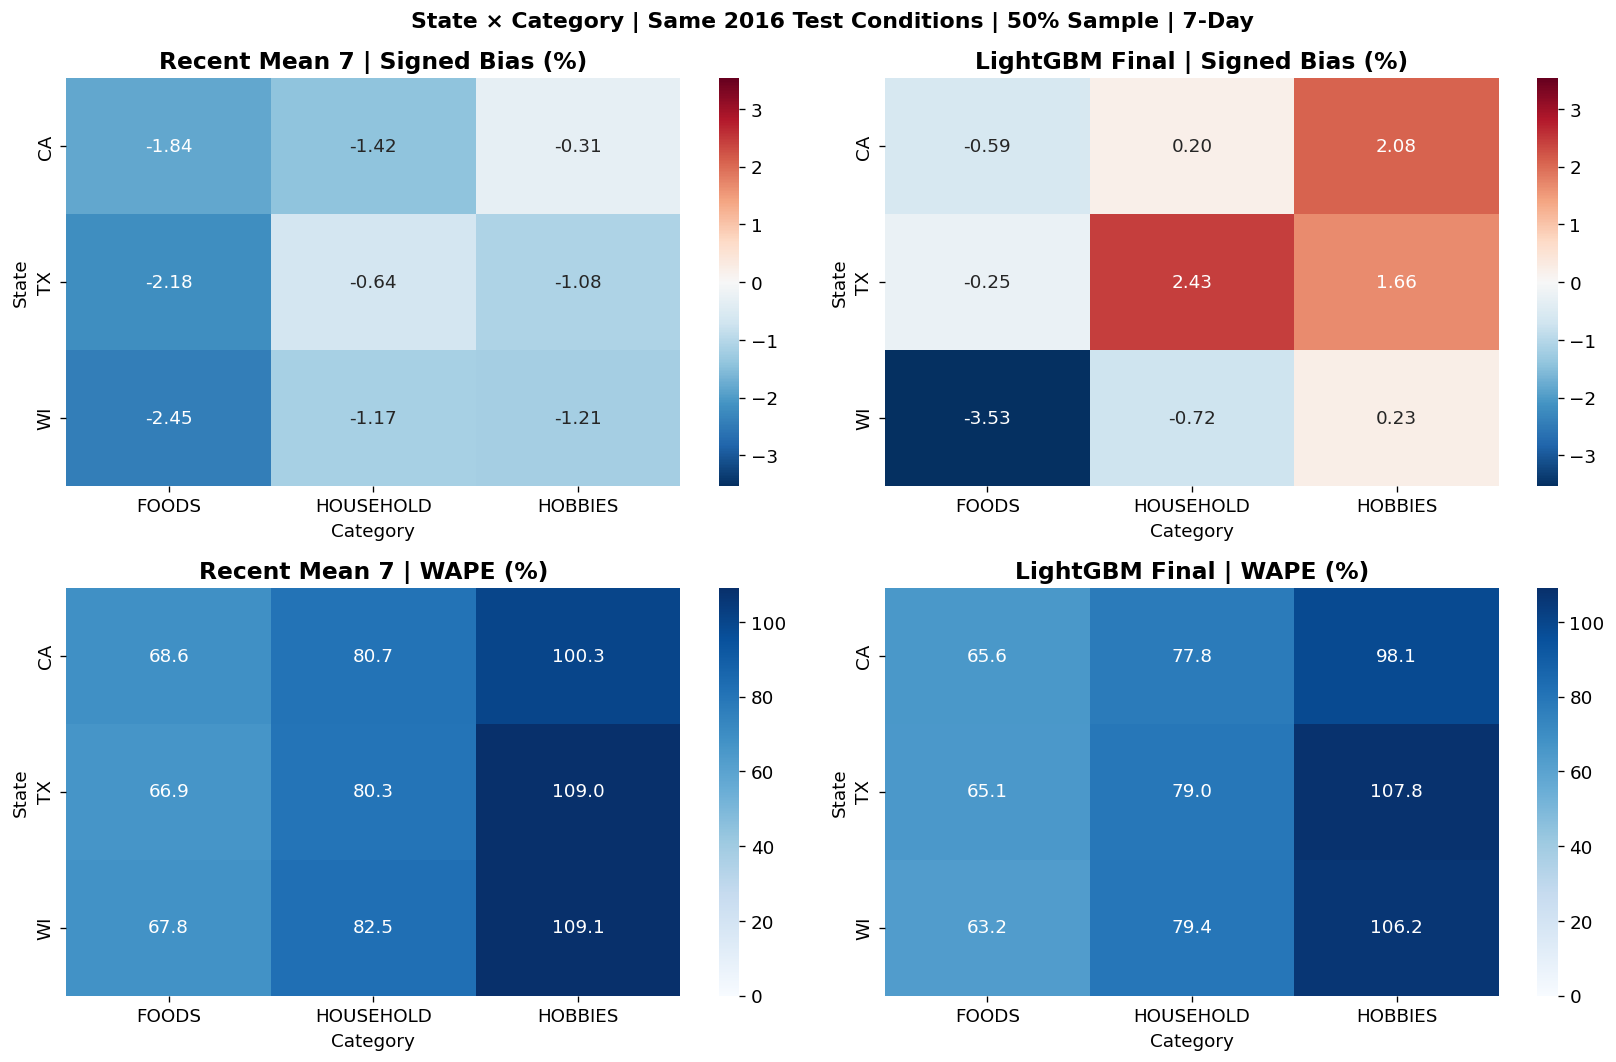

Saved 4 comparison figures and 5 CSV tables to: /content/drive/MyDrive/IDS 560- Agentic AI & Inventory Project/M5 Forecasting/M5_Forecasting_Outputs


In [ ]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
out = Path(Forecasting_OUTPUT); out.mkdir(parents=True,exist_ok=True)
models = ["recent_mean_7","lightgbm_final"]; x = lg_test_final[(lg_test_final["sample"]=="50%") & (lg_test_final["model"].isin(models))].copy(); names = {"recent_mean_7":"Recent Mean 7","lightgbm_final":"LightGBM Final"}
def compare_segments(prefix,h=7,exact=False):
    d = x[(x["horizon"]==h) & (x["segment"].eq(prefix) if exact else x["segment"].str.startswith(prefix))].copy()
    p = d.pivot(index="segment",columns="model",values=["WAPE_pct","Bias_pct","RMSE"]).reindex(columns=models,level=1)
    p.columns = [f"{a}_{b}" for a,b in p.columns]; p["WAPE_Improvement_pct"] = 100*(p["WAPE_pct_recent_mean_7"]-p["WAPE_pct_lightgbm_final"])/p["WAPE_pct_recent_mean_7"]; p["Absolute_Bias_Improvement_pp"] = p["Bias_pct_recent_mean_7"].abs()-p["Bias_pct_lightgbm_final"].abs(); return p.reset_index()
overall = compare_segments("All",exact=True); dtype = x[(x["horizon"]==7)&(x["segment"].isin(LG_TYPES+["Intermittent+Lumpy","Smooth+Erratic"]))].copy(); demand = dtype.pivot(index="segment",columns="model",values=["WAPE_pct","Bias_pct"]).reindex(columns=models,level=1); demand.columns = [f"{a}_{b}" for a,b in demand.columns]; demand["WAPE_Improvement_pct"] = 100*(demand["WAPE_pct_recent_mean_7"]-demand["WAPE_pct_lightgbm_final"])/demand["WAPE_pct_recent_mean_7"]; demand = demand.reset_index()
category = compare_segments("cat:"); state = compare_segments("state:"); statecat = compare_segments("state_cat:")
assert len(overall)==1 and len(category)==3 and len(state)==3 and len(statecat)==9, "Missing expected segment rows: verify Cell 153 and lg_segments"
print("=== OVERALL ==="); display(overall.round(3)); print("=== DEMAND TYPE ==="); display(demand.round(3)); print("=== CATEGORY ==="); display(category.round(3)); print("=== STATE ==="); display(state.round(3)); print("=== STATE × CATEGORY ==="); display(statecat.round(3))
wide = x[x["segment"]=="All"].pivot(index="horizon",columns="model",values="WAPE_pct").reindex(columns=models); ax = wide.rename(columns=names).plot(kind="bar",figsize=(9,5),color=["#6A91C7","#197F78"],rot=0); ax.set_title("WAPE by Forecast Horizon | 2016 Test | 50% Sample",fontweight="bold"); ax.set_xlabel("Horizon (Days)"); ax.set_ylabel("WAPE (%)"); ax.legend(frameon=False); plt.tight_layout(); plt.savefig(out/"sponsor_model_overall_wape_2016.png",dpi=300,bbox_inches="tight"); plt.show()
d = demand[demand["segment"].isin(LG_TYPES)].set_index("segment").reindex(LG_TYPES); fig,ax = plt.subplots(figsize=(11,5)); pd.DataFrame({"Recent Mean 7":d["WAPE_pct_recent_mean_7"],"LightGBM Final":d["WAPE_pct_lightgbm_final"]}).plot.bar(ax=ax,color=["#6A91C7","#197F78"],rot=0); ax.set_title("WAPE by Demand Type | 2016 Test | 50% Sample",fontweight="bold"); ax.set_ylabel("WAPE (%)"); plt.tight_layout(); fig.savefig(out/"sponsor_model_demand_type_wape_2016.png",dpi=300,bbox_inches="tight"); plt.show()
c = category.copy(); c["Category"] = c["segment"].str.replace("cat:","",regex=False); c = c.set_index("Category").reindex(["FOODS","HOUSEHOLD","HOBBIES"]); fig,axes = plt.subplots(1,2,figsize=(14,5)); pd.DataFrame({"Recent Mean 7":c["WAPE_pct_recent_mean_7"],"LightGBM Final":c["WAPE_pct_lightgbm_final"]}).plot.bar(ax=axes[0],color=["#6A91C7","#197F78"],rot=0); axes[0].set_title("Category WAPE (%)"); pd.DataFrame({"Recent Mean 7":c["Bias_pct_recent_mean_7"],"LightGBM Final":c["Bias_pct_lightgbm_final"]}).plot.bar(ax=axes[1],color=["#6A91C7","#197F78"],rot=0); axes[1].axhline(0,color="black",lw=1); axes[1].set_title("Category Signed Bias (%)"); fig.suptitle("Category Accuracy vs Directional Bias | 2016 Test",fontweight="bold"); plt.tight_layout(); fig.savefig(out/"sponsor_model_category_wape_bias_2016.png",dpi=300,bbox_inches="tight"); plt.show()
sc = statecat.copy(); sc[["prefix","State","Category"]] = sc["segment"].str.split(":",expand=True); fig,axes = plt.subplots(2,2,figsize=(14,9)); lim = max(sc["Bias_pct_recent_mean_7"].abs().max(),sc["Bias_pct_lightgbm_final"].abs().max()); vmax = max(sc["WAPE_pct_recent_mean_7"].max(),sc["WAPE_pct_lightgbm_final"].max())
for j,m in enumerate(models):
    label = names[m]; b = sc.pivot(index="State",columns="Category",values=f"Bias_pct_{m}").reindex(index=["CA","TX","WI"],columns=["FOODS","HOUSEHOLD","HOBBIES"]); w = sc.pivot(index="State",columns="Category",values=f"WAPE_pct_{m}").reindex(index=["CA","TX","WI"],columns=["FOODS","HOUSEHOLD","HOBBIES"]); sns.heatmap(b,annot=True,fmt=".2f",cmap="RdBu_r",center=0,vmin=-lim,vmax=lim,ax=axes[0,j]); sns.heatmap(w,annot=True,fmt=".1f",cmap="Blues",vmin=0,vmax=vmax,ax=axes[1,j]); axes[0,j].set_title(f"{label} | Signed Bias (%)"); axes[1,j].set_title(f"{label} | WAPE (%)")
fig.suptitle("State × Category | Same 2016 Test Conditions | 50% Sample | 7-Day",fontweight="bold"); plt.tight_layout(); fig.savefig(out/"sponsor_model_state_category_wape_bias_2016.png",dpi=300,bbox_inches="tight"); plt.show()
for name,t in [("overall",overall),("demand_type",demand),("category",category),("state",state),("state_category",statecat)]: t.to_csv(out/f"sponsor_model_{name}_2016.csv",index=False)
print("Saved 4 comparison figures and 5 CSV tables to:",out)


#### 10.2 Findings & Conclusion

**Overall accuracy:** Original LightGBM reduced WAPE from 74.58% to 71.62% at 7D, from 75.77% to 72.55% at 14D, and from 77.25% to 73.94% at 28D.

**Demand-type reliability:** The largest relative improvement occurred for Smooth demand (7.43%), followed by Erratic demand (5.13%). Intermittent and Lumpy demand improved but retained WAPE above 80%. No-sales performance slightly deteriorated.

**Category reliability:** FOODS achieved the strongest relative improvement (4.81%), while HOBBIES remained the least predictable category, with LightGBM WAPE exceeding 100%.

**Regional reliability:** LightGBM improved WAPE across CA, TX, and WI, with Wisconsin showing the largest relative improvement (5.64%). However, Wisconsin also exhibited greater negative signed bias than the baseline.

**Conclusion:** LightGBM consistently improves aggregate and most segment-level accuracy, but sparse demand, HOBBIES, and certain regional categories remain forecasting challenges. Segment-aware uncertainty and reliability monitoring are recommended for downstream inventory decisions.

### 10.3 Directional Bias & Inventory Risk Interpretation

This section interprets the signed-bias results already reported in Sections 9 and 10.1–10.2. No additional forecasting experiment is performed.

**2016 Holdout — 50% Sample**

| Horizon | LightGBM Bias | Recent Mean 7D Bias |
|---|---:|---:|
| 7D | -0.70% | -1.75% |
| 14D | -1.31% | -2.27% |
| 28D | -1.67% | -2.72% |

**Key Findings:**

- LightGBM has lower absolute signed bias than Recent Mean 7D across all three horizons.
- Negative bias increases in magnitude as the forecast horizon extends.
- Wisconsin FOODS (-3.53%) shows notable localized underforecasting.
- Texas HOUSEHOLD (+2.43%) and California HOBBIES (+2.08%) show localized overforecasting.

**Inventory Implications:**

- Underforecasting may increase stockout exposure when replenishment decisions rely on point forecasts.
- Overforecasting may increase excess inventory and holding costs.
- Segment-specific bias should be monitored when evaluating inventory policies.

**Conclusion:** LightGBM improves aggregate forecast bias, but some demand segments and regional categories still exhibit directional forecasting risks. These risks require validation through downstream inventory simulation.

Signed bias is a net error measure; it does not directly measure actual stockouts, excess inventory, or the total volume of individual underforecast and overforecast events.

### 10.4 Historical Bias Correction — Evidence from Model Development

The final LightGBM recipe combines quarterly retraining with trailing 13-week demand-type bias correction. This section summarizes existing 2015 development evidence rather than running a new experiment.

**2015 Validation — 50% Sample, 7D**

| Model Stage | WAPE | Signed Bias |
|---|---:|---:|
| Initial LightGBM | 74.9% | -4.4% |
| Final LightGBM Recipe | 75.0% | -0.3% |

**Key Findings:**

- The initial LightGBM achieved strong WAPE but exhibited substantial systematic underforecasting.
- The final quarterly retraining and historical bias-correction recipe substantially reduced signed bias while maintaining similar accuracy.
- The final recipe passed all four predefined 2015 validation decision rules.

**2016 Holdout Evidence:**

The frozen final recipe achieved 7D WAPE of 71.62% and signed bias of -0.70% on the 50% sample.

**Conclusion:** The final LightGBM recipe demonstrates that strong forecasting accuracy can coexist with relatively small systematic bias.

The 2016 results evaluate the complete frozen recipe. They do not isolate the individual contribution of bias correction from quarterly retraining or other model components.

### 10.5 Final Reliability Conclusions & Inventory Implications

The 2016 holdout confirms that Original LightGBM provides stronger overall forecasting accuracy than the Recent Mean baselines while satisfying the predefined reliability criteria.

**Key Findings:**

1. **Overall accuracy:** LightGBM reduced 7D WAPE from 74.58% to 71.62% relative to Recent Mean 7D.
2. **Horizon stability:** LightGBM maintained its accuracy advantage across 7D, 14D, and 28D, although WAPE increased at longer horizons.
3. **Demand-type reliability:** Smooth and Erratic demand showed meaningful improvements, while Intermittent, Lumpy, and No-sales series remained challenging.
4. **Category reliability:** FOODS benefited from stronger relative accuracy improvements, while HOBBIES retained high forecasting errors.
5. **Regional reliability:** LightGBM improved WAPE across CA, TX, and WI, but some State × Category combinations exhibited persistent systematic bias.
6. **Bias control:** The final quarterly retraining and historical bias-correction recipe substantially improved systematic bias compared with the initial model during 2015 validation.

**Inventory Management Implications:**

Forecast accuracy alone does not determine replenishment quality. Inventory decisions should also consider forecast horizon, demand pattern, regional differences, and prediction uncertainty.

The forecasting outputs therefore support reliability-aware inventory decision-making, but the operational benefits must be evaluated through inventory simulation.

**Final Conclusion:** Original LightGBM is accepted as the final forecasting model. The remaining segment-level reliability limitations motivate the use of demand-type uncertainty intervals and historical error information in downstream RAG and inventory decisions.

## 11. Final Forecast Export & Model Diagnostics

This section preserves the original final forecast format, sanity checks, P10–P90 uncertainty evaluation, and LightGBM feature-importance analysis.

All downstream forecast interfaces and output filenames remain unchanged.

In [ ]:
# Final forecast file: teammate's early version (Recent Mean) + final LightGBM, same format, origin 2015-12-31, next 7 days (the only file this section saves)
assert "test_models" in globals() and "wf_raw" in globals(), "Run 16.12, 16.13 and 16.14 first (they hold the final model and the 2015 forecasts)."
t0 = time.time()
early = forecast_50.copy() if "forecast_50" in globals() else pd.read_csv(Path(Forecasting_OUTPUT) / "forecast_predictions_7day_50.csv")
o_final = LG_VAL_END - 1                                                        # last day of 2015 = forecast origin
assert early["forecast_origin"].nunique() == 1 and pd.Timestamp(early["forecast_origin"].iloc[0]) == pd.Timestamp(calendar.set_index("d").loc[day_cols[o_final], "date"])
M, ids = sample50_matrix, metadata_50["id"].tolist()
assert early["series_id"].drop_duplicates().tolist() == ids, "Series order differs from the early forecast file."
types = demand_type_50["Demand_Type"].to_numpy()

# 1) 2015 forecasts with the same trailing correction -> out-of-time errors -> P10/P90 offsets (same method as the early version)
raw_val, hist, resid = wf_raw["50%"], {}, []
def trailing_factor(o):
    past = [p for p in lg_val_origins if p <= o - 7][-LG_TRAIL_WEEKS:]
    f = np.ones(len(types), dtype=np.float32)
    if len(past) >= LG_MIN_WEEKS:
        for t in LG_TYPES:
            a, fc = sum(hist[p][t][0] for p in past), sum(hist[p][t][1] for p in past)
            if a > 0 and fc > 0: f[types == t] = np.clip(a / fc, *LG_CLIP)
    return f
for o in lg_val_origins:
    actual = M[:, o + 1:o + 8].astype(np.float64)
    resid.append(actual - raw_val[o][:, :7] * trailing_factor(o)[:, None])
    hist[o] = {t: (actual.sum(axis=1)[types == t].sum(), raw_val[o][:, :7].sum(axis=1)[types == t].sum()) for t in LG_TYPES}
resid = np.stack(resid)                                                          # origins x series x 7 leads
pooled10, pooled90 = np.quantile(resid, 0.10, axis=(0, 1)), np.quantile(resid, 0.90, axis=(0, 1))
type10, type90 = np.empty((len(types), 7)), np.empty((len(types), 7))
for t in np.unique(types):
    idx = np.where(types == t)[0]
    type10[idx], type90[idx] = np.quantile(resid[:, idx, :], 0.10, axis=(0, 1)), np.quantile(resid[:, idx, :], 0.90, axis=(0, 1))
del resid

# 2) final LightGBM point forecast for Jan 1-7, 2016 (model trained on 2011-2015 only, then the trailing correction)
ctx = lg_context(M, ids, demand_type_50)
point = lg_predict(ctx, test_models[LG_VAL_END], [o_final], LG_ALL)[o_final][:, :7] * trailing_factor(o_final)[:, None]
del ctx

# 3) same layout as the early version
dates = early.drop_duplicates("lead").set_index("lead")["target_date"]
parts = []
for method, q10, q90 in [("Pooled", pooled10[None, :], pooled90[None, :]), ("Demand-Type", type10, type90)]:
    p10 = np.maximum(0, point + q10); p90 = np.maximum(p10, point + q90)
    for lead in range(1, 8):
        parts.append(pd.DataFrame({"series_id": ids, "forecast_origin": early["forecast_origin"].iloc[0], "target_date": dates[lead], "lead": lead, "horizon": 7,
                                   "model": "LightGBM (retrained quarterly + bias correction)", "method": method, "point_forecast": point[:, lead - 1],
                                   "p10": p10[:, lead - 1], "p90": p90[:, lead - 1], "sample": "50%", "forecast_type": "historical_holdout", "model_role": "final"}))
final = pd.concat([early.assign(model_role="early_version")] + parts, ignore_index=True)

# 4) checks (same rules as the early version's data contract)
key = ["series_id", "forecast_origin", "target_date", "model", "method"]
assert final["p10"].le(final["p90"]).all() and np.isfinite(final[["point_forecast", "p10", "p90"]].to_numpy()).all() and (final[["point_forecast", "p10", "p90"]] >= 0).all().all()
assert not final.duplicated(key).any() and final.groupby(["series_id", "model", "method"]).size().eq(7).all()
assert final["series_id"].nunique() == len(ids) and final["model"].nunique() == 2

out_path = Path(Forecasting_OUTPUT) / "forecast_predictions_7day_50_final.csv"
final.to_csv(out_path, index=False)
print(f"Saved {len(final):,} rows to {out_path}  ({time.time() - t0:.0f}s)")
chk = final.groupby(["model", "method"]).agg(total_units_7d=("point_forecast", "sum"), mean_p10_p90_width=("p90", "sum"))
chk["mean_p10_p90_width"] = (final["p90"] - final["p10"]).groupby([final["model"], final["method"]]).mean()
display(chk.round(2))
display(final.query("series_id == @ids[0] and method == 'Pooled'").round(3))

Saved 426,860 rows to /content/drive/MyDrive/IDS 560- Agentic AI & Inventory Project/M5 Forecasting/M5_Forecasting_Outputs/forecast_predictions_7day_50_final.csv  (25s)


total_units_7d  \
model                                            method                        
LightGBM (retrained quarterly + bias correction) Demand-Type   136271.640625   
                                                 Pooled        136271.640625   
Recent Mean (7-day)                              Demand-Type   105227.000000   
                                                 Pooled        105227.000000   

                                                              mean_p10_p90_width  
model                                            method                           
LightGBM (retrained quarterly + bias correction) Demand-Type                2.16  
                                                 Pooled                     1.99  
Recent Mean (7-day)                              Demand-Type                2.02  
                                                 Pooled                     1.77

,series_id,forecast_origin,target_date,lead,horizon,model,method,point_forecast,p10,p90,sample,forecast_type,model_role
0,HOBBIES_1_002_CA_1_evaluation,2015-12-31,2016-01-01,1,7,Recent Mean (7-day),Pooled,0.143,0.0,1.857,50%,historical_holdout,early_version
15245,HOBBIES_1_002_CA_1_evaluation,2015-12-31,2016-01-02,2,7,Recent Mean (7-day),Pooled,0.143,0.0,1.857,50%,historical_holdout,early_version
30490,HOBBIES_1_002_CA_1_evaluation,2015-12-31,2016-01-03,3,7,Recent Mean (7-day),Pooled,0.143,0.0,1.286,50%,historical_holdout,early_version
45735,HOBBIES_1_002_CA_1_evaluation,2015-12-31,2016-01-04,4,7,Recent Mean (7-day),Pooled,0.143,0.0,1.143,50%,historical_holdout,early_version
60980,HOBBIES_1_002_CA_1_evaluation,2015-12-31,2016-01-05,5,7,Recent Mean (7-day),Pooled,0.143,0.0,1.143,50%,historical_holdout,early_version
76225,HOBBIES_1_002_CA_1_evaluation,2015-12-31,2016-01-06,6,7,Recent Mean (7-day),Pooled,0.143,0.0,1.143,50%,historical_holdout,early_version
91470,HOBBIES_1_002_CA_1_evaluation,2015-12-31,2016-01-07,7,7,Recent Mean (7-day),Pooled,0.143,0.0,1.429,50%,historical_holdout,early_version
213430,HOBBIES_1_002_CA_1_evaluation,2015-12-31,2016-01-01,1,7,LightGBM (retrained quarterly + bias correction),Pooled,0.604,0.0,1.855,50%,historical_holdout,final
228675,HOBBIES_1_002_CA_1_evaluation,2015-12-31,2016-01-02,2,7,LightGBM (retrained quarterly + bias correction),Pooled,0.910,0.0,2.261,50%,historical_holdout,final
243920,HOBBIES_1_002_CA_1_evaluation,2015-12-31,2016-01-03,3,7,LightGBM (retrained quarterly + bias correction),Pooled,0.835,0.0,2.346,50%,historical_holdout,final


#### 11.1 Findings

For January 1–7, 2016, actual sales totaled 130,915 units. LightGBM forecast 136,272 units (+4.1%), while Recent Mean 7D forecast 105,227 units (-19.6%).

LightGBM provided a substantially closer aggregate forecast for this specific week. This sanity check complements, but does not replace, the full holdout evaluation.

In [ ]:
# One-off check: the file's Jan 1-7, 2016 forecast totals against what actually sold
actual = fulls["50%"][:, LG_VAL_END:LG_VAL_END + 7].sum()
print("Daily units, Dec 25-31 2015:", sample50_matrix[:, LG_VAL_END - 7:].sum(axis=0).astype(int))
print("Daily units, Jan 1-7 2016:  ", fulls["50%"][:, LG_VAL_END:LG_VAL_END + 7].sum(axis=0).astype(int))
print(f"Actual units sold Jan 1-7, 2016: {actual:,.0f}")
for m, v in final[final["method"] == "Pooled"].groupby("model")["point_forecast"].sum().items():
    print(f"{m}: forecast {v:,.0f}  ({100 * (v - actual) / actual:+.1f}% vs actual)")

Daily units, Dec 25-31 2015: [    9 18926 17378 14810 15885 16678 21541]
Daily units, Jan 1-7 2016:   [16446 22492 22093 18082 17534 16283 17985]
Actual units sold Jan 1-7, 2016: 130,915
LightGBM (retrained quarterly + bias correction): forecast 136,272  (+4.1% vs actual)
Recent Mean (7-day): forecast 105,227  (-19.6% vs actual)


### 11.2 Prediction Interval Coverage

This section evaluates P10–P90 prediction interval coverage on the 2016 holdout, comparing the pooled uncertainty method with demand-type-specific intervals.

The nominal prediction interval coverage target is 80%.

In [ ]:
# Check the P10-P90 ranges on 2016: how often did real daily sales fall inside them? (target is 80%)
assert "test_models" in globals() and "pooled10" in globals(), "Run 16.14 and 16.15 first."
t0 = time.time()
M, ids = fulls["50%"], metadata_50["id"].tolist()
types = demand_type_50["Demand_Type"].to_numpy()
masks = {"All": np.ones(len(types), dtype=bool), "Intermittent+Lumpy": np.isin(types, ["Intermittent", "Lumpy"]), "Smooth+Erratic": np.isin(types, ["Smooth", "Erratic"])}
ctx = lg_context(M, ids, demand_type_50)
raw = {}
for s_ in starts_t:
    os_ = [o for o in test_origins if block_of_t(o) == s_]
    if os_: raw.update(lg_predict(ctx, test_models[s_], os_, LG_ALL))
del ctx
allraw = {**wf_raw["50%"], **raw}
rm7 = lg_recent_mean(M, 7, test_origins)
offsets = {"LightGBM (final)": {"Pooled": (pooled10[None, :], pooled90[None, :]), "Demand-Type": (type10, type90)},
           "Recent Mean (early version)": {"Pooled": (pi_cal_50["pooled10"][None, :], pi_cal_50["pooled90"][None, :]),
                                           "Demand-Type": (pi_cal_50["type10"], pi_cal_50["type90"])}}
stats, hist = {}, {}
for o in lg_val_origins + test_origins:                                # in time order, same trailing correction as 16.14
    if o in raw:
        past = [p for p in (lg_val_origins + test_origins) if p <= o - 7][-LG_TRAIL_WEEKS:]
        f = np.ones(len(types), dtype=np.float32)
        if len(past) >= LG_MIN_WEEKS:
            for t in LG_TYPES:
                a, fc = sum(hist[p][t][0] for p in past), sum(hist[p][t][1] for p in past)
                if a > 0 and fc > 0: f[types == t] = np.clip(a / fc, *LG_CLIP)
        points = {"LightGBM (final)": raw[o][:, :7] * f[:, None], "Recent Mean (early version)": np.repeat(rm7[o][:, None], 7, axis=1)}
        act = M[:, o + 1:o + 8]
        for model, point in points.items():
            for method, (q10, q90) in offsets[model].items():
                lo = np.maximum(0, point + q10); hi = np.maximum(lo, point + q90)
                inside = (act >= lo) & (act <= hi)
                for seg_name, m in masks.items():
                    s = stats.setdefault((model, method, seg_name), [0, 0, 0.0])
                    s[0] += inside[m].sum(); s[1] += inside[m].size; s[2] += (hi - lo)[m].sum()
    a7, f7 = M[:, o + 1:o + 8].sum(axis=1), allraw[o][:, :7].sum(axis=1)
    hist[o] = {t: (a7[types == t].sum(), f7[types == t].sum()) for t in LG_TYPES}
cov = pd.DataFrame([{"model": k[0], "method": k[1], "series group": k[2], "coverage_%": 100 * v[0] / v[1], "mean_width": v[2] / v[1]} for k, v in stats.items()])
print(f"2016 test, 50% sample, daily sales inside P10-P90 (target 80%)  ({time.time() - t0:.0f}s)")
display(cov.pivot_table(index=["model", "method"], columns="series group", values="coverage_%").round(1))
display(cov.pivot_table(index=["model", "method"], columns="series group", values="mean_width").round(2))

2016 test, 50% sample, daily sales inside P10-P90 (target 80%)  (190s)


series group                              All  Intermittent+Lumpy  \
model                       method                                  
LightGBM (final)            Demand-Type  77.7                78.0   
                            Pooled       78.2                82.2   
Recent Mean (early version) Demand-Type  76.3                78.0   
                            Pooled       77.8                81.7   

series group                             Smooth+Erratic  
model                       method                       
LightGBM (final)            Demand-Type            79.6  
                            Pooled                 40.7  
Recent Mean (early version) Demand-Type            80.5  
                            Pooled                 41.6

series group                              All  Intermittent+Lumpy  \
model                       method                                  
LightGBM (final)            Demand-Type  2.19                1.75   
                            Pooled       2.02                1.97   
Recent Mean (early version) Demand-Type  2.14                1.72   
                            Pooled       1.88                1.83   

series group                             Smooth+Erratic  
model                       method                       
LightGBM (final)            Demand-Type            6.46  
                            Pooled                 2.48  
Recent Mean (early version) Demand-Type            6.79  
                            Pooled                 2.38

#### 11.2 Findings

Demand-Type P10/P90 intervals achieved 77.7% overall coverage on the 2016 holdout, compared with 78.2% for the pooled method.

However, the pooled method provided only 40.7% coverage for steady-demand items.

**Decision:** Retain Demand-Type P10/P90 intervals for downstream forecasting and RAG integration because they offer more balanced coverage across demand patterns, while documenting the shortfall from the nominal 80% target.

### 11.3 Feature Importance

This section examines the fitted Original LightGBM model's gain-based feature importance across its 28 forecasting features.

In [ ]:
# Feature engineering summary: the 28 features by group, and how much the final model relies on each (nothing is saved)
groups = {"Recent sales (averages, spread, zero days)": ["m7", "m14", "m28", "m56", "m365", "std28", "zero28", "zero365", "days_since_sale", "pos_mean56"],
          "Same weekday in recent weeks": ["sw_mean4", "sw_last"],
          "Calendar (weekday, day, month, events, SNAP)": ["dow", "dom", "month", "event", "snap"],
          "Price": ["price_t", "price_ratio_56", "price_change_vs_origin"],
          "Item and store type": ["cat", "dept", "store", "state", "demand_type", "adi", "cv2"],
          "How far ahead (lead)": ["lead"]}
assert sorted(sum(groups.values(), [])) == sorted(LG_FEATURES)
booster = test_models[LG_VAL_END].booster_                                       # final model, trained on 2011-2015
imp = pd.Series(booster.feature_importance(importance_type="gain"), index=booster.feature_name())
share = 100 * imp / imp.sum()
display(pd.DataFrame([{"feature group": g, "features": len(f), "share of model gain (%)": share[f].sum()} for g, f in groups.items()])
        .sort_values("share of model gain (%)", ascending=False).round(1))
display(share.sort_values(ascending=False).head(15).round(1).to_frame("share of gain (%)"))

,feature group,features,share of model gain (%)
0,"Recent sales (averages, spread, zero days)",10,89.3
3,Price,3,5.1
4,Item and store type,7,3.3
2,"Calendar (weekday, day, month, events, SNAP)",5,1.2
1,Same weekday in recent weeks,2,0.7
5,How far ahead (lead),1,0.3


,share of gain (%)
m28,52.0
m14,14.0
m56,8.6
pos_mean56,7.3
price_t,3.9
std28,3.3
adi,2.2
m7,1.8
m365,1.0
price_ratio_56,0.8


#### 11.3 Findings

Recent sales patterns accounted for approximately 89.3% of total model gain, followed by price-related features at 5.1%.

The forecasting model relies predominantly on recent demand behavior rather than calendar features.

Feature gain measures internal model contributions and does not establish causal importance or the isolated accuracy benefit of each feature.

## Final Conclusions — Forecasting Model Selection & Reliability

### Project Overview

This project developed a demand forecasting pipeline using Walmart M5 daily sales data to support inventory optimization and agentic AI decision-making.

Nine forecasting approaches were examined: Zero Naive, Weekly Seasonal Naive, Recent Mean 7D/28D, Croston, SBA, TSB, ETS, and LightGBM. Optuna was evaluated separately as a LightGBM optimization experiment.

| Component | Experimental Design |
|---|---|
| Training | 2011–2014 |
| Validation & model selection | 2015 |
| Independent holdout | January–May 2016 |
| Samples | 20% (6,098 series), 50% (15,245 series) |
| Forecast horizons | 7D, 14D, 28D |
| Evaluation | WAPE, RMSE, MAE, signed bias, segment reliability |

All experiments followed chronological evaluation to preserve historical information availability.

### Model Selection — 2015 Validation

**Selected model: Original LightGBM with quarterly retraining and trailing 13-week demand-type bias correction.**

Earlier model comparisons showed that Croston and SBA had substantially higher forecasting errors, while TSB provided a competitive alternative for sparse demand. The initial LightGBM achieved strong accuracy but failed the bias requirement.

The final corrected LightGBM passed all four predefined acceptance rules across both samples and all three horizons (6/6 cases per rule). Optuna was rejected because its overall bias criterion passed only 3/6 cases.

**2015 Validation — 50% Sample**

| Model | Horizon | WAPE (%) ↓ | RMSE ↓ | MAE ↓ | Bias (%) |
|---|---|---:|---:|---:|---:|
| Recent Mean 7D | 7D | 77.522 | 2.223 | 0.954 | -0.111 |
| Recent Mean 28D | 7D | 77.777 | 2.222 | 0.957 | -0.447 |
| **Original LightGBM** | **7D** | **75.025** | **2.056** | **0.924** | **-0.284** |
| Recent Mean 7D | 14D | 79.059 | 2.295 | 0.976 | -0.457 |
| Recent Mean 28D | 14D | 78.617 | 2.265 | 0.971 | -0.728 |
| **Original LightGBM** | **14D** | **76.339** | **2.105** | **0.943** | **-0.616** |
| Recent Mean 7D | 28D | 81.012 | 2.381 | 1.003 | -0.830 |
| Recent Mean 28D | 28D | 80.182 | 2.326 | 0.993 | -0.917 |
| **Original LightGBM** | **28D** | **78.219** | **2.168** | **0.968** | **-0.710** |

**Key finding:** Original LightGBM delivered the lowest WAPE, RMSE, and MAE across all three horizons while maintaining acceptable signed bias.

During model development, quarterly retraining and trailing bias correction reduced initial 7D signed bias from approximately -4.4% to -0.3%, with minimal change in WAPE (74.9% versus 75.0%).

Model selection was finalized before the independent 2016 holdout.

### Independent Performance — 2016 Holdout

The frozen forecasting recipe was evaluated on the 2016 holdout without further hyperparameter tuning or model selection.

**2016 Holdout — 50% Sample**

| Model | Horizon | WAPE (%) ↓ | RMSE ↓ | MAE ↓ | Bias (%) |
|---|---|---:|---:|---:|---:|
| Recent Mean 7D | 7D | 74.58 | 2.219 | — | -1.75 |
| Recent Mean 28D | 7D | 73.91 | 2.202 | — | -2.76 |
| **Original LightGBM** | **7D** | **71.62** | **2.040** | **—** | **-0.70** |
| Recent Mean 7D | 14D | 75.77 | 2.282 | — | -2.27 |
| Recent Mean 28D | 14D | 74.65 | 2.243 | — | -3.08 |
| **Original LightGBM** | **14D** | **72.55** | **2.080** | **—** | **-1.31** |
| Recent Mean 7D | 28D | 77.25 | 2.343 | — | -2.72 |
| Recent Mean 28D | 28D | 75.94 | 2.294 | — | -3.58 |
| **Original LightGBM** | **28D** | **73.94** | **2.123** | **—** | **-1.67** |

*MAE values are available in the existing `lg_test_final` evaluation DataFrame but were not included in the saved output tables provided here. They should be inserted from that DataFrame rather than estimated.*

**Key findings:**

- **Accuracy:** At 7D, LightGBM reduced WAPE by 3.97% and RMSE by 8.07% relative to Recent Mean 7D.
- **Horizon stability:** LightGBM maintained lower WAPE and RMSE than both baselines at 7D, 14D, and 28D.
- **Bias control:** At 7D, signed bias was -0.70%, compared with -1.75% and -2.76% for the baselines.
- **Sample consistency:** On the 20% sample, LightGBM achieved 70.34% WAPE versus 73.37% for Recent Mean 7D at the 7D horizon.
- **Reliability:** All four predefined acceptance rules also passed when applied diagnostically to the 2016 holdout (6/6 cases per rule).

**Conclusion:** Original LightGBM demonstrated stronger out-of-sample performance across both samples and all three horizons, supporting its selection as the forecasting component of the inventory pipeline.

### Forecast Reliability & Model Interpretation

Overall forecasting improvements were consistent, but segment-level analysis revealed important reliability differences.

| Dimension | Main Finding | Inventory Implication |
|---|---|---|
| Demand Type | Smooth and Erratic showed stronger improvements; Intermittent, Lumpy, and No-sales remained challenging | Monitor sparse-demand uncertainty |
| Category | FOODS showed stronger accuracy gains; HOBBIES retained WAPE above 100% | Apply category-aware safeguards |
| State | LightGBM improved WAPE in CA, TX, and WI | Evaluate location-specific reliability |
| Directional Bias | WI × FOODS showed underforecasting; TX × HOUSEHOLD showed overforecasting | Monitor stockout and excess-inventory exposure |
| Horizon | Negative overall bias increased from -0.70% at 7D to -1.67% at 28D | Consider greater uncertainty for longer replenishment horizons |

**Prediction Intervals:** Demand-Type P10/P90 intervals achieved 77.7% daily coverage against an 80% nominal target. Although pooled intervals achieved 78.2% overall coverage, they covered only 40.7% of observations for steady-demand items. The Demand-Type approach was retained for more balanced segment-aware uncertainty estimation.

**Feature Importance:** The final LightGBM uses 28 features across six groups. Recent sales patterns accounted for 89.3% of model gain, followed by price (5.1%), item/store characteristics (3.3%), calendar/events/SNAP (1.2%), recent same-weekday sales (0.7%), and forecast lead (0.3%).

These gain shares describe model dependence, not causal effects or isolated accuracy improvements.

**Reliability conclusion:** Strong aggregate accuracy does not guarantee uniform segment-level reliability. Demand type, category, location, horizon, and uncertainty should inform downstream inventory decisions.

### Forecasting Outputs & RAG Integration

The final forecasting pipeline preserves the original RAG and Streamlit interfaces.

| Output | Purpose |
|---|---|
| `forecast_predictions_7day_50_final.csv` | Final 7D forecasts and P10/P90 intervals |
| `forecast_predictions_rag_scenarios.csv` | 14D forecasts for 8 historical RAG scenarios |
| `series_segments_50.csv` | Demand-type, volume, and product-history metadata |
| `lightgbm_error_by_segment_50.csv` | Historical segment errors with `known_date` |
| `forecast_cube_lightgbm_50.npz` | Weekly 14D point forecasts and uncertainty intervals for RAG/Streamlit |

The RAG scenario export generated **112 daily forecast records across 8 scenarios and 7 unique series**. Its consistency check against the final forecast file showed a maximum difference of only 0.000008 units.

Historical forecasts use models available at each forecast origin. Bias correction uses past errors only, historical error retrieval is restricted by `known_date <= decision_date`, and forecast-cube uncertainty intervals use an expanding historical error window.

A separate sanity check for January 1–7, 2016 recorded 130,915 actual units, compared with 136,272 forecast by LightGBM (+4.1%) and 105,227 by Recent Mean 7D (-19.6%).

**Integration conclusion:** The forecasting pipeline provides historically consistent point forecasts, demand-aware uncertainty, and error-history evidence for downstream RAG inventory recommendations.

### Limitations & Next Steps

**Limitations:** The holdout covers approximately 20 weeks of 2016, and final exports use the canonical 50% sample rather than the entire M5 dataset. Observed sales may not represent unconstrained demand, and M5 does not contain actual inventory positions, lead times, or holding costs. Prediction interval coverage remains below the nominal 80% target.

**Next steps:** Integrate the frozen LightGBM forecasts with a consistent replenishment policy, then evaluate reorder points, safety stock, stockouts, service levels, holding costs, and inventory turnover through historical simulation. Compare forecast-driven inventory decisions with simple replenishment baselines under the same assumptions.

### Final Conclusion

**Original LightGBM was selected through the 2015 validation criteria and demonstrated superior forecasting accuracy against the Recent Mean baselines on the independent 2016 holdout.**

Quarterly retraining, historical demand-type bias correction, and leakage-aware forecast exports provide a consistent foundation for the RAG inventory decision-support pipeline.

**The forecasting component is ready for inventory simulation and integration. Actual reductions in stockouts and inventory costs remain to be demonstrated through downstream evaluation.**

## 12. RAG Scenario Forecast Generation

### 12.1 Historical Scenario Forecasts

This section generates **14-day forecasts** for each scenario date requested by the RAG inventory agent.

**Input:** `rag_scenarios_for_forecast_v2_lightgbm.csv` (generated by the RAG notebook).

**Output:** `forecast_predictions_rag_scenarios.csv`.

All forecasts follow the frozen Original LightGBM recipe used in the final forecasting pipeline:

- **Historical model availability:** 2015 forecasts use the corresponding `wf_models`; 2016 forecasts use `test_models` trained using information available at the forecast origin.
- **Bias correction:** The same trailing demand-type adjustment is calculated using past observed errors only.
- **Prediction intervals:** Demand-Type P10/P90 ranges are included.
- **Compatibility:** Existing output columns and file names are preserved for downstream RAG integration.

**Execution dependency:** Run after Sections 9 and 11 in the same Colab session. Required objects include `wf_models`, `wf_raw`, `test_models`, `test_origins`, `fulls`, `type10`, and `type90`.

In [ ]:

assert all(v in globals() for v in ["wf_models", "wf_raw", "test_models", "test_origins", "fulls", "type10", "type90"]), \
    "Run 16.12 to 16.15 first in this session."
t0 = time.time()
RAG_HORIZON = 14                                                    # lead time 7 + review period 7
REQUEST_NAME = "rag_scenarios_for_forecast_v2_lightgbm.csv"
_candidates = [Path(Forecasting_OUTPUT) / REQUEST_NAME, Path(Forecasting_OUTPUT).parent.parent / "RAG" / REQUEST_NAME]
req_path = next((p for p in _candidates if p.exists()), None)
assert req_path is not None, f"Put {REQUEST_NAME} in {Forecasting_OUTPUT} (or the shared RAG folder)."
req = pd.read_csv(req_path)
print(f"{len(req)} scenarios from {req_path}")

M, ids = fulls["50%"], metadata_50["id"].tolist()
types = demand_type_50["Demand_Type"].to_numpy()
row_of = {s: i for i, s in enumerate(ids)}
dates = pd.to_datetime(calendar.set_index("d").loc[day_cols, "date"]).reset_index(drop=True)
day_of = {d: i for i, d in enumerate(dates)}

# Past forecasts for the trailing correction: 2015 (walk-forward) + 2016 (test models), computed only if a scenario needs them
o_list = [day_of[pd.Timestamp(d)] for d in req["forecast_origin"]]
allraw = dict(wf_raw["50%"])
ctx = lg_context(M, ids, demand_type_50)
need_2016 = [p for p in test_origins if any(p <= o - 7 for o in o_list)]
for s_ in starts_t:
    os_ = [p for p in need_2016 if block_of_t(p) == s_]
    if os_: allraw.update(lg_predict(ctx, test_models[s_], os_, LG_ALL))
past_origins = sorted(p for p in (lg_val_origins + test_origins) if p in allraw)

def trailing_factor_at(o):
    """Same correction as 16.13/16.14: scale each demand type by actual / forecast over the last 13 weeks already known at day o."""
    past = [p for p in past_origins if p <= o - 7][-LG_TRAIL_WEEKS:]
    f = np.ones(len(types), dtype=np.float32)
    if len(past) >= LG_MIN_WEEKS:
        for t in LG_TYPES:
            m = types == t
            a = sum(M[m, p + 1:p + 8].sum() for p in past)
            fc = sum(allraw[p][m, :7].sum() for p in past)
            if a > 0 and fc > 0: f[m] = np.clip(a / fc, *LG_CLIP)
    return f

def model_at(o):
    """The model that existed on day o: walk-forward models during 2015, the 2011-2015 test models from 2015-12-31 on."""
    return test_models[block_of_t(o)] if o >= LG_VAL_END - 1 else wf_models[block_of(o)]

parts, skipped = [], []
for o in sorted(set(o_list)):
    rows = req[[day_of[pd.Timestamp(d)] == o for d in req["forecast_origin"]]]
    missing = [s for s in rows["series_id"] if s not in row_of]
    if missing: skipped += [(s, "not in the 50% sample") for s in missing]
    keep = [row_of[s] for s in rows["series_id"] if s in row_of]
    hmax = min(RAG_HORIZON, LG_N_DAYS - 1 - o)
    if hmax < RAG_HORIZON:
        skipped += [(ids[i], f"only {hmax} days of calendar/price data after {dates[o].date()}") for i in keep]
        if hmax <= 0: continue
    point = lg_predict(ctx, model_at(o), [o], LG_ALL)[o][:, :hmax] * trailing_factor_at(o)[:, None]
    lead_off = np.minimum(np.arange(hmax), 6)                         # days 8-14 reuse the day-7 Demand-Type offsets
    q10, q90 = type10[:, lead_off], type90[:, lead_off]
    p10 = np.maximum(0, point + q10); p90 = np.maximum(p10, point + q90)
    for i in keep:
        parts.append(pd.DataFrame({"series_id": ids[i], "forecast_origin": dates[o].strftime("%Y-%m-%d"),
                                   "target_date": [dates[o + h].strftime("%Y-%m-%d") for h in range(1, hmax + 1)],
                                   "lead": np.arange(1, hmax + 1), "horizon": RAG_HORIZON,
                                   "model": "LightGBM (retrained quarterly + bias correction)", "method": "Demand-Type",
                                   "point_forecast": point[i], "p10": p10[i], "p90": p90[i], "sample": "50%",
                                   "forecast_type": "historical_holdout", "model_role": "final"}))
    print(f"  {dates[o].date()}: {len(keep)} series, {hmax} days ({time.time() - t0:.0f}s)")

# Check: the same code for 2015-12-31 must reproduce the final file's LightGBM (first 7 days)
o_chk = LG_VAL_END - 1
chk_point = lg_predict(ctx, model_at(o_chk), [o_chk], LG_ALL)[o_chk][:, :7] * trailing_factor_at(o_chk)[:, None]
del ctx
ref = final.query("model_role == 'final' and method == 'Demand-Type'") if isinstance(globals().get("final"), pd.DataFrame) else None
if ref is not None:
    ref_pts = ref.pivot(index="series_id", columns="lead", values="point_forecast").loc[ids].to_numpy()
    print(f"Check against the final file (2015-12-31): largest difference {np.abs(ref_pts - chk_point).max():.6f} units",
          "(OK)" if np.allclose(ref_pts, chk_point, atol=1e-3) else "(CHECK)")

out = pd.concat(parts, ignore_index=True)
assert out["p10"].le(out["p90"]).all() and (out[["point_forecast", "p10", "p90"]] >= 0).all().all()
assert not out.duplicated(["series_id", "forecast_origin", "lead"]).any()
out_path = Path(Forecasting_OUTPUT) / "forecast_predictions_rag_scenarios.csv"
out.to_csv(out_path, index=False)
print(f"Saved {len(out):,} rows ({out['series_id'].nunique()} series, {out['forecast_origin'].nunique()} dates) to {out_path} "
      f"({time.time() - t0:.0f}s)")
for s, why in skipped:
    print("  Skipped or shortened:", s, "-", why)
display(out.groupby(["series_id", "forecast_origin"]).agg(days=("lead", "size"), units_14d=("point_forecast", "sum")).round(1))

8 scenarios from /content/drive/MyDrive/IDS 560- Agentic AI & Inventory Project/RAG/rag_scenarios_for_forecast_v2_lightgbm.csv
  2015-01-05: 1 series, 14 days (191s)
  2015-05-27: 1 series, 14 days (203s)
  2015-06-01: 1 series, 14 days (216s)
  2015-08-03: 1 series, 14 days (226s)
  2015-09-01: 1 series, 14 days (237s)
  2015-11-16: 1 series, 14 days (248s)
  2015-12-14: 1 series, 14 days (258s)
  2016-05-08: 1 series, 14 days (263s)
Check against the final file (2015-12-31): largest difference 0.000008 units (OK)
Saved 112 rows (7 series, 8 dates) to /content/drive/MyDrive/IDS 560- Agentic AI & Inventory Project/M5 Forecasting/M5_Forecasting_Outputs/forecast_predictions_rag_scenarios.csv (274s)


days    units_14d
series_id                       forecast_origin                   
FOODS_3_377_TX_3_evaluation     2015-05-27         14   544.700012
FOODS_3_586_CA_1_evaluation     2015-11-16         14   568.799988
                                2015-12-14         14   602.099976
FOODS_3_586_TX_1_evaluation     2015-08-03         14  1004.599976
HOBBIES_1_268_WI_2_evaluation   2015-01-05         14    47.099998
HOUSEHOLD_1_067_TX_2_evaluation 2015-06-01         14     1.400000
HOUSEHOLD_1_131_WI_1_evaluation 2015-09-01         14     0.500000
HOUSEHOLD_1_459_CA_2_evaluation 2016-05-08         14    95.500000

## 13. RAG Segment & Historical Error Exports

### 13.1 Demand Segments and Known-Date Error History

This section generates two supporting files for the RAG inventory agent.

| Output File | Purpose |
|---|---|
| `series_segments_50.csv` | Stores demand type, volume level, first sale date, and first available price date for each series. |
| `lightgbm_error_by_segment_50.csv` | Stores historical LightGBM error and signed bias by segment and weekly forecast date across 2015–2016. |

**Segmentation:** Demand types and volume levels are determined from 2011–2014 historical sales using the predefined segmentation rules.

**Error horizons:** 7D and 14D.

**Temporal integrity:** Each error record includes a `known_date`, indicating when the outcome became observable. The RAG agent must filter records using `known_date <= decision_date` to prevent future information leakage.

**Forecast consistency:** Historical errors use the same walk-forward LightGBM models, quarterly 2016 retraining, and trailing bias correction used in the final forecasting pipeline.

**Execution dependency:** Run after the historical validation and holdout forecasts are available. Original output schemas remain unchanged.

In [ ]:

need = ["wf_raw", "test_models", "test_origins", "starts_t", "block_of_t", "fulls", "demand_type_50", "demand_quantile_50", "lg_val_origins"]
missing = [v for v in need if v not in globals()]
assert not missing, f"Run Section 11 and 16.12-16.14 first in this session. Missing: {missing}"
t0 = time.time()
out_dir = Path(Forecasting_OUTPUT)
M, ids = fulls["50%"], metadata_50["id"].tolist()
n = len(ids)
dt, dq = demand_type_50.reset_index(drop=True), demand_quantile_50.reset_index(drop=True)
assert dt["id"].tolist() == ids and dq["id"].tolist() == ids, "Series order differs between metadata_50, demand_type_50 and demand_quantile_50."
dates = pd.to_datetime(calendar.set_index("d").loc[day_cols, "date"]).reset_index(drop=True)
parsed = lg_parse_ids(ids)
types = dt["Demand_Type"].astype(str).to_numpy()
levels = dq["Demand_Quantile"].astype(str).to_numpy()

# 1) One row per series: segments (training period only) + first sale / first price dates
def first_day(mask):
    """Date of the first True in each row, or NaT if never."""
    ix = mask.argmax(axis=1)
    return pd.Series(np.where(mask.any(axis=1), dates.values[ix], np.datetime64("NaT")))

PR = lg_price_matrix(parsed)
segments = pd.DataFrame({
    "series_id": ids, "item_id": parsed["item"].values, "dept_id": parsed["dept"].values, "cat_id": parsed["cat"].values,
    "store_id": parsed["store"].values, "state_id": parsed["state"].values,
    "demand_type": types, "ADI": dt["ADI"].round(4).values, "CV2": dt["CV2"].round(4).values,
    "volume_level": levels, "avg_daily_sales_train": dq["avg_daily_sales"].round(4).values,
    "zero_sales_rate_train": dq["zero_sales_rate"].round(4).values,
    "first_sale_date": first_day(M > 0).dt.date, "first_price_date": first_day(~np.isnan(PR)).dt.date,
    "segments_from": f"{dates[0]:%Y-%m-%d} to {dates[len(train_days) - 1]:%Y-%m-%d} (training period only)"})
del PR
seg_path = out_dir / "series_segments_50.csv"
segments.to_csv(seg_path, index=False)
print(f"Saved {len(segments):,} series to {seg_path}  ({time.time() - t0:.0f}s)")

# 2) Final LightGBM forecasts for every weekly origin, 2015 (walk-forward) + 2016 (test models), same trailing correction as 16.14
ctx = lg_context(M, ids, demand_type_50)
raw = {}
for s_ in starts_t:
    os_ = [o for o in test_origins if block_of_t(o) == s_]
    if os_: raw.update(lg_predict(ctx, test_models[s_], os_, LG_ALL))
del ctx
allraw = {**wf_raw["50%"], **raw}
order = lg_val_origins + test_origins                                   # in time order
hist, cal = {}, {}
for o in order:
    past = [p for p in order if p <= o - 7][-LG_TRAIL_WEEKS:]           # origins whose 7-day outcome is known at day o
    f = np.ones(n, dtype=np.float32)
    if len(past) >= LG_MIN_WEEKS:
        for t in LG_TYPES:
            a, fc = sum(hist[p][t][0] for p in past), sum(hist[p][t][1] for p in past)
            if a > 0 and fc > 0: f[types == t] = np.clip(a / fc, *LG_CLIP)
    cal[o] = allraw[o][:, :14] * f[:, None]
    a7, f7 = M[:, o + 1:o + 8].sum(axis=1), allraw[o][:, :7].sum(axis=1)
    hist[o] = {t: (a7[types == t].sum(), f7[types == t].sum()) for t in LG_TYPES}
del raw, allraw
print(f"Forecasts ready for {len(cal)} weekly origins  ({time.time() - t0:.0f}s)")

# 3) Error and bias by segment, per origin and horizon
masks = {("all", "All"): np.ones(n, dtype=bool)}
for t in LG_TYPES: masks[("demand_type", t)] = types == t
for q in ["Low", "Medium", "High"]: masks[("volume_level", q)] = levels == q
for c in LG_CODES["cat"]: masks[("category", c)] = parsed["cat"].to_numpy() == c
for s in LG_CODES["state"]: masks[("state", s)] = parsed["state"].to_numpy() == s
assert sum(masks[("volume_level", q)].sum() for q in ["Low", "Medium", "High"]) == n, "Unexpected volume level labels."

rows = []
for h in (7, 14):
    for period, origins in [("2015 validation", lg_origins(h, LG_FIRST, LG_VAL_END)), ("2016 test", lg_origins(h, LG_VAL_END - 1, LG_N_DAYS))]:
        for o in origins:
            a = M[:, o + 1:o + 1 + h].astype(np.float64)
            fc = cal[o][:, :h].astype(np.float64)
            act, fcs, ae, se = a.sum(axis=1), fc.sum(axis=1), np.abs(fc - a).sum(axis=1), (fc - a).sum(axis=1)
            for (kind, name), m in masks.items():
                if not m.any(): continue
                rows.append({"period": period, "origin_date": dates[o].date(), "horizon": h, "known_date": dates[o + h].date(),
                             "segment_type": kind, "segment": name, "n_series": int(m.sum()),
                             "actual_units": act[m].sum(), "forecast_units": fcs[m].sum(), "abs_error": ae[m].sum(), "signed_error": se[m].sum()})
err = pd.DataFrame(rows)
del cal

# 4) Check: pooled over each period, the totals must match 16.13 / 16.14 (lg_val, lg_test_final)
chk = []
for period, ref in [("2015 validation", globals().get("lg_val")), ("2016 test", globals().get("lg_test_final"))]:
    if ref is None: continue
    for h in (7, 14):
        for seg in ["All"] + LG_TYPES:
            r = ref.query("sample == '50%' and model == 'lightgbm_final' and horizon == @h and segment == @seg")
            e = err.query("period == @period and horizon == @h and segment == @seg")
            if r.empty or e.empty or e["actual_units"].sum() == 0: continue
            mine = 100 * e["abs_error"].sum() / e["actual_units"].sum()
            chk.append({"period": period, "horizon": h, "segment": seg, "WAPE_16.13/16.14": round(float(r["WAPE_pct"].iloc[0]), 3),
                        "WAPE_this_file": round(mine, 3), "abs_diff": round(abs(mine - float(r["WAPE_pct"].iloc[0])), 4)})
chk = pd.DataFrame(chk)
if len(chk):
    display(chk)
    assert (chk["abs_diff"] < 0.01).all(), "Totals differ from 16.13/16.14: do not use this file; check that 16.12-16.14 ran in this session."
    print("CHECK PASSED: matches the 2015 and 2016 results from 16.13 / 16.14")
else:
    print("Note: lg_val / lg_test_final not found, so the reconciliation check was skipped.")

err_path = out_dir / "lightgbm_error_by_segment_50.csv"
err.to_csv(err_path, index=False)
print(f"Saved {len(err):,} rows to {err_path}  ({time.time() - t0:.0f}s)")

# 5) Quick look: 14-day error by demand type and volume level, each period pooled
look = (err[err["horizon"] == 14].groupby(["segment_type", "segment", "period"], sort=False)[["actual_units", "abs_error", "signed_error"]].sum())
look["WAPE_%"] = 100 * look["abs_error"] / look["actual_units"]
look["Bias_%"] = 100 * look["signed_error"] / look["actual_units"]
display(look[["WAPE_%", "Bias_%"]].unstack("period").round(1))
display(segments.groupby(["demand_type", "volume_level"]).size().unstack(fill_value=0))

Saved 15,245 series to /content/drive/MyDrive/IDS 560- Agentic AI & Inventory Project/M5 Forecasting/M5_Forecasting_Outputs/series_segments_50.csv  (3s)
Forecasts ready for 72 weekly origins  (191s)


,period,horizon,segment,WAPE_16.13/16.14,WAPE_this_file,abs_diff
0,2015 validation,7,All,75.022,75.022,0.0
1,2015 validation,7,Smooth,46.061,46.061,0.0
2,2015 validation,7,Erratic,58.516,58.516,0.0
3,2015 validation,7,Intermittent,93.508,93.508,0.0
4,2015 validation,7,Lumpy,85.214,85.214,0.0
5,2015 validation,7,No sales,95.282,95.282,0.0
6,2015 validation,14,All,76.339,76.339,0.0
7,2015 validation,14,Smooth,47.191,47.191,0.0
8,2015 validation,14,Erratic,60.331,60.331,0.0
9,2015 validation,14,Intermittent,94.714,94.714,0.0


CHECK PASSED: matches the 2015 and 2016 results from 16.13 / 16.14
Saved 2,130 rows to /content/drive/MyDrive/IDS 560- Agentic AI & Inventory Project/M5 Forecasting/M5_Forecasting_Outputs/lightgbm_error_by_segment_50.csv  (194s)


WAPE_%                    Bias_%          
period                    2015 validation 2016 test 2015 validation 2016 test
segment_type segment                                                         
all          All                     76.3      72.5            -0.6      -1.3
demand_type  Smooth                  47.2      45.4            -0.3      -2.0
             Erratic                 60.3      57.1            -0.8       1.1
             Intermittent            94.7      87.6            -0.3      -2.1
             Lumpy                   86.7      81.4            -0.4      -1.4
             No sales                96.4      90.8           -15.1       9.0
volume_level Low                    117.7     108.1            -7.5      -0.7
             Medium                 104.9      98.9             1.5      -1.1
             High                    64.2      60.7            -0.2      -1.5
category     FOODS                   70.7      65.8             0.1      -2.2
             HOBBIES                102.6     102.9            -2.3       1.2
             HOUSEHOLD               79.9      79.2            -1.8       0.2
state        CA                      75.3      73.0            -0.6      -0.6
             TX                      76.7      73.9            -0.1       0.2
             WI                      77.5      70.8            -1.1      -3.5

volume_level,High,Low,Medium
demand_type,,,
Erratic,414,0,12
Intermittent,2227,4251,4242
Lumpy,1520,311,754
No sales,0,493,0
Smooth,921,28,72


## 14. Historical Forecast Cube for RAG & Streamlit

### 14.1 Leakage-Safe Weekly Forecast Cube

This section exports a historical forecast cube containing weekly Original LightGBM predictions from January 2015 through May 2016.

**Output:** `forecast_cube_lightgbm_50.npz`

**Array structure:**
- `point`, `p10`, `p90`: Forecast arrays with dimensions `[forecast origin × series × lead]`.
- `series_id`: Series identifiers for the canonical 50% sample.
- `origin_date`: Last observed sales date available at each forecast origin.
- `lead`: Forecast lead times from 1 to 14 days.

Point forecasts follow the frozen Original LightGBM recipe, including historical quarterly retraining and trailing demand-type bias correction.

**Leakage-safe uncertainty estimation:**

P10/P90 ranges are estimated using only forecast errors already observable at each forecast origin, through an expanding historical window segmented by demand type and lead time.

During early January 2015, when fewer than four weeks of LightGBM error history are available, uncertainty estimation falls back to 2014 Recent Mean 7D errors.

This avoids using future 2015 error information to construct earlier 2015 uncertainty intervals.

**Execution dependency:** Requires the historical LightGBM forecasting objects from Sections 6 and 9. Existing file names, array keys, and output structures are preserved for RAG and Streamlit.

In [ ]:

need = ["wf_raw", "test_models", "test_origins", "starts_t", "block_of_t", "fulls", "demand_type_50", "lg_val_origins"]
missing = [v for v in need if v not in globals()]
assert not missing, f"Run 16.12-16.14 first in this session. Missing: {missing}"
t0 = time.time()
H = 14                                                                  # lead time 7 + review period 7
CUBE_MIN_WEEKS = 4                                                      # weeks of fully known LightGBM errors before using them
CUBE_MAX_WEEKS = 52                                                     # use at most the last 52 weeks of errors
M, ids = fulls["50%"], metadata_50["id"].tolist()
n = len(ids)
types = demand_type_50["Demand_Type"].astype(str).to_numpy()
assert demand_type_50["id"].tolist() == ids, "Series order differs between metadata_50 and demand_type_50."
dates = pd.to_datetime(calendar.set_index("d").loc[day_cols, "date"]).reset_index(drop=True)

# 1) Point forecasts for every weekly origin (2015 walk-forward + 2016 test models) with the trailing correction, in time order
ctx = lg_context(M, ids, demand_type_50)
raw = {}
for s_ in starts_t:
    os_ = [o for o in test_origins if block_of_t(o) == s_]
    if os_: raw.update(lg_predict(ctx, test_models[s_], os_, LG_ALL))
del ctx
allraw = {**wf_raw["50%"], **raw}
order = lg_val_origins + test_origins
hist, point = {}, {}
for o in order:
    past = [p for p in order if p <= o - 7][-LG_TRAIL_WEEKS:]
    f = np.ones(n, dtype=np.float32)
    if len(past) >= LG_MIN_WEEKS:
        for t in LG_TYPES:
            a, fc = sum(hist[p][t][0] for p in past), sum(hist[p][t][1] for p in past)
            if a > 0 and fc > 0: f[types == t] = np.clip(a / fc, *LG_CLIP)
    hmax = min(H, LG_N_DAYS - 1 - o)                                    # leads that exist in the data
    pt = np.full((n, H), np.nan, dtype=np.float32)
    pt[:, :hmax] = allraw[o][:, :hmax] * f[:, None]
    point[o] = pt
    a7, f7 = M[:, o + 1:o + 8].sum(axis=1), allraw[o][:, :7].sum(axis=1)
    hist[o] = {t: (a7[types == t].sum(), f7[types == t].sum()) for t in LG_TYPES}
del raw, allraw
print(f"Point forecasts for {len(order)} weekly origins ({time.time() - t0:.0f}s)")

# 2) Errors (actual - forecast) by origin and lead, known only once all 14 days have happened (origin + 14 <= forecast date)
resid = {}
for o in order:
    if o + H <= LG_N_DAYS - 1:
        resid[o] = M[:, o + 1:o + 1 + H] - point[o]
# Fallback for early 2015: Recent Mean (7-day) errors at weekly origins in 2014 (it uses past sales only, so these are out-of-time)
rm_origins = list(range(LG_TRAIN_LEN - 1 - H - 7 * 51, LG_TRAIN_LEN - H, 7))
rm7 = lg_recent_mean(M, 7, rm_origins)
rm_resid = np.stack([M[:, o + 1:o + 1 + H] - rm7[o][:, None] for o in rm_origins])   # weeks x series x lead
type_idx = {t: np.where(types == t)[0] for t in np.unique(types)}
def offsets(stack):
    """P10 and P90 of the errors for each demand type and lead: arrays [series x lead]."""
    q10, q90 = np.zeros((n, H), np.float32), np.zeros((n, H), np.float32)
    for t, idx in type_idx.items():
        q = np.quantile(stack[:, idx, :], [0.10, 0.90], axis=(0, 1))   # no NaNs: only fully known weeks are stacked
        q10[idx], q90[idx] = q[0], q[1]
    return q10, q90
fallback = offsets(rm_resid)

p10, p90, source = {}, {}, {}
for o in order:
    known = [p for p in resid if p + H <= o][-CUBE_MAX_WEEKS:]
    if len(known) >= CUBE_MIN_WEEKS:
        q10, q90 = offsets(np.stack([resid[p] for p in known])); source[o] = f"LightGBM errors, {len(known)} weeks"
    else:
        (q10, q90), source[o] = fallback, "Recent Mean errors, 2014"
    p10[o] = np.maximum(0, point[o] + q10)
    p90[o] = np.maximum(p10[o], point[o] + q90)
print(f"P10-P90 ranges done ({time.time() - t0:.0f}s); first LightGBM-based range: "
      f"{dates[next(o for o in order if source[o].startswith('LightGBM'))]:%Y-%m-%d}")

# 3) Check: the Dec 31, 2015 point forecast must match the final file from 16.15
o_final = LG_VAL_END - 1
if "final" in globals():
    ref = final[(final["model_role"] == "final") & (final["method"] == "Demand-Type")].sort_values(["lead"], kind="stable")
    ref_pt = ref.pivot(index="series_id", columns="lead", values="point_forecast").reindex(ids).to_numpy()
    diff = float(np.nanmax(np.abs(ref_pt - point[o_final][:, :7])))
    print(f"Check against the final file (2015-12-31, leads 1-7): largest difference {diff:.6f} units", "(OK)" if diff < 1e-3 else "(CHECK)")
    assert diff < 1e-3, "Point forecasts differ from 16.15: rerun 16.12-16.15 in this session."
else:
    print("Note: `final` from 16.15 not in this session, so the match check was skipped.")

# 4) Coverage check: how often actual daily sales fell inside P10-P90, by period (target 80%)
for label, os_ in [("2015", lg_val_origins), ("2016", [o for o in test_origins if o + H <= LG_N_DAYS - 1])]:
    ins = tot = 0
    for o in os_:
        a = M[:, o + 1:o + 1 + H]
        ins += ((a >= p10[o]) & (a <= p90[o])).sum(); tot += a.size
    print(f"  {label}: daily sales inside P10-P90 {100 * ins / tot:.1f}% (target 80%)")

# 5) Save
cube_path = Path(Forecasting_OUTPUT) / "forecast_cube_lightgbm_50.npz"
np.savez_compressed(cube_path, series_id=np.array(ids), origin_date=np.array([str(dates[o].date()) for o in order]),
                    lead=np.arange(1, H + 1), point=np.stack([point[o] for o in order]).astype(np.float32),
                    p10=np.stack([p10[o] for o in order]).astype(np.float32), p90=np.stack([p90[o] for o in order]).astype(np.float32),
                    range_source=np.array([source[o] for o in order]),
                    model=np.array("LightGBM (retrained quarterly + bias correction), Demand-Type P10-P90 from errors known at each date"))
del point, p10, p90, resid
print(f"Saved {len(order)} forecast dates x {n:,} series x {H} days to {cube_path} "
      f"({cube_path.stat().st_size / 1e6:.0f} MB, {time.time() - t0:.0f}s)")

Point forecasts for 72 weekly origins (188s)
P10-P90 ranges done (203s); first LightGBM-based range: 2015-02-04
Check against the final file (2015-12-31, leads 1-7): largest difference 0.000000 units (OK)
  2015: daily sales inside P10-P90 78.8% (target 80%)
  2016: daily sales inside P10-P90 78.4% (target 80%)
Saved 72 forecast dates x 15,245 series x 14 days to /content/drive/MyDrive/IDS 560- Agentic AI & Inventory Project/M5 Forecasting/M5_Forecasting_Outputs/forecast_cube_lightgbm_50.npz (127 MB, 212s)
